In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings('ignore')

BG      = '#0a0a14'
SURFACE = '#111120'
SURF2   = '#1a1a2c'
BORDER  = '#2a2a40'

plt.rcParams.update({
    'figure.facecolor' : BG,
    'axes.facecolor'   : SURFACE,
    'axes.edgecolor'   : BORDER,
    'axes.labelcolor'  : '#bbbbcc',
    'axes.titlecolor'  : '#ffffff',
    'axes.titlesize'   : 12,
    'axes.titleweight' : 'bold',
    'axes.labelsize'   : 10,
    'axes.grid'        : True,
    'grid.color'       : '#1c1c2e',
    'grid.linestyle'   : '--',
    'grid.linewidth'   : 0.5,
    'xtick.color'      : '#888899',
    'ytick.color'      : '#888899',
    'text.color'       : '#ccccdd',
    'legend.facecolor' : SURF2,
    'legend.edgecolor' : BORDER,
    'legend.fontsize'  : 9,
    'figure.dpi'       : 140,
    'savefig.dpi'      : 140,
    'savefig.facecolor': BG,
})

C = {
    'good'    : '#00b894',
    'moderate': '#fdcb6e',
    'poor'    : '#e17055',
    'severe'  : '#d63031',
    'accent'  : '#00d2d3',
    'accent2' : '#ff9f43',
    'pm25'    : '#ff4b2b',
}

AQI_ORDER = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
AQI_CLRS  = [C['good'], '#55efc4', C['moderate'], C['poor'], C['severe'], '#6c5ce7']
MONTHS    = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

print("✓ Cell 1 done — imports & style ready")



✓ Cell 1 done — imports & style ready


 Load Data (change the path to your CSV location)
 

In [3]:

df = pd.read_csv('mumbai_merged_all_csv_files.csv', low_memory=False)

# Parse dates
df['From Date'] = pd.to_datetime(df['From Date'])
df['To Date']   = pd.to_datetime(df['To Date'])

# Time features
df['Year']      = df['From Date'].dt.year
df['Month']     = df['From Date'].dt.month
df['MonthName'] = df['From Date'].dt.strftime('%b')
df['Week']      = df['From Date'].dt.isocalendar().week.astype(int)
df['DayOfWeek'] = df['From Date'].dt.day_name()
df['Hour']      = df['From Date'].dt.hour
df['Date']      = df['From Date'].dt.date
df['Quarter']   = df['From Date'].dt.quarter

# Season
SEASON_MAP = {
    12:'Winter', 1:'Winter', 2:'Winter',
    3:'Pre-Monsoon', 4:'Pre-Monsoon', 5:'Pre-Monsoon',
    6:'Monsoon',  7:'Monsoon',  8:'Monsoon',
    9:'Post-Monsoon', 10:'Post-Monsoon', 11:'Post-Monsoon'
}
df['Season'] = df['Month'].map(SEASON_MAP)

# Station names
STATION_MAP = {
    'VileParleWestMumbaiMPCB'                  : 'Vile Parle West',
    'WorliMumbaiMPCB'                           : 'Worli',
    'NavyNagarColabaMumbaiIITM'                 : 'Navy Nagar Colaba',
    'PowaiMumbaiMPCB'                           : 'Powai',
    'SiddharthNagarWorliMumbaiIITM'             : 'Siddharth Nagar Worli',
    'SionMumbaiMPCB'                            : 'Sion',
    'VasaiWestMumbaiMPCB'                       : 'Vasai West',
    'KandivaliEastMumbaiMPCB'                   : 'Kandivali East',
    'KhindipadaBhandupWestMumbaiIITM'           : 'Khindipad Bhandup W',
    'KurlaMumbaiMPCB'                           : 'Kurla',
    'MaladWestMumbaiIITM'                       : 'Malad West',
    'MazgaonMumbaiIITM'                         : 'Mazgaon',
    'MulundWestMumbaiMPCB'                      : 'Mulund West',
    'BorivaliEastMumbaiMPCB'                    : 'Borivali East (MPCB)',
    'ChakalaAndheriEastMumbaiIITM'              : 'Chakala Andheri East',
    'ChhatrapatiShivajiIntlAirportT2MumbaiMPCB' : 'CST Airport T2',
    'ColabaMumbaiMPCB'                          : 'Colaba',
    'DeonarMumbaiIITM'                          : 'Deonar',
    'BandraKurlaComplexMumbaiIITM'              : 'Bandra Kurla Complex',
    'BandraMumbaiMPCB'                          : 'Bandra',
    'BorivaliEastMumbaiIITM'                    : 'Borivali East (IITM)',
}
df['Station'] = (
    df['source_file']
    .str.replace(r'^\d+_', '', regex=True)
    .str.replace('.csv', '', regex=False)
    .str.strip()
    .map(STATION_MAP)
    .fillna('Unknown')
)

POLLUTANTS = ['PM2.5','PM10','NO','NO2','NOx','NH3','SO2','CO','Ozone','Benzene']

print(f"✓ Loaded {len(df):,} records")
print(f"✓ Stations : {df['Station'].nunique()}")
print(f"✓ Years    : {sorted(df['Year'].dropna().unique().tolist())}")
print(f"✓ Range    : {df['From Date'].min().date()} → {df['From Date'].max().date()}")

✓ Loaded 1,603,208 records
✓ Stations : 21
✓ Years    : [2021, 2022, 2023]
✓ Range    : 2021-01-01 → 2023-12-02


AQI Calculation


In [5]:
def calc_aqi(x):
    if pd.isna(x) or x < 0: return np.nan
    if x <=  30: return x * (50/30)
    if x <=  60: return 50  + (x-30)  * (50/30)
    if x <=  90: return 100 + (x-60)  * (100/30)
    if x <= 120: return 200 + (x-90)  * (100/30)
    if x <= 250: return 300 + (x-120) * (100/130)
    return min(400 + (x-250) * (100/130), 500)

def aqi_category(v):
    if pd.isna(v):  return 'Unknown'
    if v <=  50:    return 'Good'
    if v <= 100:    return 'Satisfactory'
    if v <= 200:    return 'Moderate'
    if v <= 300:    return 'Poor'
    if v <= 400:    return 'Very Poor'
    return 'Severe'

df['AQI']     = df['PM2.5'].apply(calc_aqi)
df['AQI_Cat'] = df['AQI'].apply(aqi_category)

print("✓ AQI calculated")
print(df['AQI_Cat'].value_counts())

✓ AQI calculated
AQI_Cat
Good            504953
Unknown         363978
Satisfactory    330615
Moderate        208053
Poor            104752
Very Poor        84607
Severe            6250
Name: count, dtype: int64


(Records per Station)


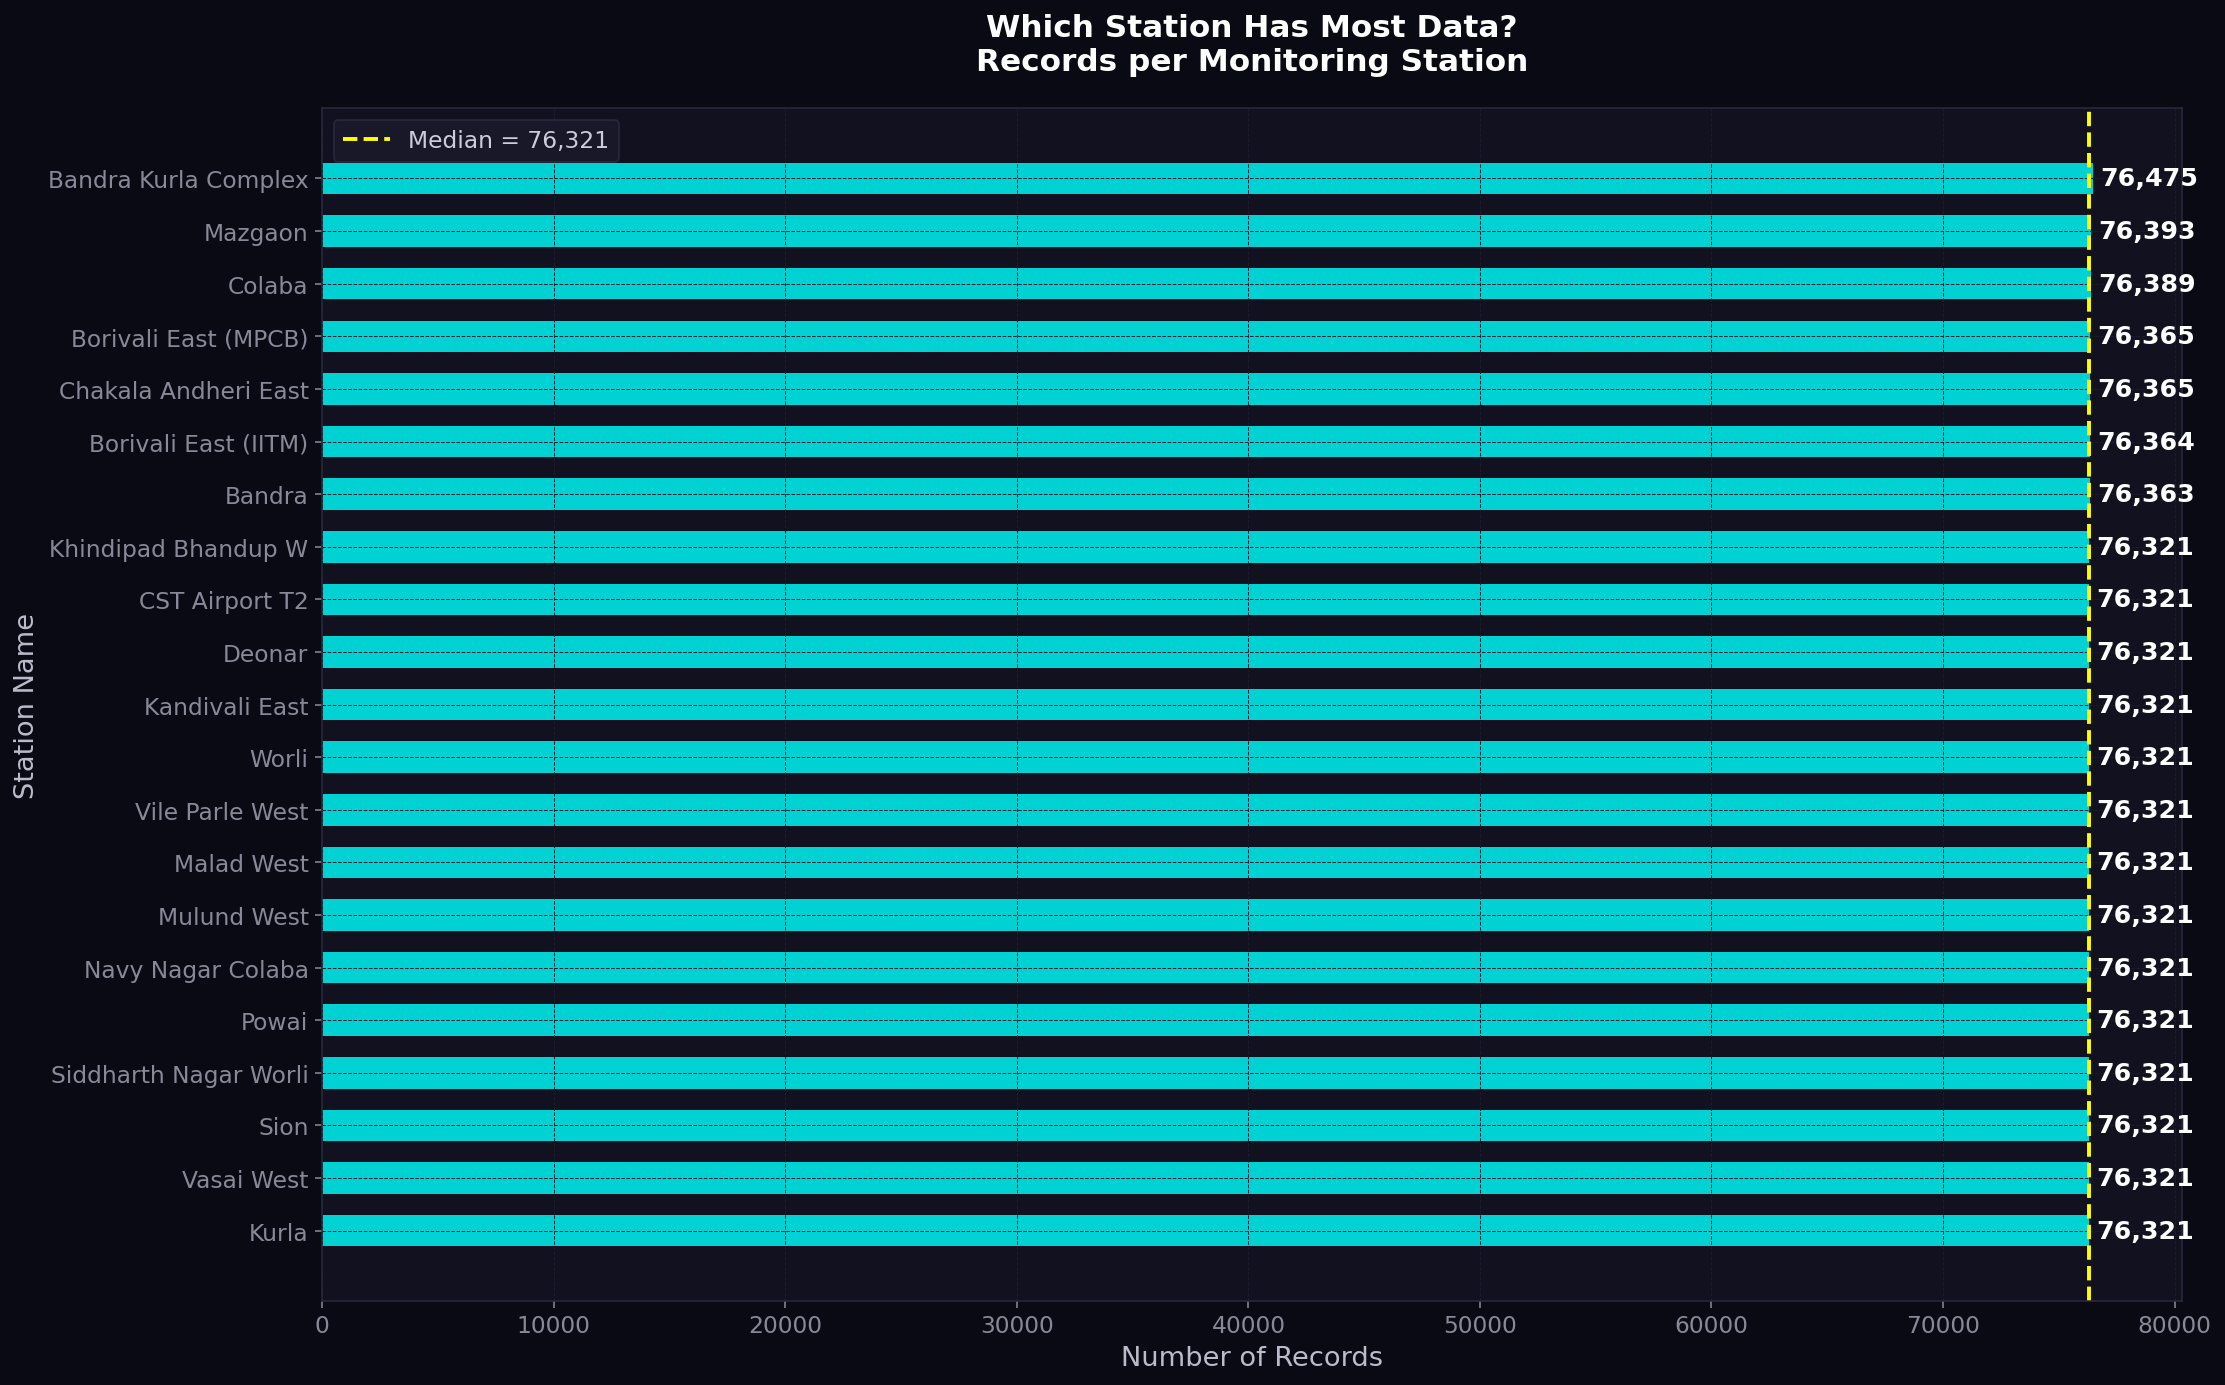

In [7]:
fig, ax = plt.subplots(figsize=(16, 10))  # big size

rec = df.groupby('Station').size().sort_values()

ax.barh(rec.index, rec.values, color='#00d2d3', edgecolor='none', height=0.6)

# big font labels on each bar
for i, (station, v) in enumerate(rec.items()):
    ax.text(v + 300, i, f'{v:,}', va='center', fontsize=13, color='white', fontweight='bold')

ax.axvline(rec.median(), color='yellow', ls='--', lw=2, label=f'Median = {rec.median():,.0f}')

ax.set_xlabel('Number of Records', fontsize=14)
ax.set_ylabel('Station Name', fontsize=14)
ax.set_title('Which Station Has Most Data?\nRecords per Monitoring Station', 
             fontsize=16, color='white', pad=20)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)  # bigger tick labels

plt.tight_layout()
plt.savefig('chart_4A_station_records.png', dpi=150, bbox_inches='tight')
plt.show()

 Records per Year 

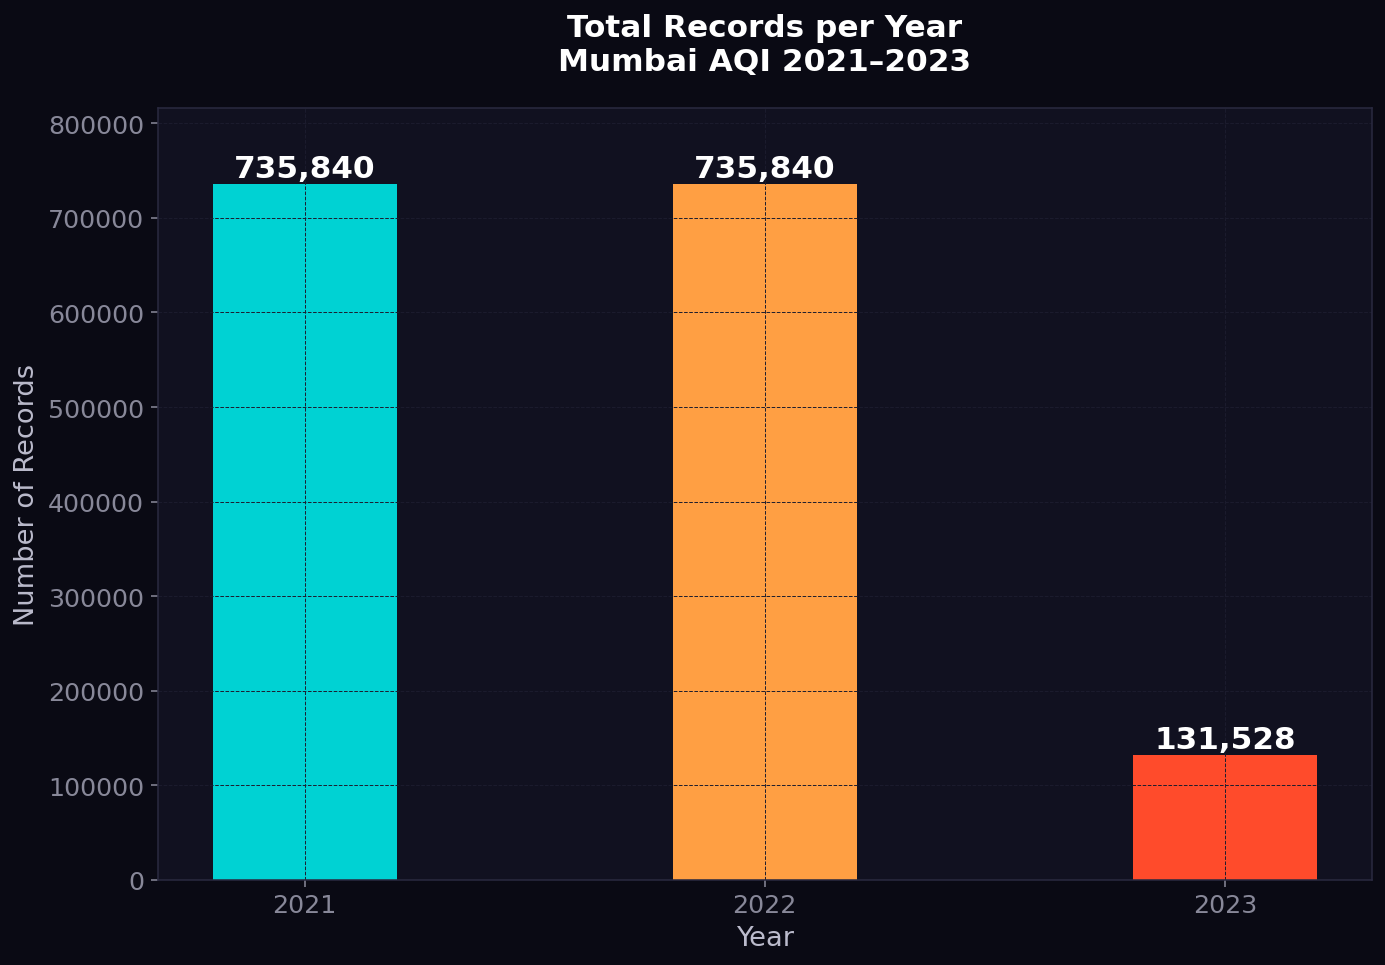

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))

yr_cnt = df.groupby('Year').size()

bars = ax.bar(
    yr_cnt.index.astype(str),
    yr_cnt.values,
    color=['#00d2d3', '#ff9f43', '#ff4b2b'],
    edgecolor='none',
    width=0.4
)

# big number on top
for bar in bars:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        h + 8000,
        f'{h:,.0f}',
        ha='center', fontsize=16, color='white', fontweight='bold'
    )

ax.set_xlabel('Year', fontsize=14)
ax.set_ylabel('Number of Records', fontsize=14)
ax.set_title('Total Records per Year\nMumbai AQI 2021–2023', 
             fontsize=16, color='white', pad=20)
ax.tick_params(axis='both', labelsize=13)
ax.set_ylim(0, yr_cnt.max() + 80000)

plt.tight_layout()
plt.savefig('chart_4B_year_records.png', dpi=150, bbox_inches='tight')
plt.show()

PM2.5 Yearly Trend

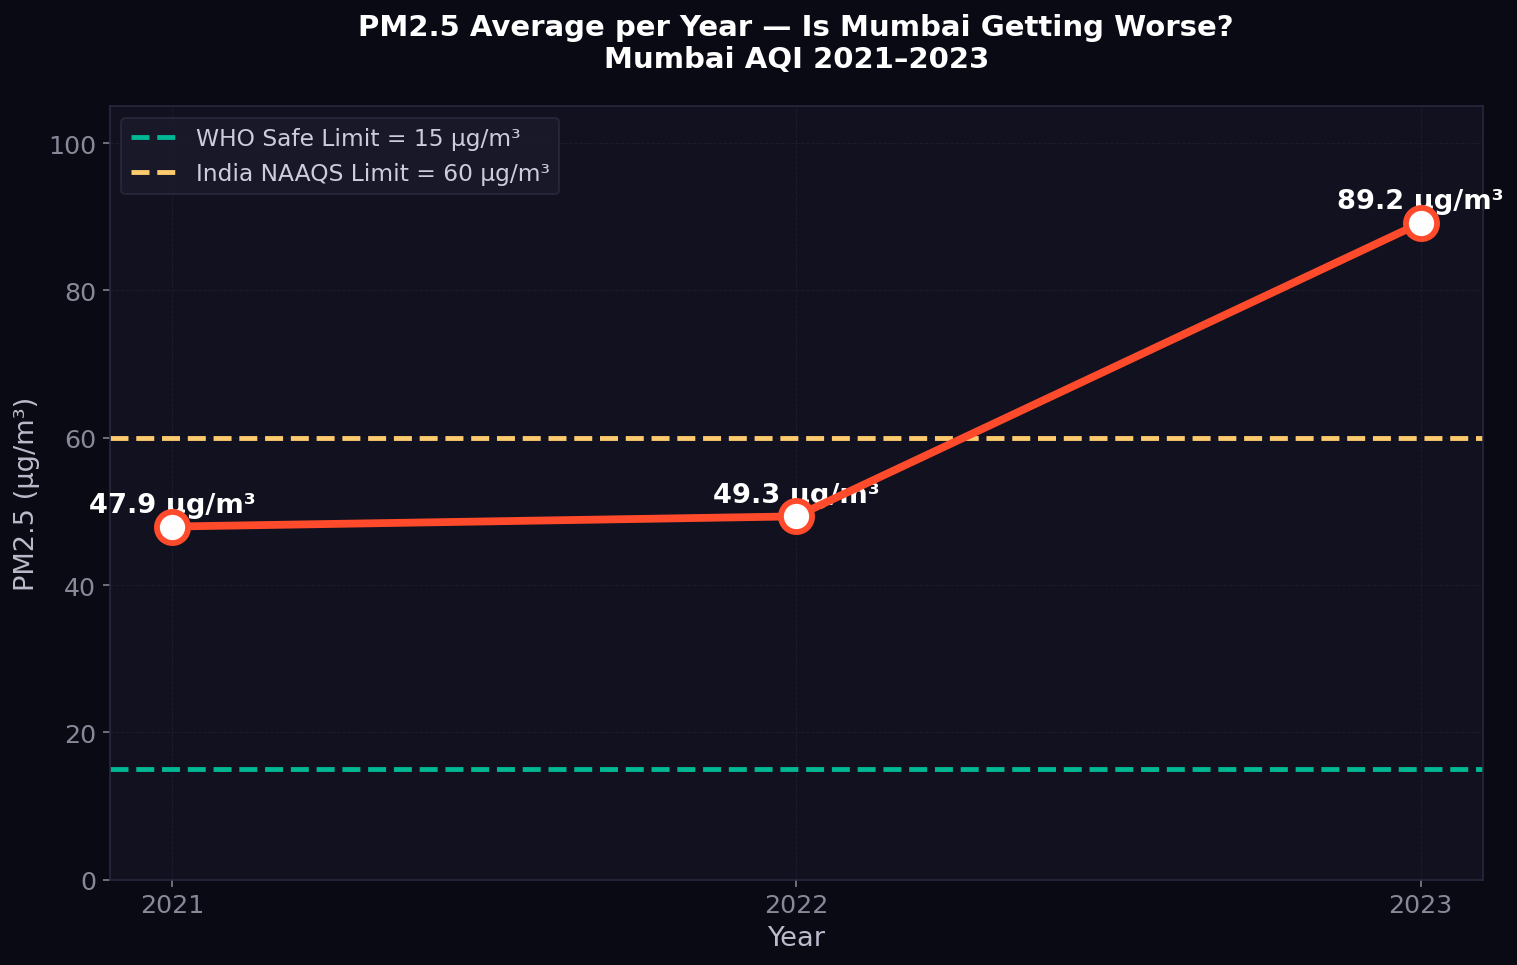

In [11]:
fig, ax = plt.subplots(figsize=(11, 7))

yr_pm25 = df.groupby('Year')['PM2.5'].mean()

ax.plot(
    yr_pm25.index.astype(str),
    yr_pm25.values,
    color='#ff4b2b',
    linewidth=4,
    marker='o',
    markersize=16,
    markerfacecolor='white',
    markeredgecolor='#ff4b2b',
    markeredgewidth=3,
    zorder=5
)

# value on each point
for yr, val in yr_pm25.items():
    ax.text(str(yr), val + 2,
            f'{val:.1f} μg/m³',
            ha='center', fontsize=14, color='white', fontweight='bold')

ax.axhline(15, color='#00b894', ls='--', lw=2.5, label='WHO Safe Limit = 15 μg/m³')
ax.axhline(60, color='#fdcb6e', ls='--', lw=2.5, label='India NAAQS Limit = 60 μg/m³')

ax.set_xlabel('Year', fontsize=14)
ax.set_ylabel('PM2.5 (μg/m³)', fontsize=14)
ax.set_title('PM2.5 Average per Year — Is Mumbai Getting Worse?\nMumbai AQI 2021–2023',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=13)
ax.set_ylim(0, 105)

plt.tight_layout()
plt.savefig('chart_4C_pm25_trend.png', dpi=150, bbox_inches='tight')
plt.show()

How Many Times Worse Than WHO?

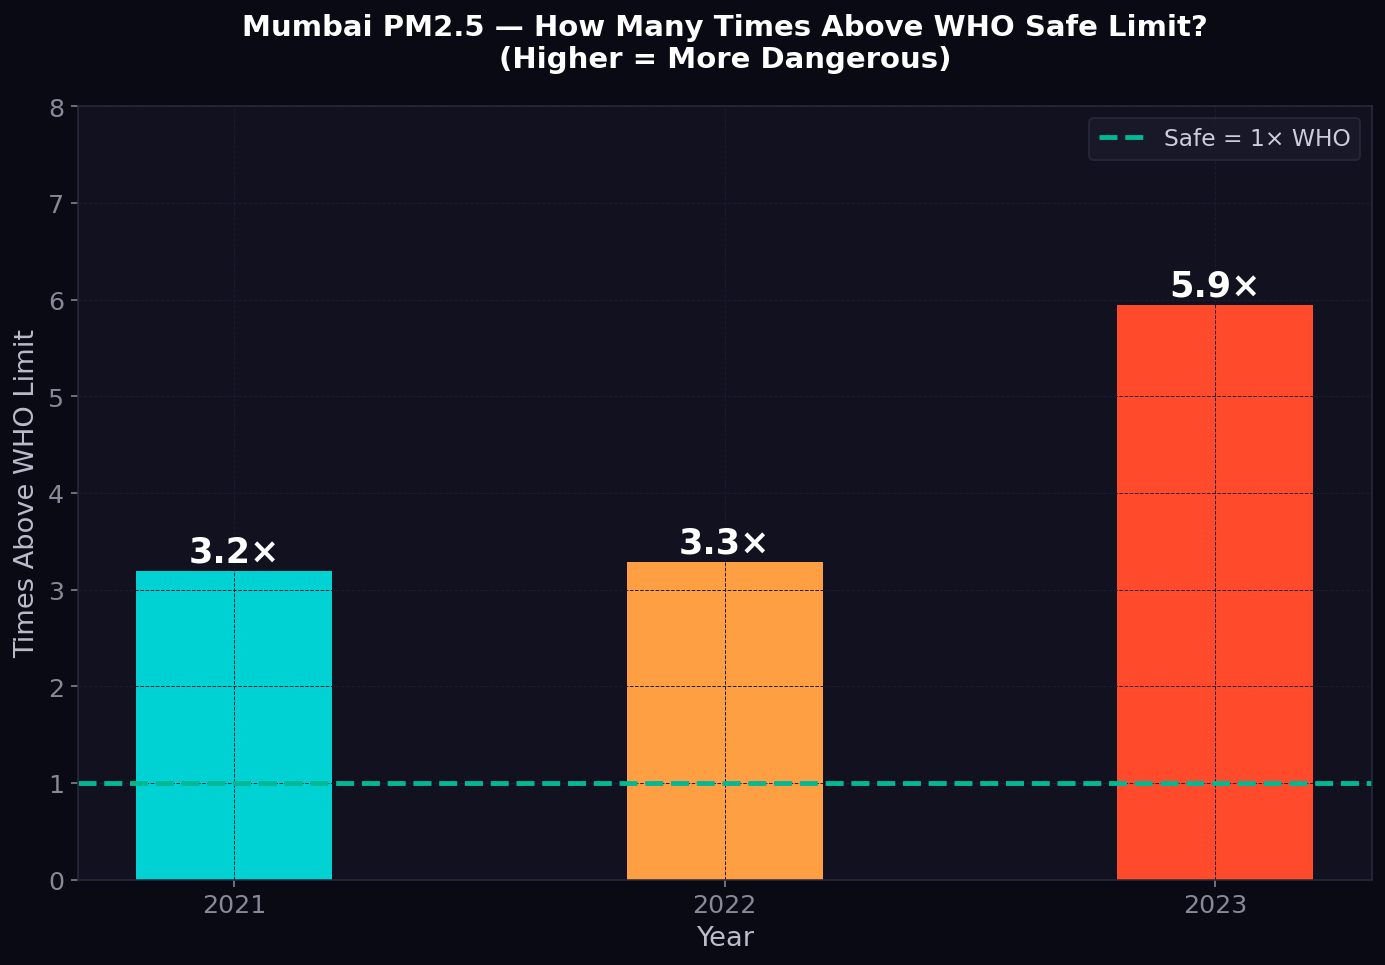

In [13]:
fig, ax = plt.subplots(figsize=(10, 7))

who_limit   = 15
yr_pm25     = df.groupby('Year')['PM2.5'].mean()
times_worse = yr_pm25 / who_limit

bars = ax.bar(
    times_worse.index.astype(str),
    times_worse.values,
    color=['#00d2d3', '#ff9f43', '#ff4b2b'],
    edgecolor='none',
    width=0.4
)

for bar, v in zip(bars, times_worse.values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        v + 0.1,
        f'{v:.1f}×',
        ha='center', fontsize=18, color='white', fontweight='bold'
    )

ax.axhline(1, color='#00b894', ls='--', lw=2.5, label='Safe = 1× WHO')

ax.set_xlabel('Year', fontsize=14)
ax.set_ylabel('Times Above WHO Limit', fontsize=14)
ax.set_title('Mumbai PM2.5 — How Many Times Above WHO Safe Limit?\n(Higher = More Dangerous)',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=13)
ax.set_ylim(0, 8)

plt.tight_layout()
plt.savefig('chart_4D_who_times.png', dpi=150, bbox_inches='tight')
plt.show()

CELL 5A — PM2.5 Monthly Trend by Year 


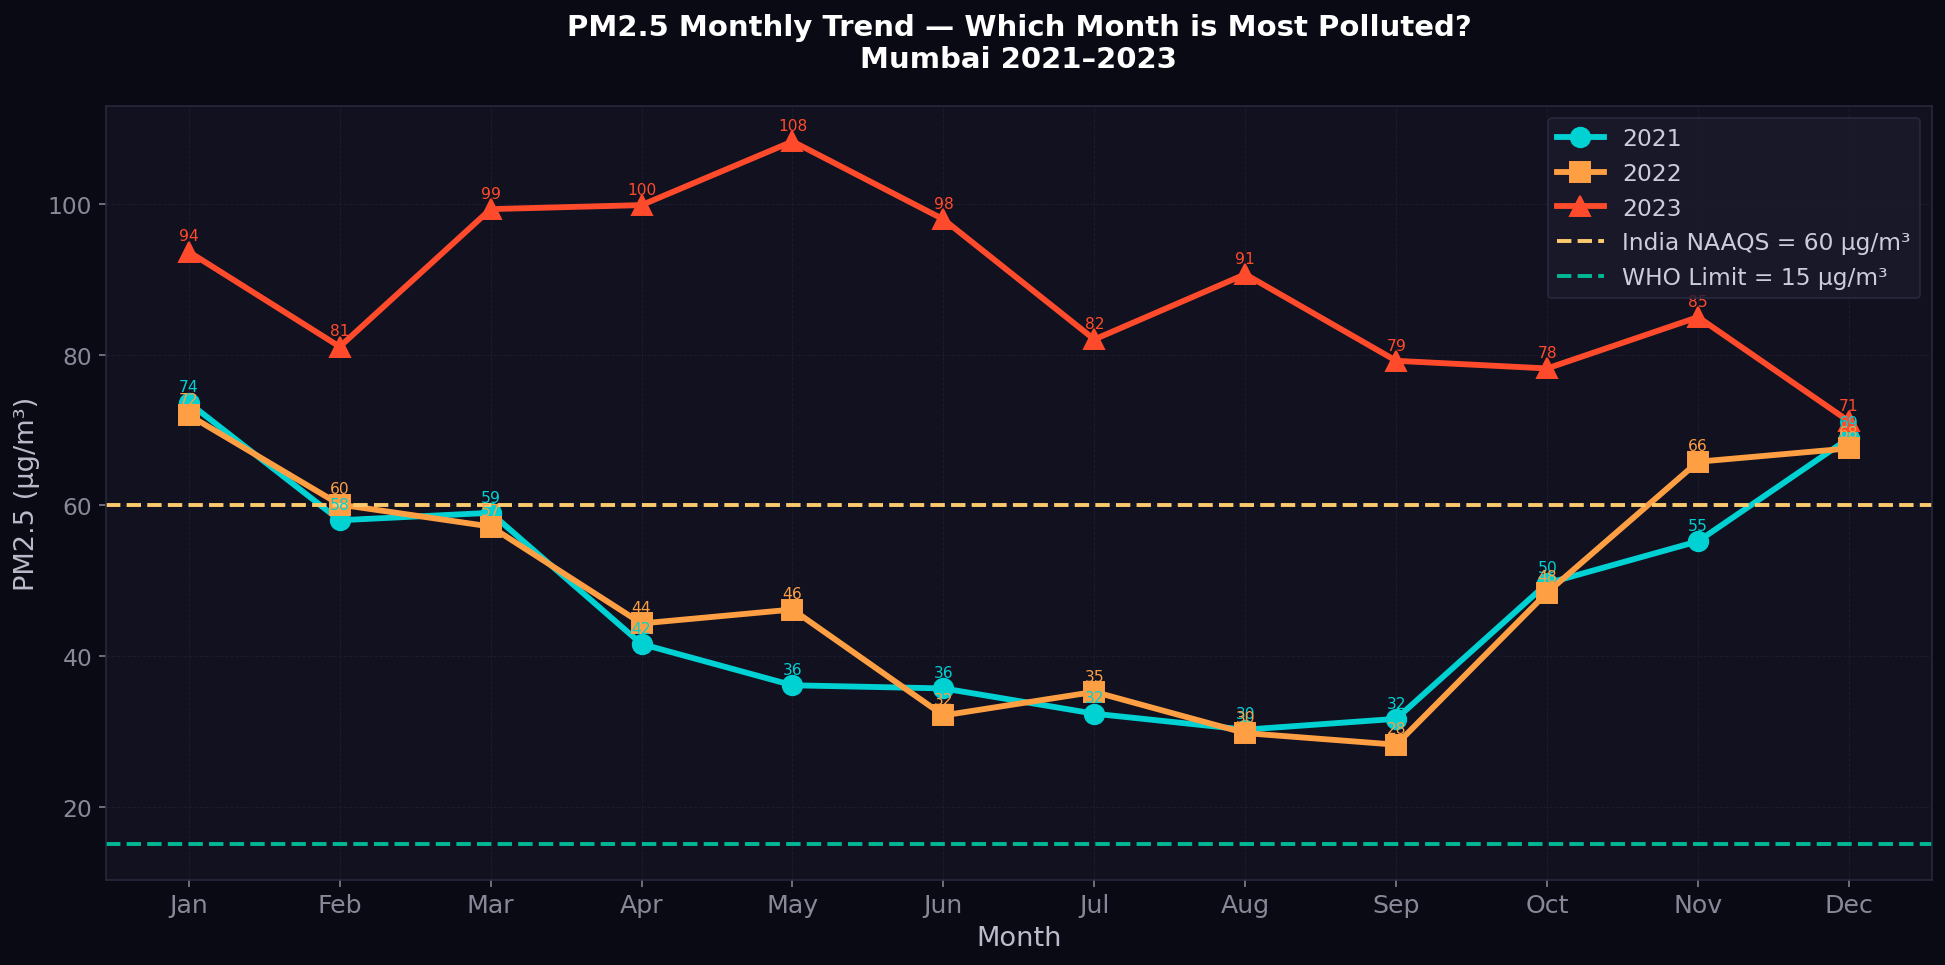

✓ Done — Monthly Trend


In [15]:
fig, ax = plt.subplots(figsize=(14, 7))

MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

for yr, clr, mk in zip([2021, 2022, 2023],
                        ['#00d2d3', '#ff9f43', '#ff4b2b'],
                        ['o', 's', '^']):
    monthly = df[df['Year'] == yr].groupby('Month')['PM2.5'].mean()
    ax.plot(monthly.index, monthly.values,
            color=clr, linewidth=3, marker=mk,
            markersize=10, label=str(yr))
    # value on each point
    for m, v in monthly.items():
        ax.text(m, v + 1.5, f'{v:.0f}', ha='center', fontsize=8, color=clr)

ax.axhline(60, color='#fdcb6e', ls='--', lw=2, label='India NAAQS = 60 μg/m³')
ax.axhline(15, color='#00b894', ls='--', lw=2, label='WHO Limit = 15 μg/m³')

ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS, fontsize=13)
ax.set_xlabel('Month', fontsize=14)
ax.set_ylabel('PM2.5 (μg/m³)', fontsize=14)
ax.set_title('PM2.5 Monthly Trend — Which Month is Most Polluted?\nMumbai 2021–2023',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12)
ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.savefig('chart_5A_monthly_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Monthly Trend")

PM2.5 by Season


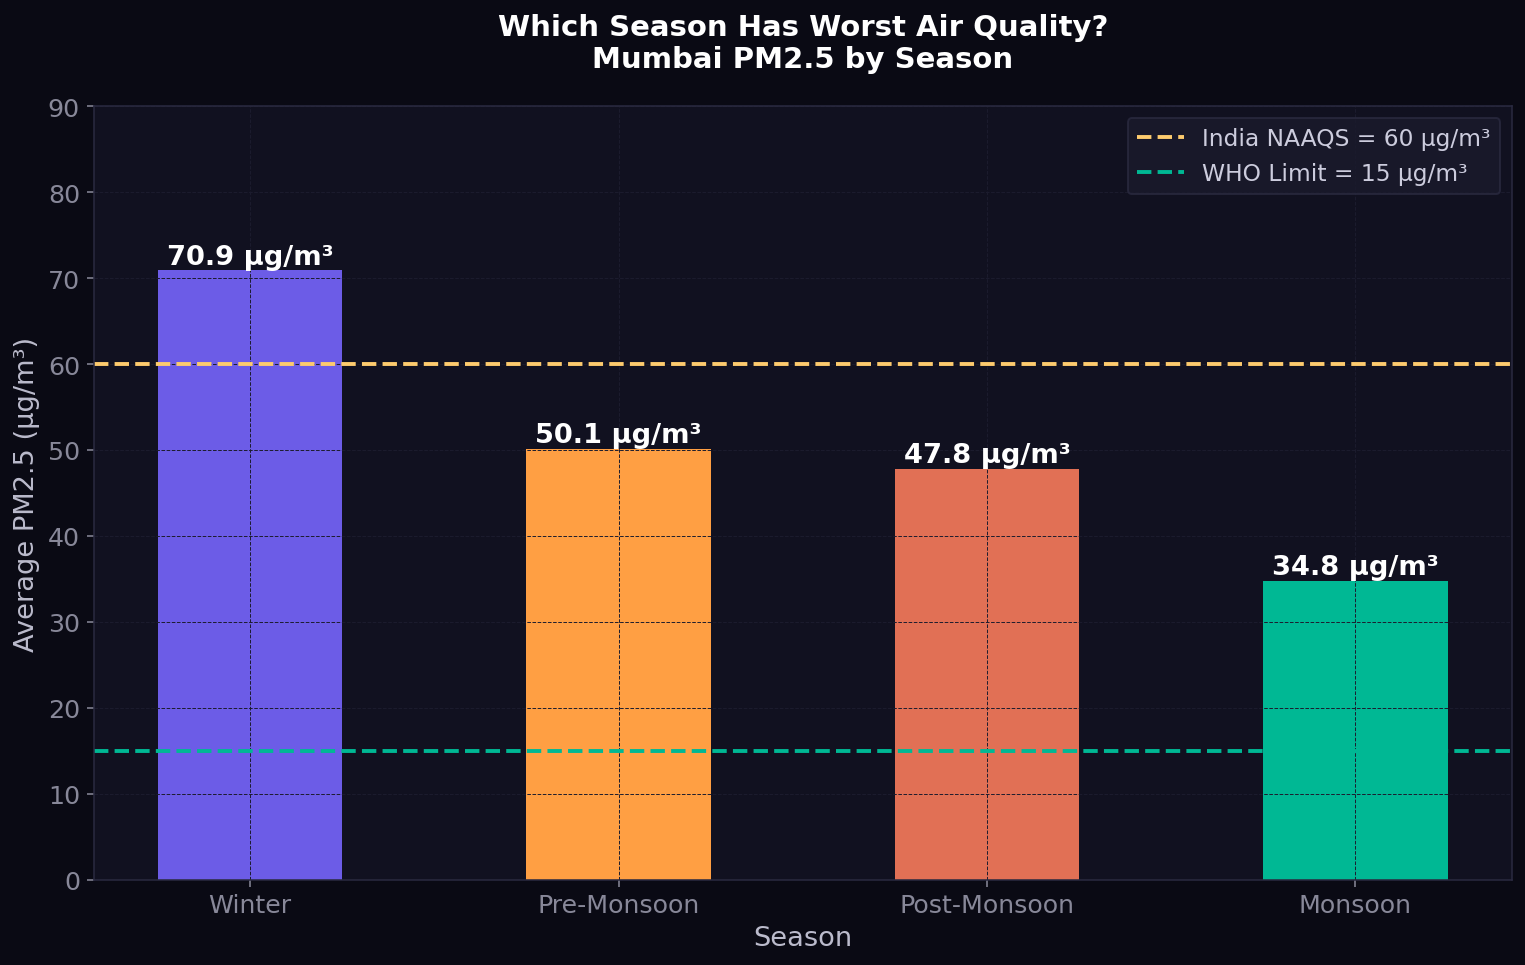

✓ Done — Season Chart


In [17]:
fig, ax = plt.subplots(figsize=(11, 7))

season_order  = ['Winter', 'Pre-Monsoon', 'Post-Monsoon', 'Monsoon']
season_colors = ['#6c5ce7', '#ff9f43', '#e17055', '#00b894']

sea_avg = df.groupby('Season')['PM2.5'].mean().reindex(season_order)

bars = ax.bar(sea_avg.index, sea_avg.values,
              color=season_colors, edgecolor='none', width=0.5)

for bar, v in zip(bars, sea_avg.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + 0.8,
            f'{v:.1f} μg/m³',
            ha='center', fontsize=14, color='white', fontweight='bold')

ax.axhline(60, color='#fdcb6e', ls='--', lw=2, label='India NAAQS = 60 μg/m³')
ax.axhline(15, color='#00b894', ls='--', lw=2, label='WHO Limit = 15 μg/m³')

ax.set_xlabel('Season', fontsize=14)
ax.set_ylabel('Average PM2.5 (μg/m³)', fontsize=14)
ax.set_title('Which Season Has Worst Air Quality?\nMumbai PM2.5 by Season',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=13)
ax.set_ylim(0, 90)

plt.tight_layout()
plt.savefig('chart_5B_season.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Season Chart")

 PM2.5 by Hour of Day
 

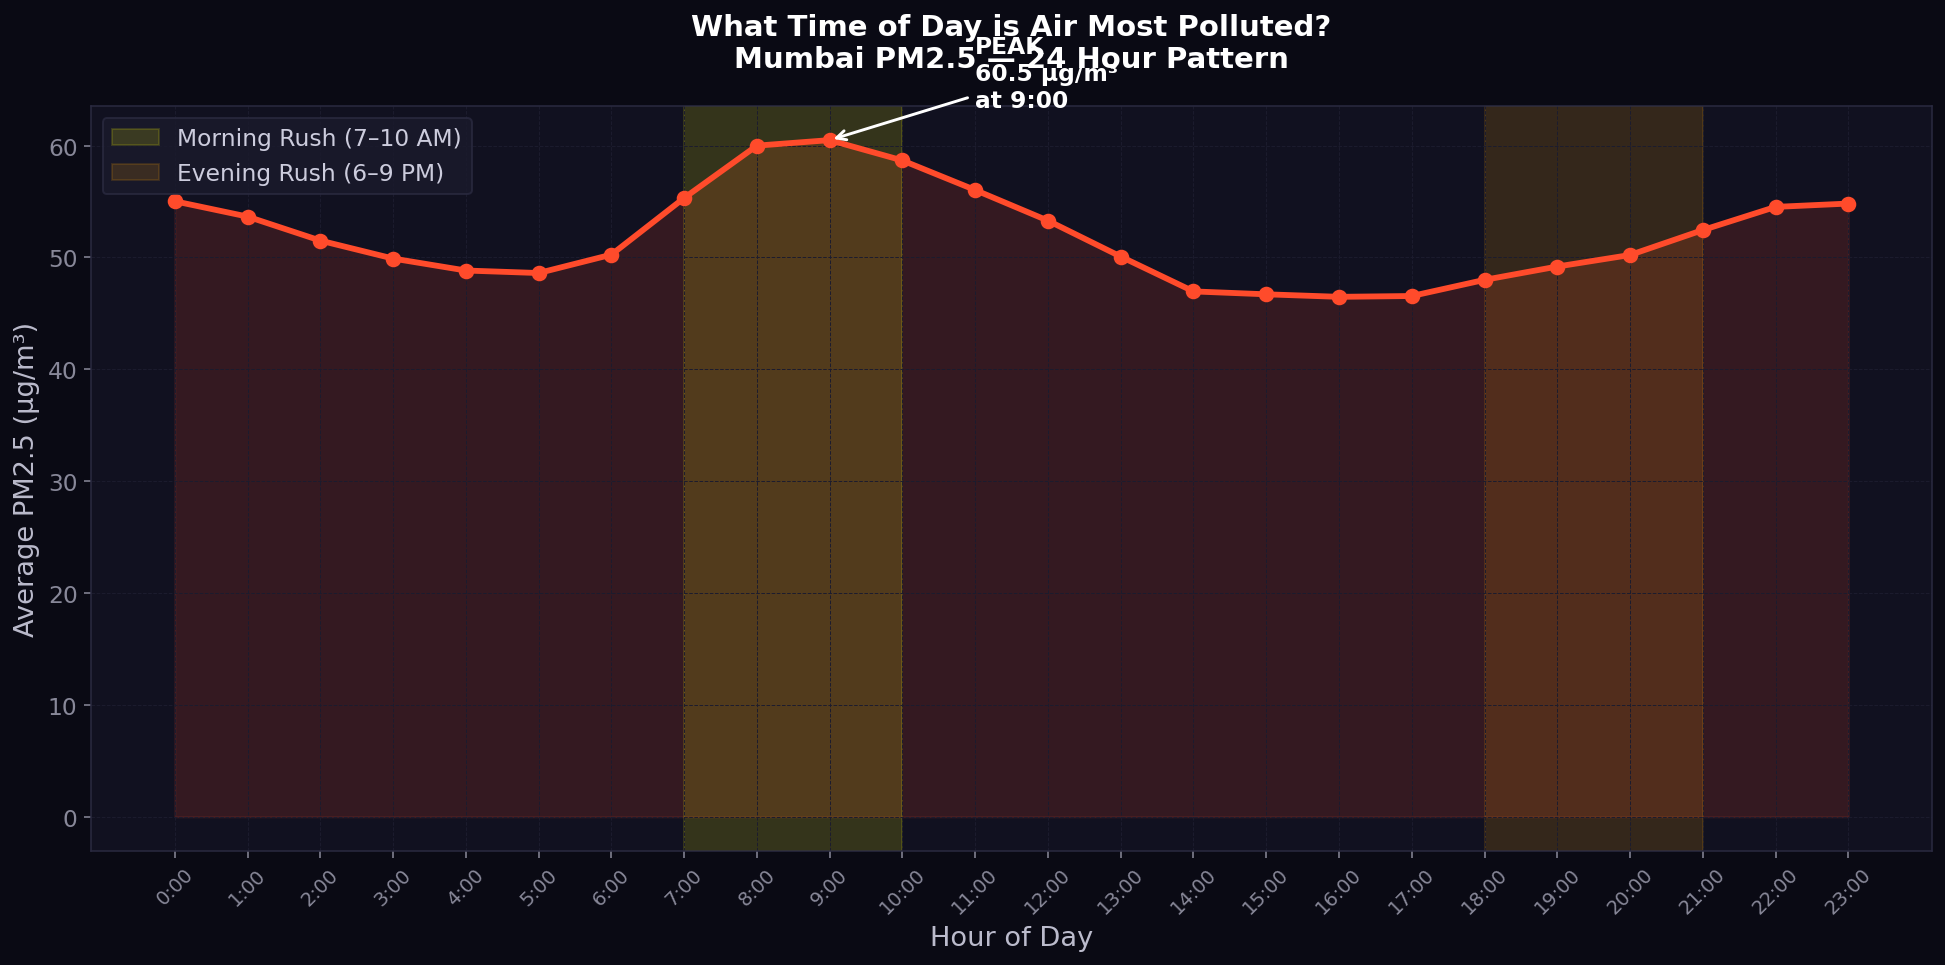

✓ Done — Hourly Pattern


In [19]:
fig, ax = plt.subplots(figsize=(14, 7))

hourly = df.groupby('Hour')['PM2.5'].mean()

ax.fill_between(hourly.index, hourly.values, alpha=0.15, color='#ff4b2b')
ax.plot(hourly.index, hourly.values,
        color='#ff4b2b', linewidth=3,
        marker='o', markersize=7)

# highlight rush hours
ax.axvspan(7, 10, alpha=0.15, color='yellow', label='Morning Rush (7–10 AM)')
ax.axvspan(18, 21, alpha=0.15, color='orange', label='Evening Rush (6–9 PM)')

# peak label
peak_hr  = hourly.idxmax()
peak_val = hourly.max()
ax.annotate(f'PEAK\n{peak_val:.1f} μg/m³\nat {peak_hr}:00',
            xy=(peak_hr, peak_val),
            xytext=(peak_hr + 2, peak_val + 3),
            fontsize=12, color='white', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='white', lw=1.5))

ax.set_xticks(range(0, 24))
ax.set_xticklabels([f'{h}:00' for h in range(24)], rotation=45, fontsize=10)
ax.set_xlabel('Hour of Day', fontsize=14)
ax.set_ylabel('Average PM2.5 (μg/m³)', fontsize=14)
ax.set_title('What Time of Day is Air Most Polluted?\nMumbai PM2.5 — 24 Hour Pattern',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12)
ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.savefig('chart_5C_hourly.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Hourly Pattern")

 PM2.5 by Day of Week
 

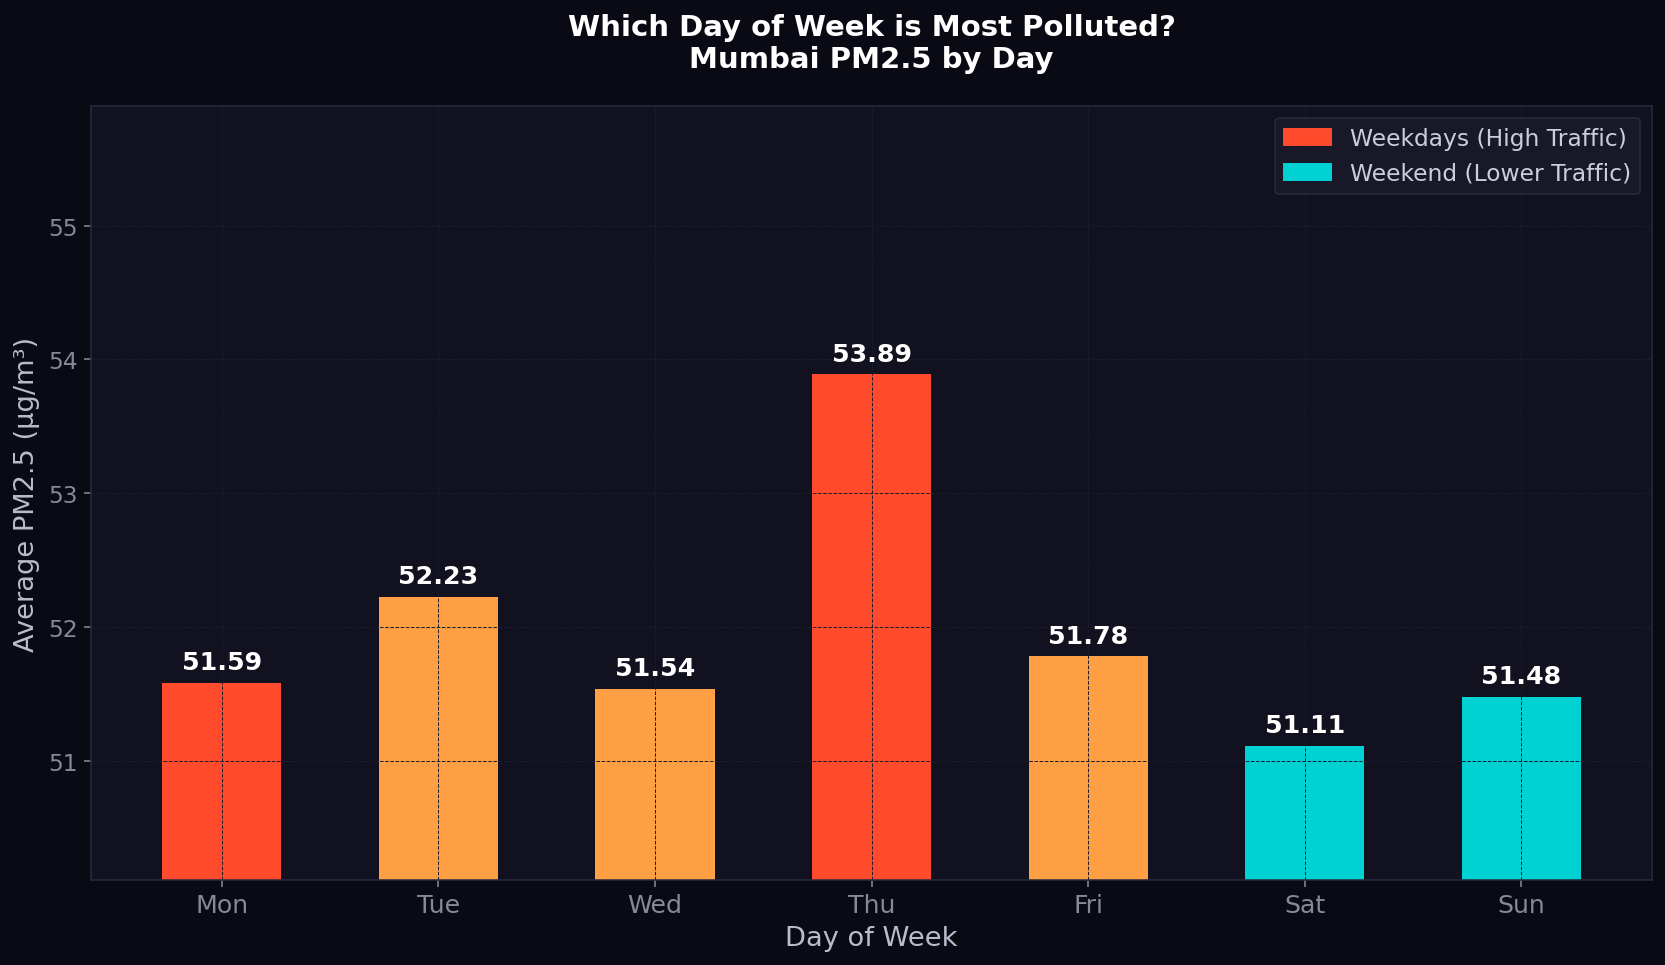

✓ Done — Day of Week


In [21]:
fig, ax = plt.subplots(figsize=(12, 7))

day_order  = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
day_colors = ['#ff4b2b','#ff9f43','#ff9f43','#ff4b2b','#ff9f43','#00d2d3','#00d2d3']

dow = df.groupby('DayOfWeek')['PM2.5'].mean().reindex(day_order)

bars = ax.bar(range(7), dow.values,
              color=day_colors, edgecolor='none', width=0.55)

for bar, v in zip(bars, dow.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + 0.1,
            f'{v:.2f}',
            ha='center', fontsize=13, color='white', fontweight='bold')

ax.set_xticks(range(7))
ax.set_xticklabels(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'], fontsize=13)
ax.set_xlabel('Day of Week', fontsize=14)
ax.set_ylabel('Average PM2.5 (μg/m³)', fontsize=14)
ax.set_title('Which Day of Week is Most Polluted?\nMumbai PM2.5 by Day',
             fontsize=15, color='white', pad=20)

import matplotlib.patches as mpatches
patches = [
    mpatches.Patch(color='#ff4b2b', label='Weekdays (High Traffic)'),
    mpatches.Patch(color='#00d2d3', label='Weekend (Lower Traffic)'),
]
ax.legend(handles=patches, fontsize=12)
ax.tick_params(axis='y', labelsize=12)
ax.set_ylim(dow.min() - 1, dow.max() + 2)

plt.tight_layout()
plt.savefig('chart_5D_day_of_week.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Day of Week")

Top 12 Worst Weeks


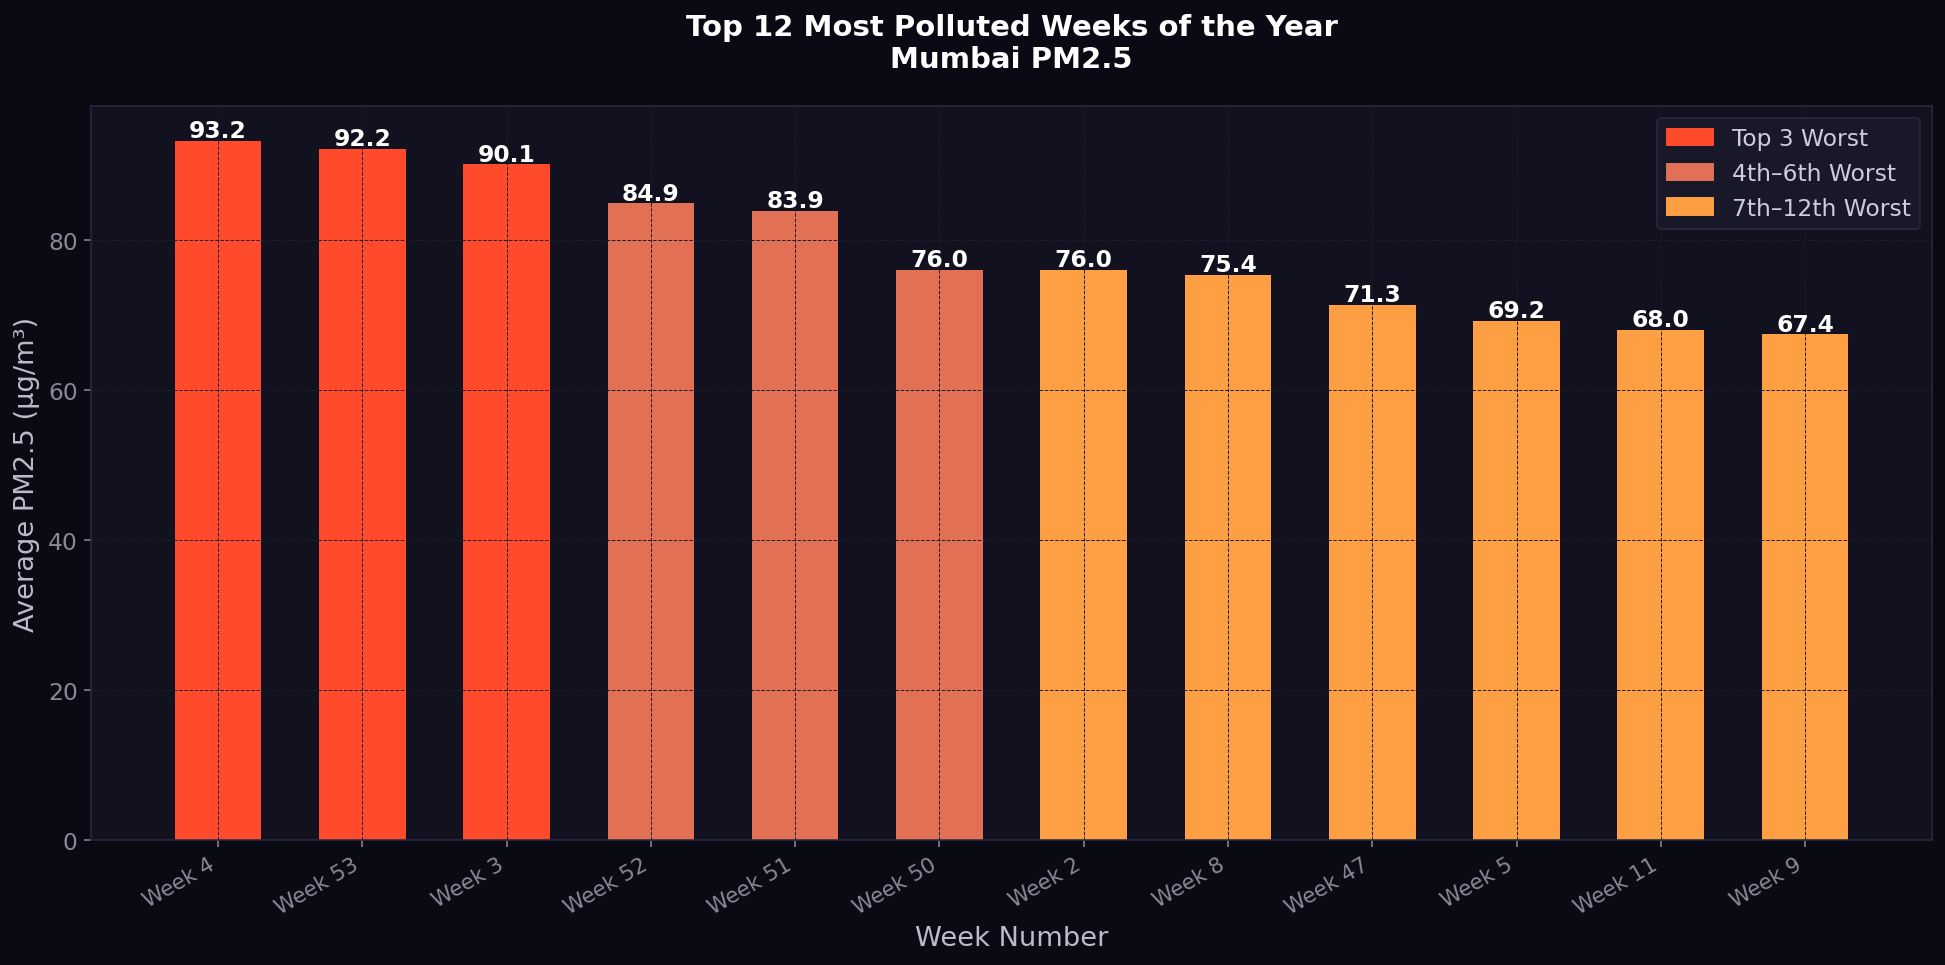

✓ Done — Worst Weeks


In [23]:
fig, ax = plt.subplots(figsize=(14, 7))

worst_weeks = (df.groupby('Week')['PM2.5']
               .mean()
               .sort_values(ascending=False)
               .head(12))

bar_colors = ['#ff4b2b' if i < 3 else
              '#e17055' if i < 6 else
              '#ff9f43'
              for i in range(12)]

bars = ax.bar(range(12), worst_weeks.values,
              color=bar_colors, edgecolor='none', width=0.6)

for bar, v in zip(bars, worst_weeks.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + 0.5,
            f'{v:.1f}',
            ha='center', fontsize=12, color='white', fontweight='bold')

ax.set_xticks(range(12))
ax.set_xticklabels([f'Week {w}' for w in worst_weeks.index],
                   rotation=30, ha='right', fontsize=11)
ax.set_xlabel('Week Number', fontsize=14)
ax.set_ylabel('Average PM2.5 (μg/m³)', fontsize=14)
ax.set_title('Top 12 Most Polluted Weeks of the Year\nMumbai PM2.5',
             fontsize=15, color='white', pad=20)

import matplotlib.patches as mpatches
patches = [
    mpatches.Patch(color='#ff4b2b', label='Top 3 Worst'),
    mpatches.Patch(color='#e17055', label='4th–6th Worst'),
    mpatches.Patch(color='#ff9f43', label='7th–12th Worst'),
]
ax.legend(handles=patches, fontsize=12)
ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.savefig('chart_5E_worst_weeks.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Worst Weeks")

 PM2.5 Heatmap Year × Month 
 

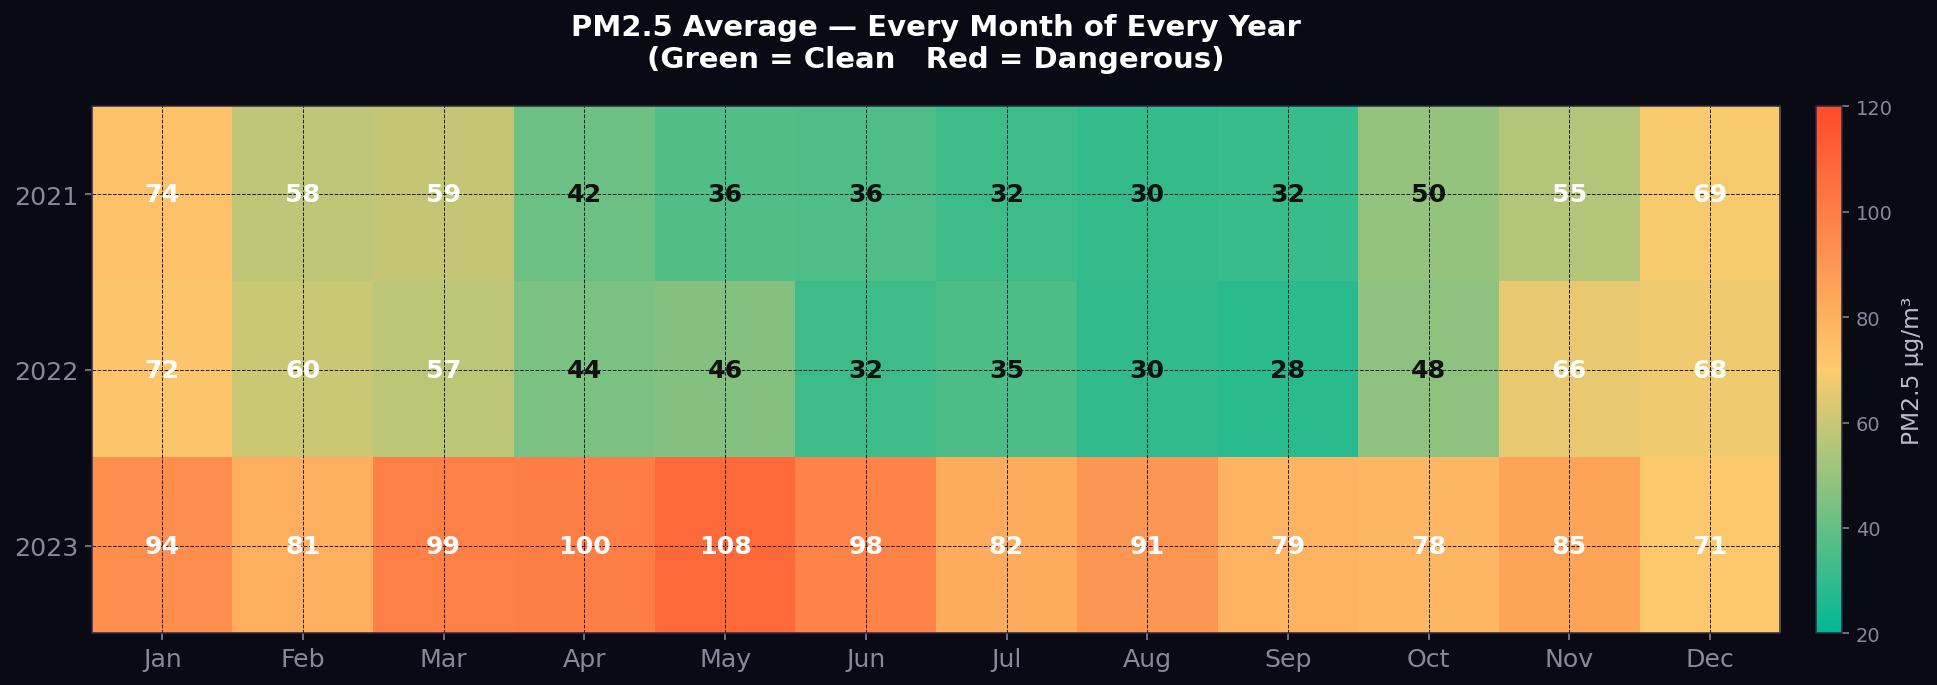

✓ Done — Year × Month Heatmap


In [25]:
from matplotlib.colors import LinearSegmentedColormap

fig, ax = plt.subplots(figsize=(14, 5))

MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

pivot = df.groupby(['Year','Month'])['PM2.5'].mean().unstack()
pivot.columns = MONTHS

cmap = LinearSegmentedColormap.from_list(
    'aqicmap', ['#00b894', '#fdcb6e', '#ff4b2b'], N=256
)

im = ax.imshow(pivot.values, aspect='auto',
               cmap=cmap, vmin=20, vmax=120,
               interpolation='nearest')

ax.set_xticks(range(12))
ax.set_xticklabels(MONTHS, fontsize=13)
ax.set_yticks(range(len(pivot)))
ax.set_yticklabels(pivot.index, fontsize=13)

# value in every cell
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.iloc[i, j]
        if not pd.isna(v):
            ax.text(j, i, f'{v:.0f}',
                    ha='center', va='center',
                    fontsize=13, fontweight='bold',
                    color='white' if v > 55 else '#111111')

cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label('PM2.5 μg/m³', fontsize=12)

ax.set_title('PM2.5 Average — Every Month of Every Year\n(Green = Clean   Red = Dangerous)',
             fontsize=15, color='white', pad=20)

plt.tight_layout()
plt.savefig('chart_5F_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Year × Month Heatmap")

 Top 10 Most Polluted Stations

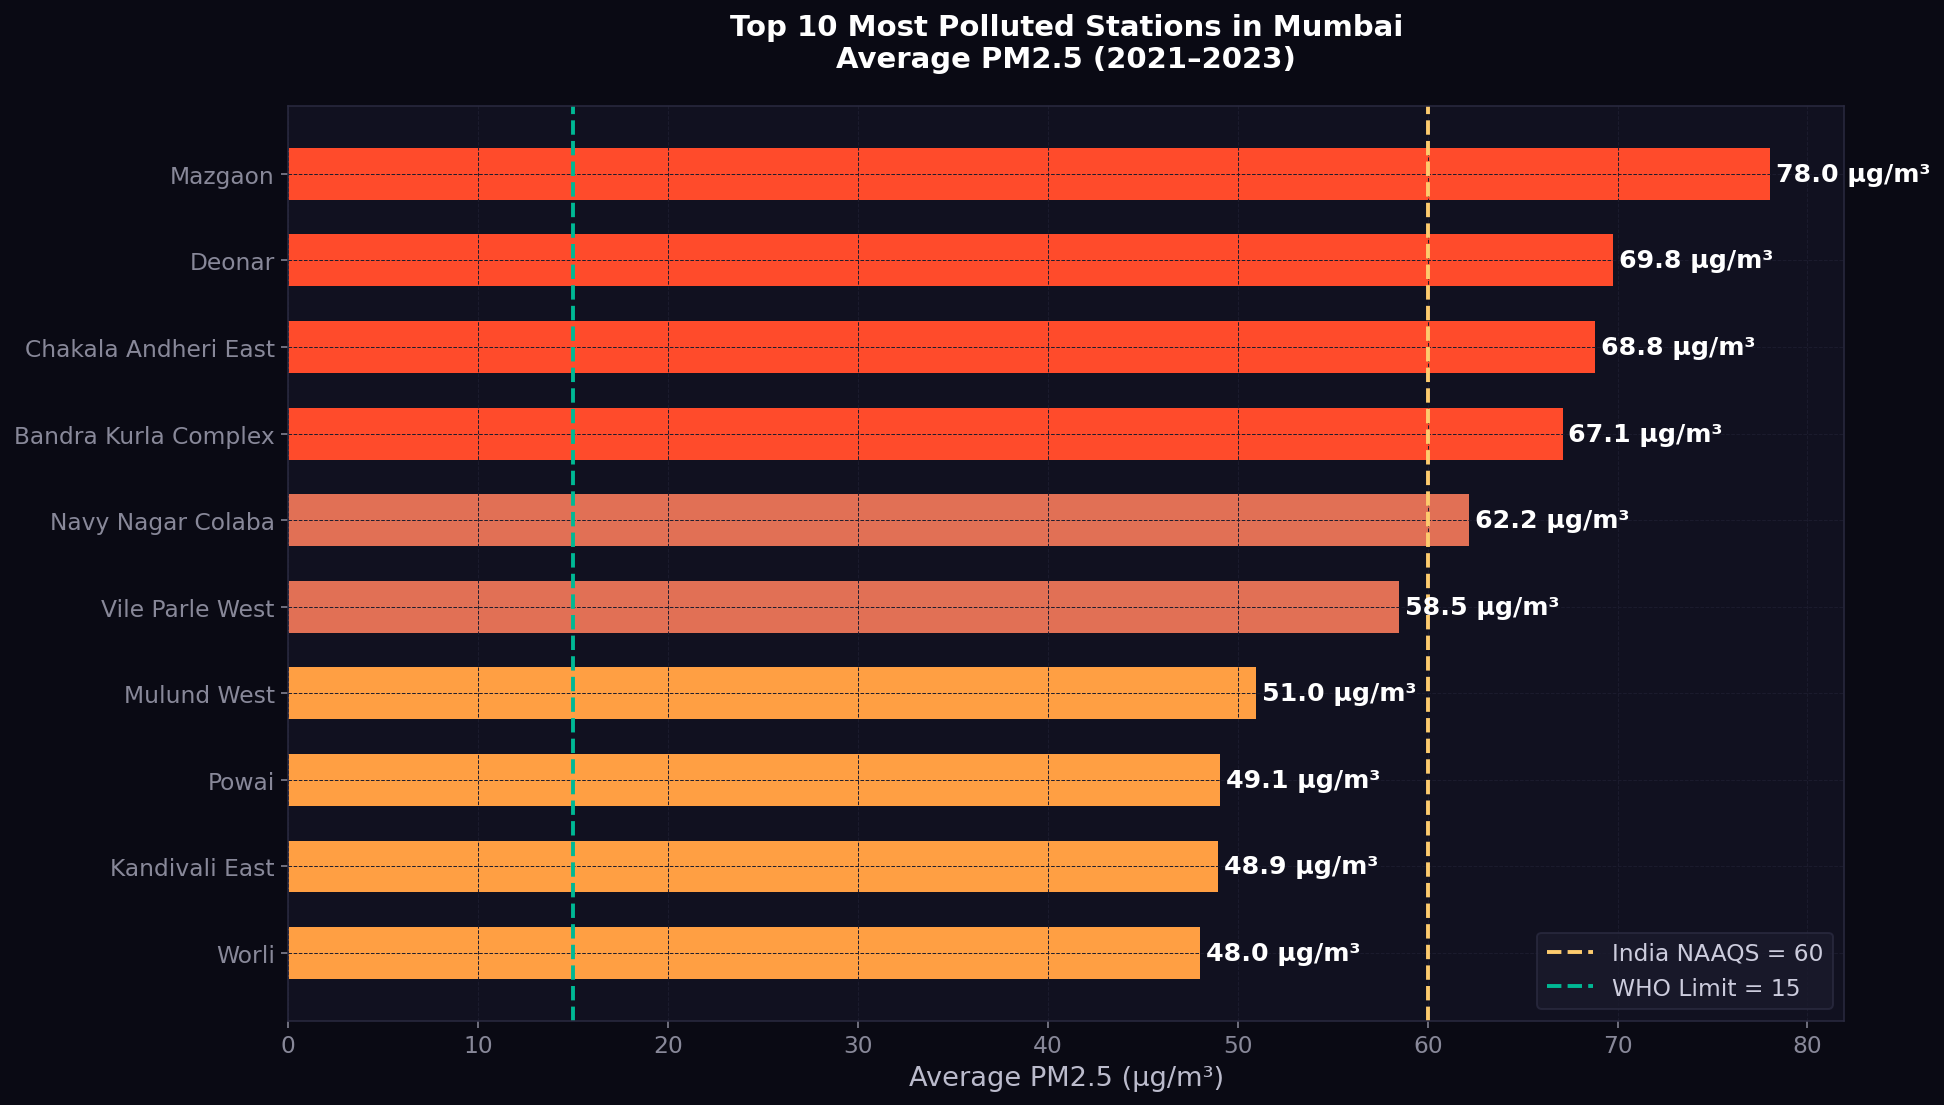

✓ Done — Top 10 Polluted Stations


In [27]:
fig, ax = plt.subplots(figsize=(14, 8))

st_avg = df.groupby('Station')['PM2.5'].mean().sort_values(ascending=False)

top10        = st_avg.head(10)
bar_colors   = ['#ff4b2b' if v > 65 else
                '#e17055' if v > 55 else
                '#ff9f43'
                for v in top10.values]

bars = ax.barh(top10.index[::-1], top10.values[::-1],
               color=bar_colors[::-1], edgecolor='none', height=0.6)

for bar, v in zip(bars, top10.values[::-1]):
    ax.text(v + 0.3, bar.get_y() + bar.get_height()/2,
            f'{v:.1f} μg/m³',
            va='center', fontsize=13, color='white', fontweight='bold')

ax.axvline(60, color='#fdcb6e', ls='--', lw=2, label='India NAAQS = 60')
ax.axvline(15, color='#00b894', ls='--', lw=2, label='WHO Limit = 15')

ax.set_xlabel('Average PM2.5 (μg/m³)', fontsize=14)
ax.set_title('Top 10 Most Polluted Stations in Mumbai\nAverage PM2.5 (2021–2023)',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('chart_6A_top10_stations.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Top 10 Polluted Stations")

All Stations Ranked Best to Worst


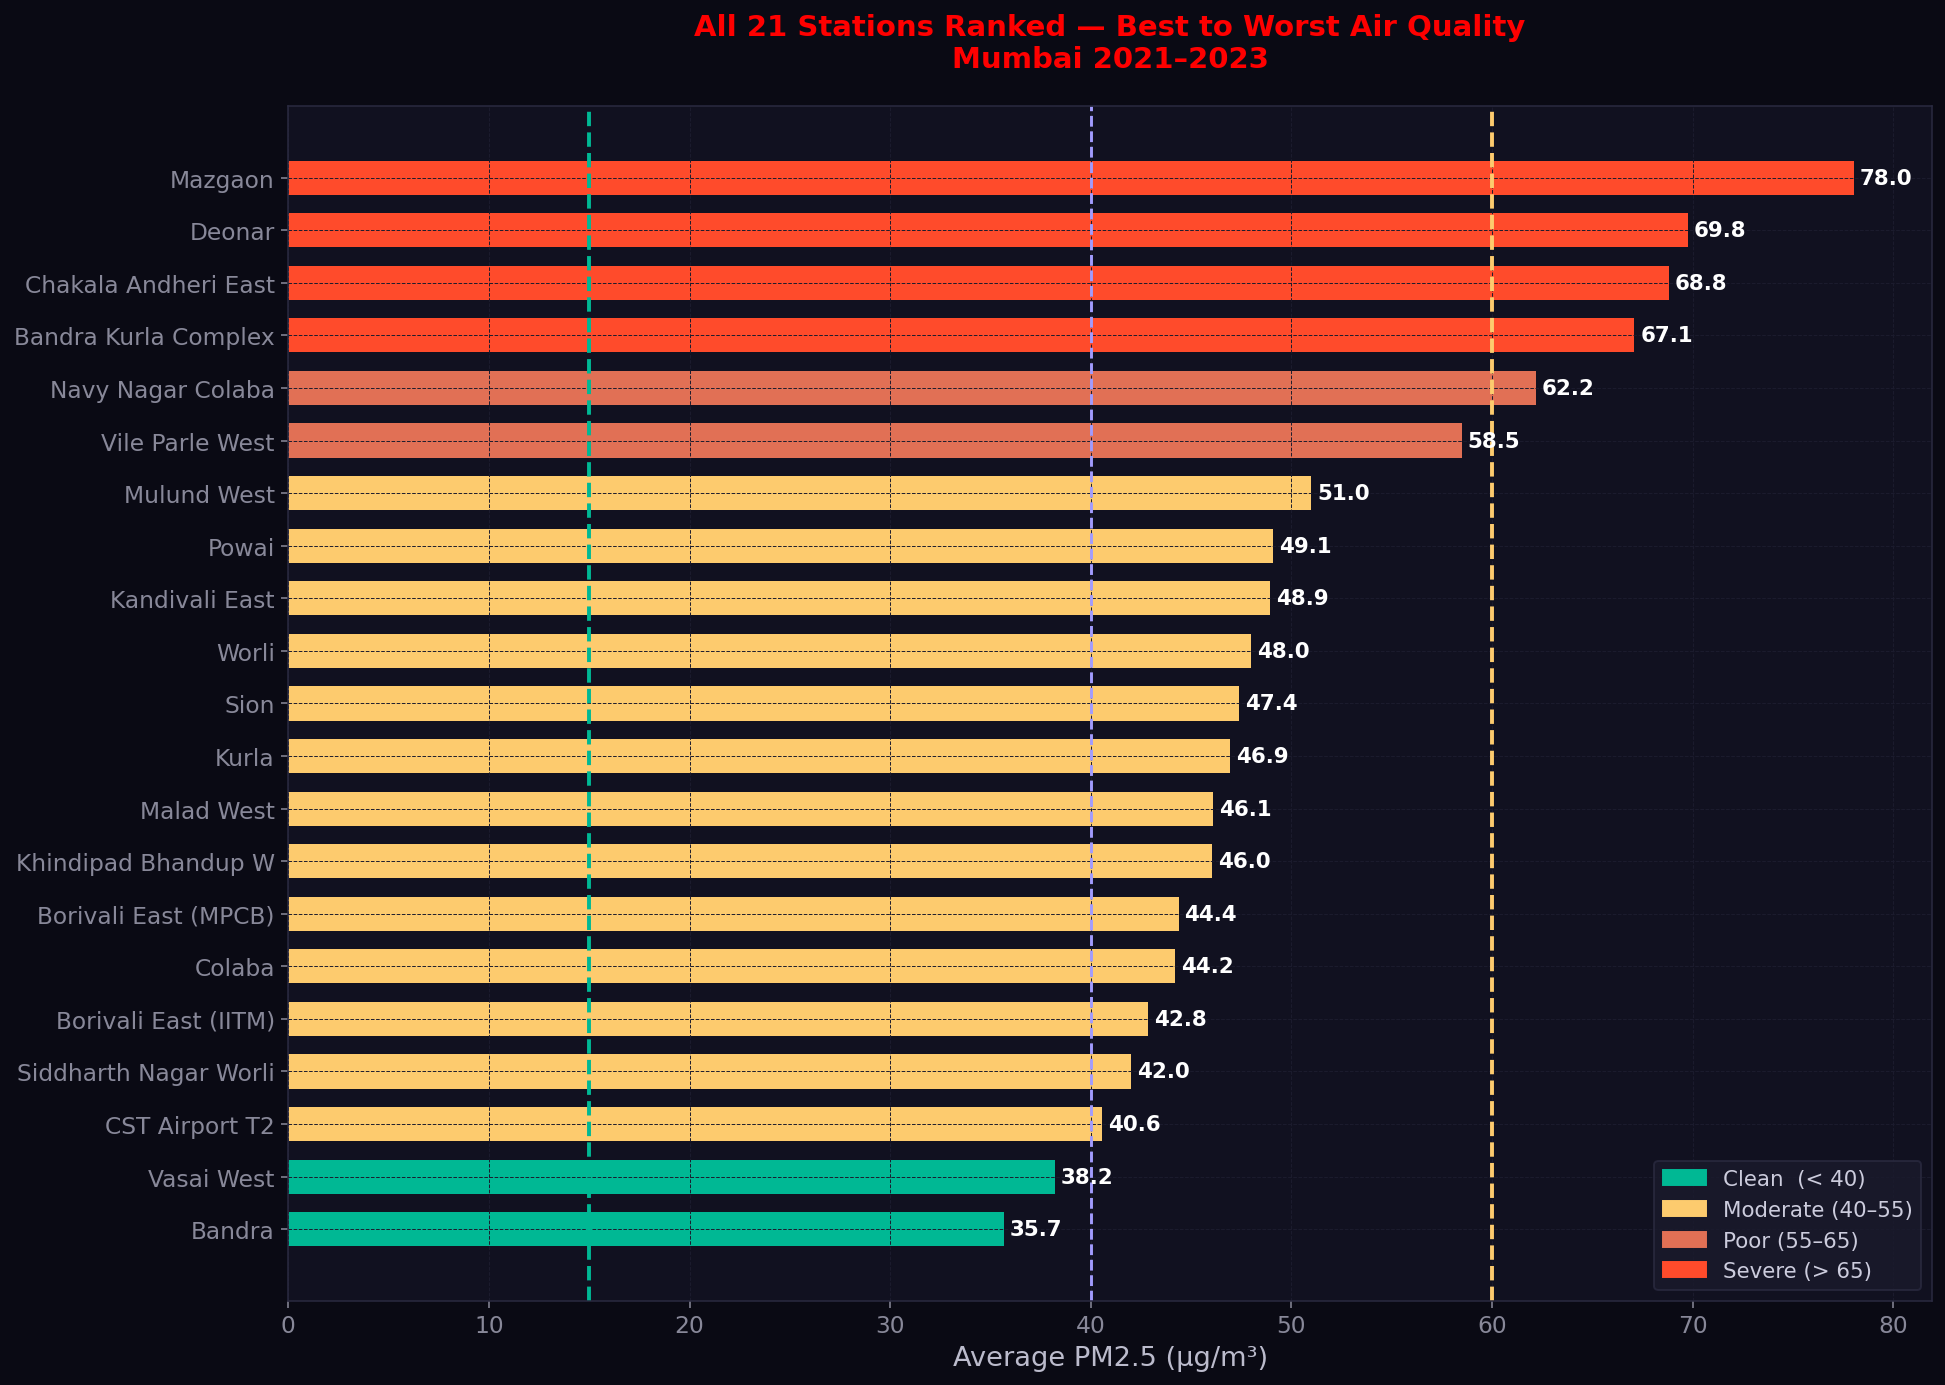

✓ Done — All Stations Ranked


In [29]:
fig, ax = plt.subplots(figsize=(14, 10))

st_avg_all = df.groupby('Station')['PM2.5'].mean().sort_values()

bar_colors = ['#00b894' if v < 40 else
              '#fdcb6e' if v < 55 else
              '#e17055' if v < 65 else
              '#ff4b2b'
              for v in st_avg_all.values]

bars = ax.barh(st_avg_all.index, st_avg_all.values,
               color=bar_colors, edgecolor='none', height=0.65)

for bar, v in zip(bars, st_avg_all.values):
    ax.text(v + 0.3, bar.get_y() + bar.get_height()/2,
            f'{v:.1f}',
            va='center', fontsize=11, color='white', fontweight='bold')

ax.axvline(60, color='#fdcb6e', ls='--', lw=2, label='India NAAQS = 60')
ax.axvline(15, color='#00b894', ls='--', lw=2, label='WHO Limit = 15')
ax.axvline(40, color='#a29bfe', ls='--', lw=1.5, label='India Annual = 40')

import matplotlib.patches as mpatches
patches = [
    mpatches.Patch(color='#00b894', label='Clean  (< 40)'),
    mpatches.Patch(color='#fdcb6e', label='Moderate (40–55)'),
    mpatches.Patch(color='#e17055', label='Poor (55–65)'),
    mpatches.Patch(color='#ff4b2b', label='Severe (> 65)'),
]
ax.legend(handles=patches, fontsize=11, loc='lower right')
ax.set_xlabel('Average PM2.5 (μg/m³)', fontsize=14)
ax.set_title('All 21 Stations Ranked — Best to Worst Air Quality\nMumbai 2021–2023',
             fontsize=15, color='red', pad=20)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('chart_6B_all_stations_ranked.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — All Stations Ranked")

Top 5 Stations PM2.5 by Year


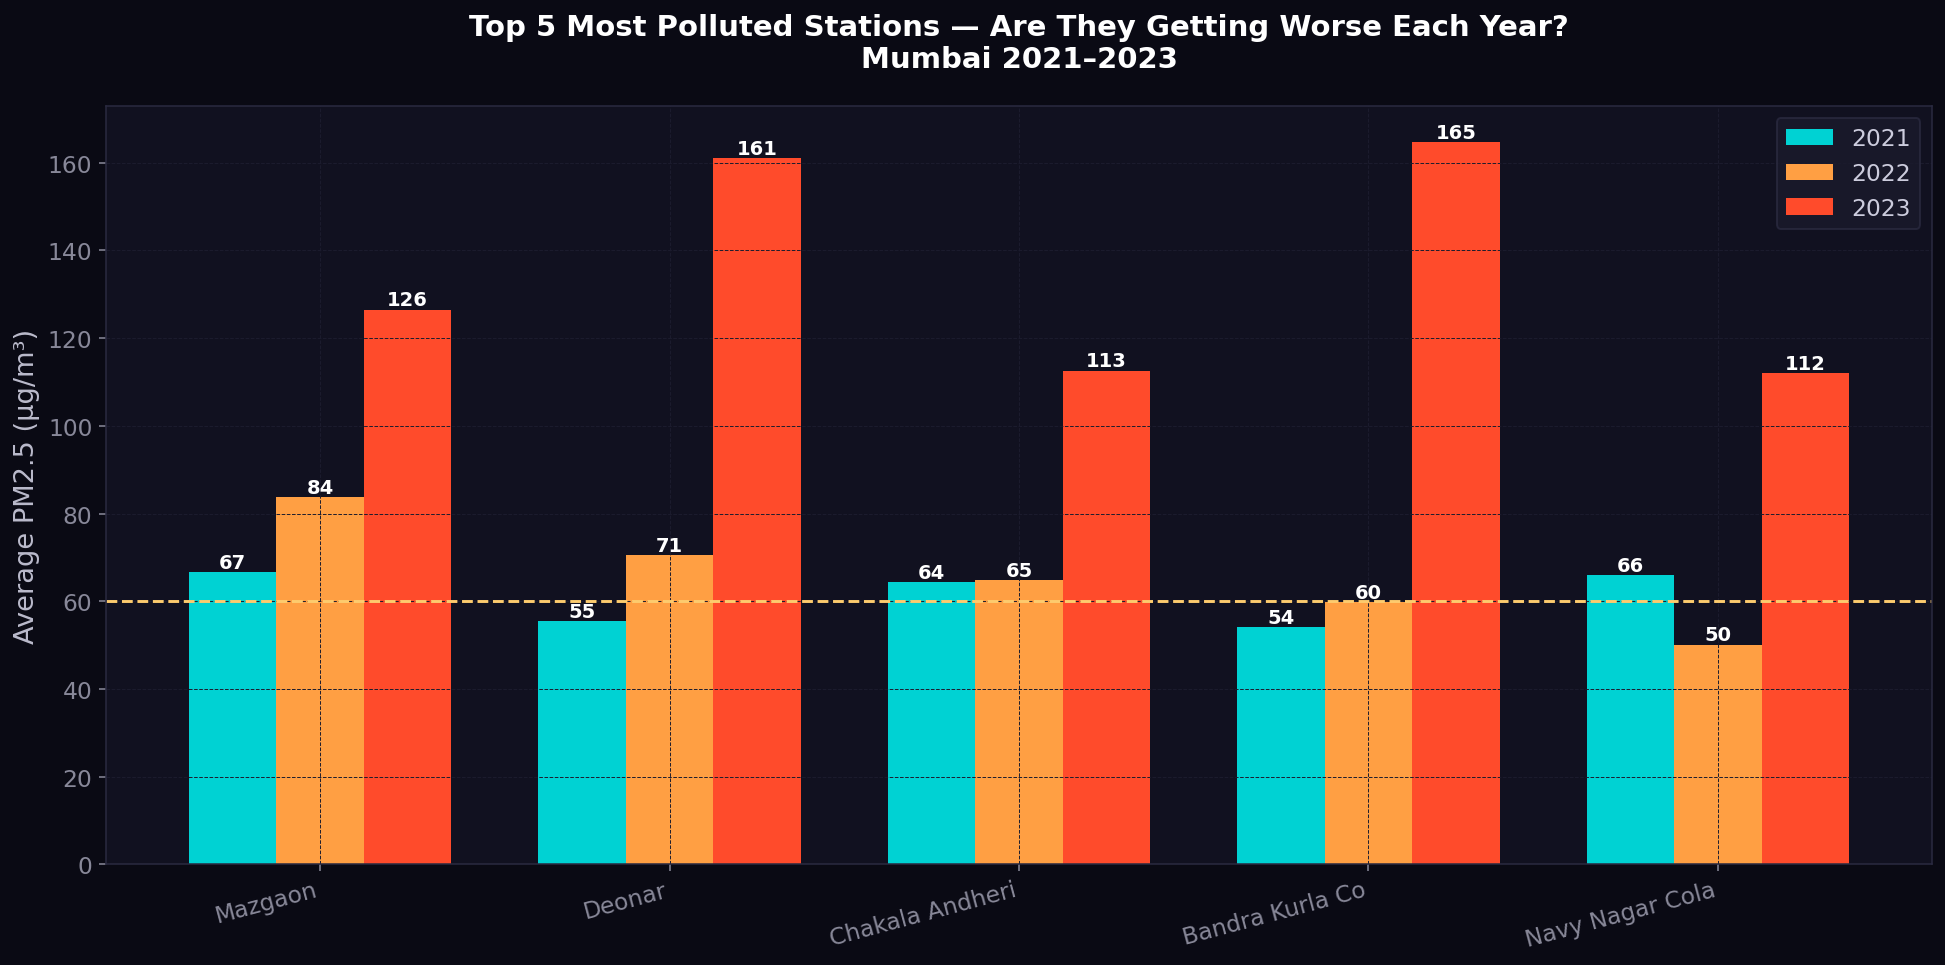

✓ Done — Top 5 by Year


In [31]:
fig, ax = plt.subplots(figsize=(14, 7))

top5 = df.groupby('Station')['PM2.5'].mean().nlargest(5).index.tolist()

st_yr = (df[df['Station'].isin(top5)]
         .groupby(['Station', 'Year'])['PM2.5']
         .mean()
         .unstack())

x   = np.arange(len(top5))
w   = 0.25

for i, (yr, clr) in enumerate(zip([2021, 2022, 2023],
                                   ['#00d2d3', '#ff9f43', '#ff4b2b'])):
    if yr in st_yr.columns:
        vals = [st_yr.loc[s, yr] if s in st_yr.index else 0 for s in top5]
        bars = ax.bar(x + i*w, vals, width=w,
                      label=str(yr), color=clr, edgecolor='none')
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2,
                    v + 1,
                    f'{v:.0f}',
                    ha='center', fontsize=10, color='white', fontweight='bold')

ax.set_xticks(x + w)
ax.set_xticklabels([s[:15] for s in top5], fontsize=12, rotation=15, ha='right')
ax.set_ylabel('Average PM2.5 (μg/m³)', fontsize=14)
ax.set_title('Top 5 Most Polluted Stations — Are They Getting Worse Each Year?\nMumbai 2021–2023',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12)
ax.axhline(60, color='#fdcb6e', ls='--', lw=1.5, label='NAAQS')
ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.savefig('chart_6C_top5_by_year.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Top 5 by Year")

Station vs Season Heatmap (which area worst in which season)


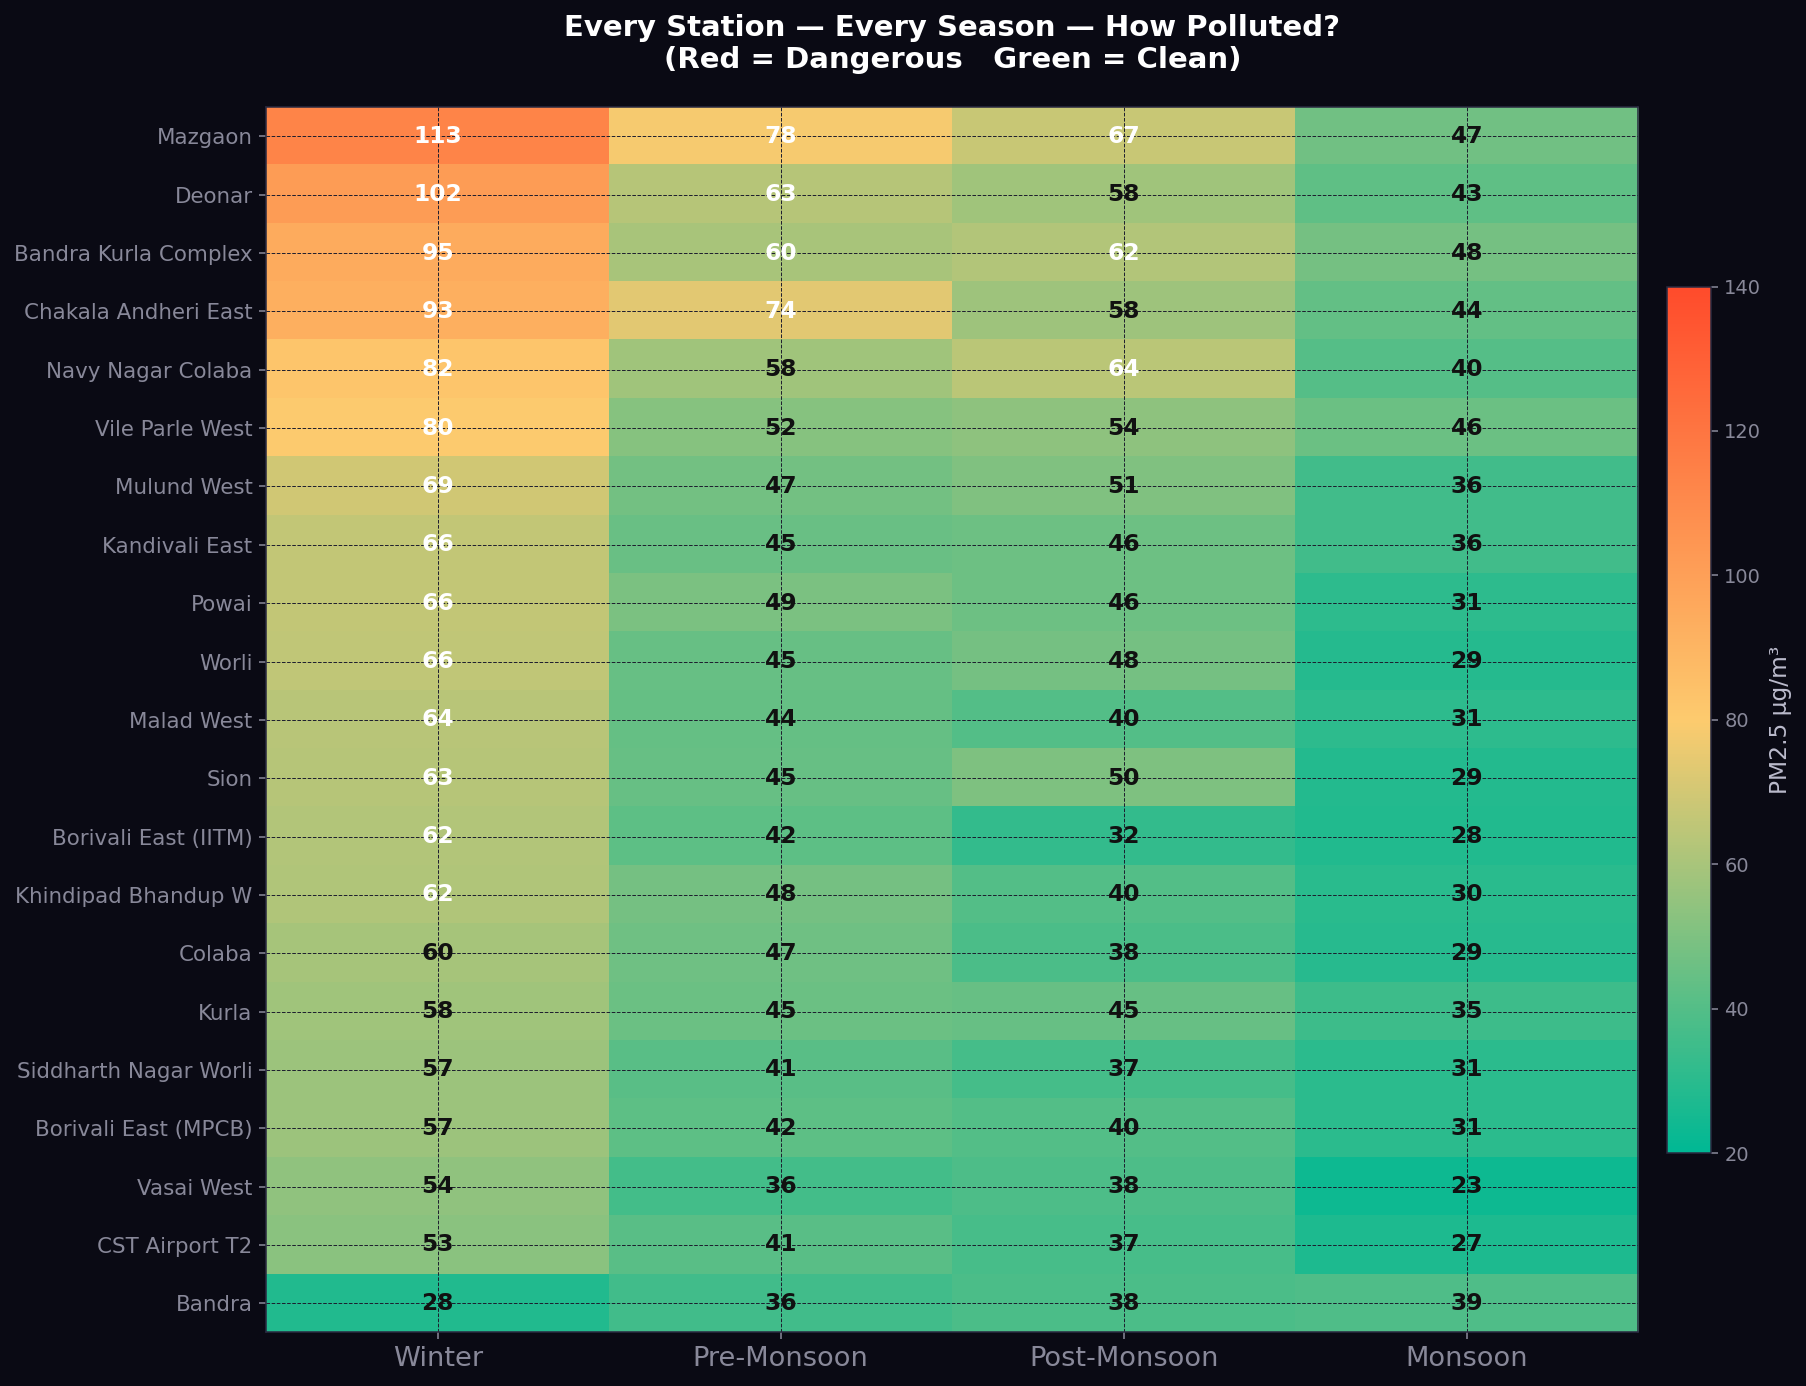

✓ Done — Station × Season Heatmap


In [33]:
from matplotlib.colors import LinearSegmentedColormap

fig, ax = plt.subplots(figsize=(13, 10))

season_order = ['Winter', 'Pre-Monsoon', 'Post-Monsoon', 'Monsoon']

st_sea = (df.groupby(['Station', 'Season'])['PM2.5']
            .mean()
            .unstack()[season_order]
            .sort_values('Winter', ascending=False))

cmap = LinearSegmentedColormap.from_list(
    'aqicmap', ['#00b894', '#fdcb6e', '#ff4b2b'], N=256
)

im = ax.imshow(st_sea.values, aspect='auto',
               cmap=cmap, vmin=20, vmax=140,
               interpolation='nearest')

ax.set_xticks(range(4))
ax.set_xticklabels(season_order, fontsize=14)
ax.set_yticks(range(len(st_sea)))
ax.set_yticklabels(st_sea.index, fontsize=11)

for i in range(st_sea.shape[0]):
    for j in range(st_sea.shape[1]):
        v = st_sea.iloc[i, j]
        if not pd.isna(v):
            ax.text(j, i, f'{v:.0f}',
                    ha='center', va='center',
                    fontsize=12, fontweight='bold',
                    color='white' if v > 60 else '#111111')

cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label('PM2.5 μg/m³', fontsize=12)

ax.set_title('Every Station — Every Season — How Polluted?\n(Red = Dangerous   Green = Clean)',
             fontsize=15, color='white', pad=20)

plt.tight_layout()
plt.savefig('chart_6D_station_season.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Station × Season Heatmap")

Best vs Worst Station Side by Side (Monthly Line)


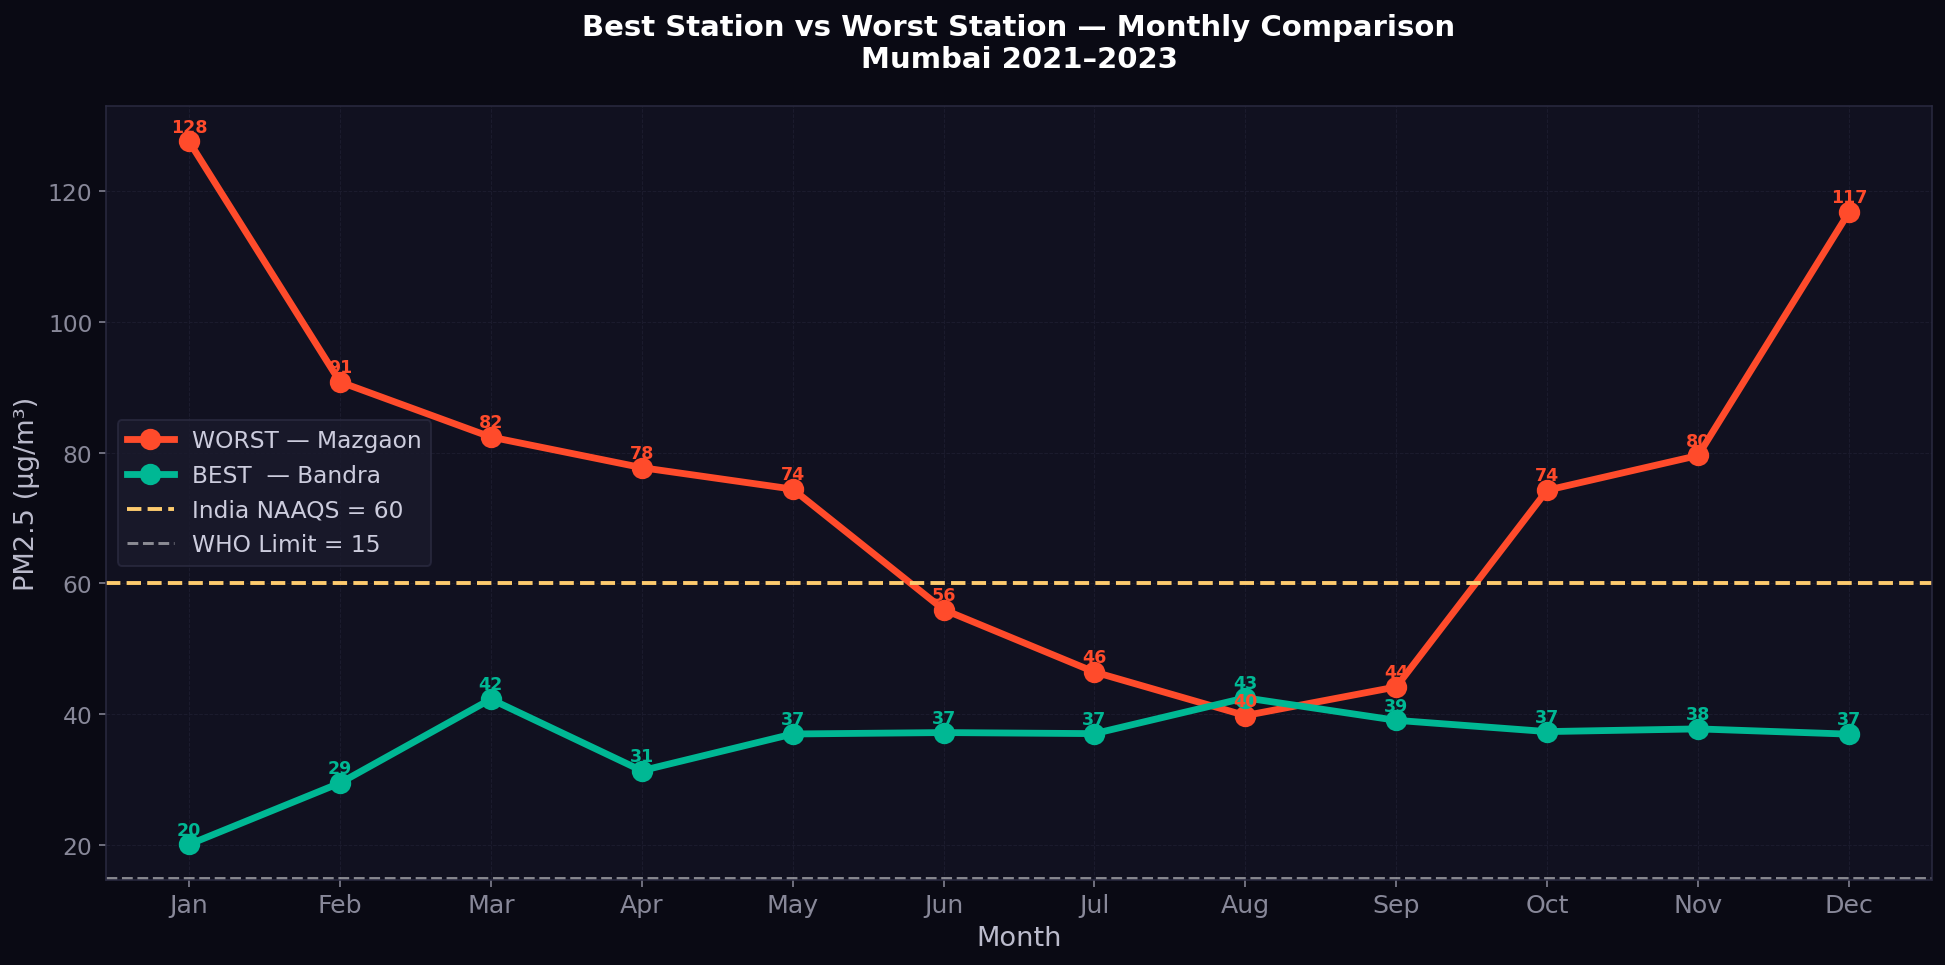

✓ Done — Best (Bandra) vs Worst (Mazgaon)


In [35]:
fig, ax = plt.subplots(figsize=(14, 7))

MONTHS = ['Jan','Feb','Mar','Apr','May','Jun',
          'Jul','Aug','Sep','Oct','Nov','Dec']

worst_st = df.groupby('Station')['PM2.5'].mean().idxmax()
best_st  = df.groupby('Station')['PM2.5'].mean().idxmin()

for station, clr, lbl in [
    (worst_st, '#ff4b2b', f'WORST — {worst_st}'),
    (best_st,  '#00b894', f'BEST  — {best_st}')
]:
    monthly = df[df['Station'] == station].groupby('Month')['PM2.5'].mean()
    ax.plot(monthly.index, monthly.values,
            color=clr, linewidth=3.5,
            marker='o', markersize=10, label=lbl)
    for m, v in monthly.items():
        ax.text(m, v + 1.5, f'{v:.0f}',
                ha='center', fontsize=9, color=clr, fontweight='bold')

ax.axhline(60, color='#fdcb6e', ls='--', lw=2, label='India NAAQS = 60')
ax.axhline(15, color='white',   ls='--', lw=1.5, label='WHO Limit = 15', alpha=0.5)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS, fontsize=13)
ax.set_xlabel('Month', fontsize=14)
ax.set_ylabel('PM2.5 (μg/m³)', fontsize=14)
ax.set_title('Best Station vs Worst Station — Monthly Comparison\nMumbai 2021–2023',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12)
ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.savefig('chart_6E_best_vs_worst.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✓ Done — Best ({best_st}) vs Worst ({worst_st})")

 Average of All Pollutants

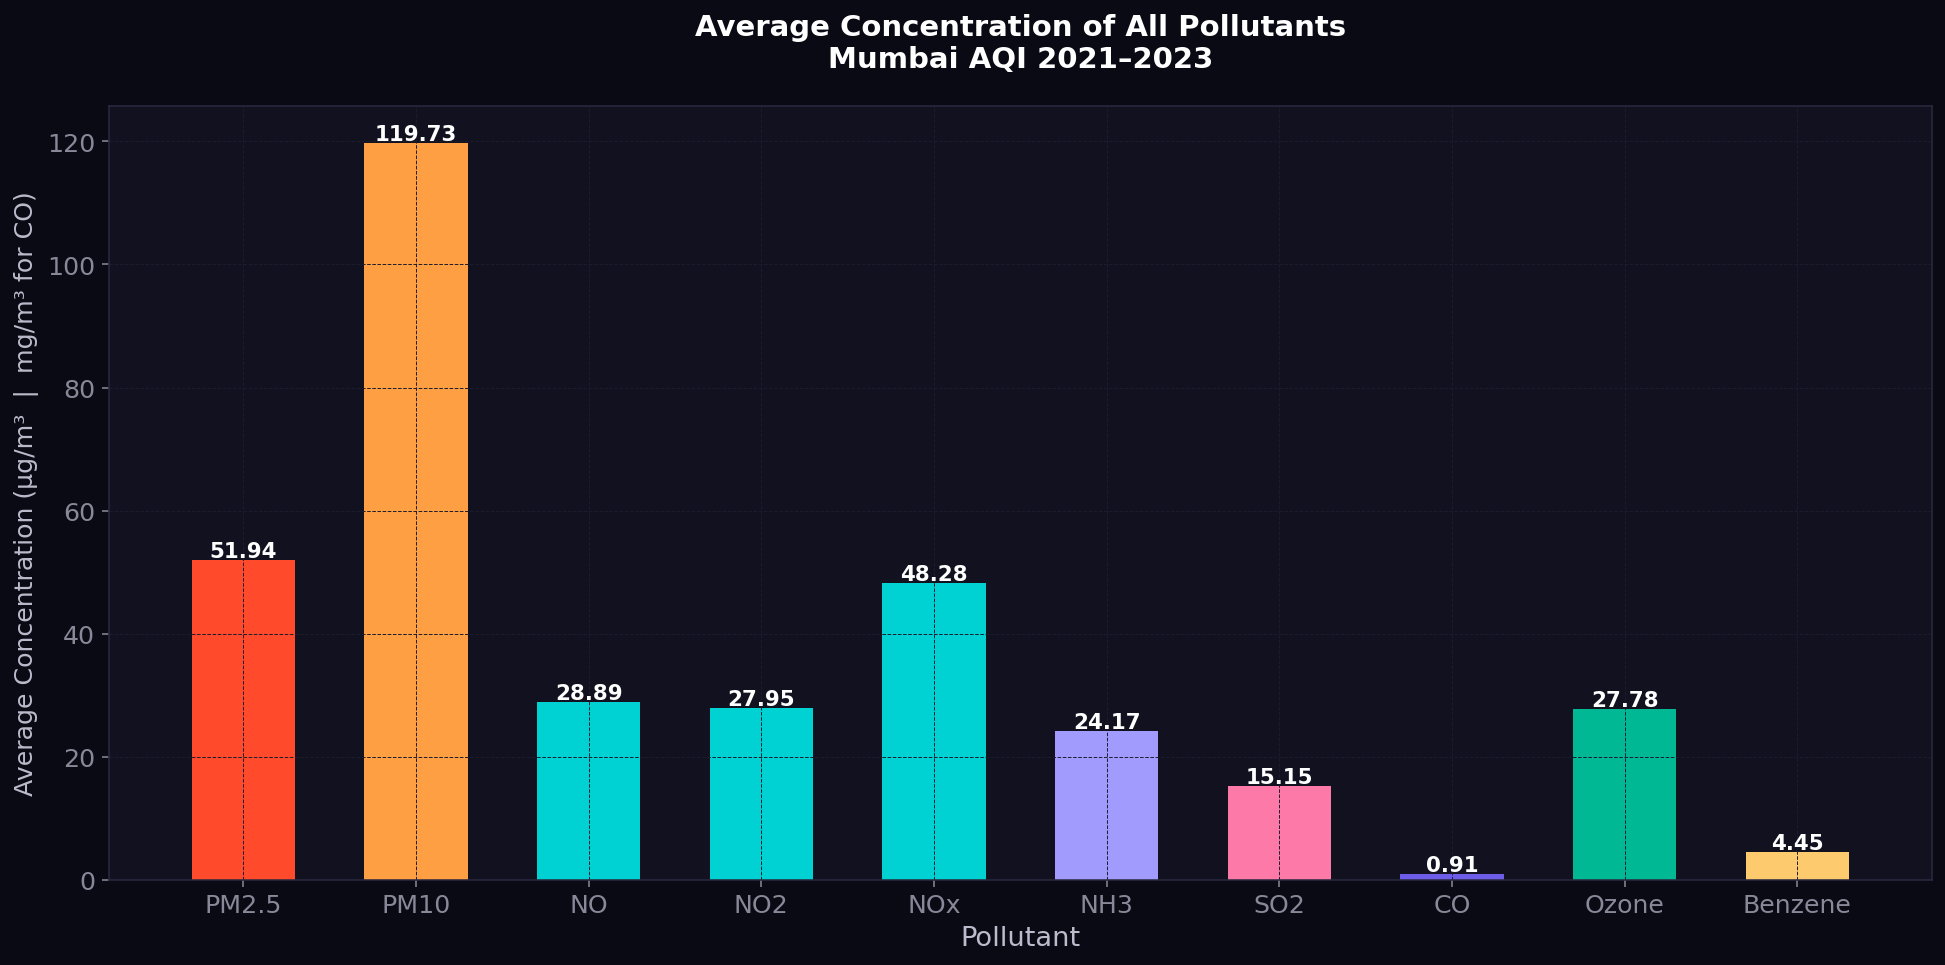

✓ Done — All Pollutants Average


In [37]:
fig, ax = plt.subplots(figsize=(14, 7))

pollutants  = ['PM2.5','PM10','NO','NO2','NOx','NH3','SO2','CO','Ozone','Benzene']
poll_colors = ['#ff4b2b','#ff9f43','#00d2d3','#00d2d3','#00d2d3',
               '#a29bfe','#fd79a8','#6c5ce7','#00b894','#fdcb6e']

avgs = [df[p].mean() for p in pollutants]

bars = ax.bar(pollutants, avgs, color=poll_colors, edgecolor='none', width=0.6)

for bar, v in zip(bars, avgs):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + 0.5,
            f'{v:.2f}',
            ha='center', fontsize=11, color='white', fontweight='bold')

ax.set_xlabel('Pollutant', fontsize=14)
ax.set_ylabel('Average Concentration (μg/m³  |  mg/m³ for CO)', fontsize=13)
ax.set_title('Average Concentration of All Pollutants\nMumbai AQI 2021–2023',
             fontsize=15, color='white', pad=20)
ax.tick_params(axis='both', labelsize=13)

plt.tight_layout()
plt.savefig('chart_7A_all_pollutants_avg.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — All Pollutants Average")

Pollutant Yearly Trend


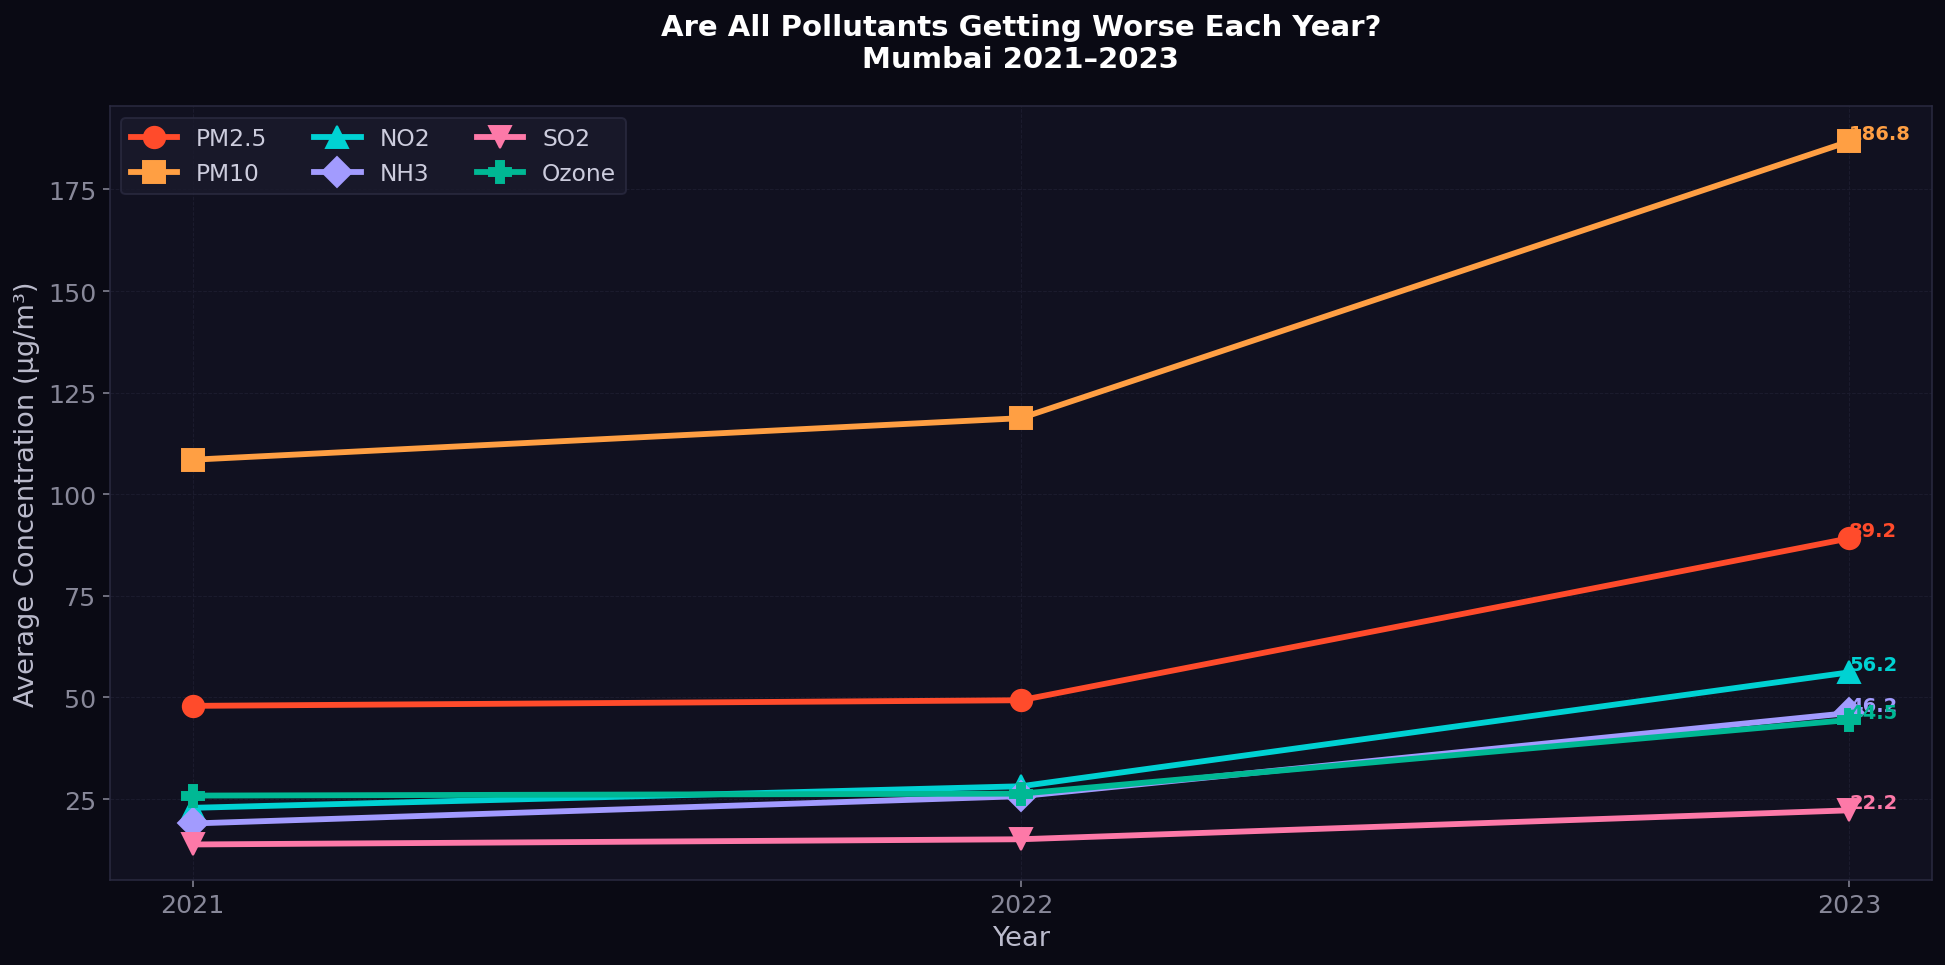

✓ Done — Pollutant Yearly Trend


In [39]:
fig, ax = plt.subplots(figsize=(14, 7))


poll_show  = ['PM2.5','PM10','NO2','NH3','SO2','Ozone']
poll_clrs  = ['#ff4b2b','#ff9f43','#00d2d3','#a29bfe','#fd79a8','#00b894']
poll_marks = ['o','s','^','D','v','P']

yr_avg = df.groupby('Year')[poll_show].mean()

for col, clr, mk in zip(poll_show, poll_clrs, poll_marks):
    ax.plot(yr_avg.index.astype(str), yr_avg[col],
            color=clr, linewidth=3,
            marker=mk, markersize=11, label=col)
    # value at last year
    ax.text(str(yr_avg.index[-1]),
            yr_avg[col].iloc[-1] + 0.5,
            f'{yr_avg[col].iloc[-1]:.1f}',
            fontsize=10, color=clr, fontweight='bold')

ax.set_xlabel('Year', fontsize=14)
ax.set_ylabel('Average Concentration (μg/m³)', fontsize=14)
ax.set_title('Are All Pollutants Getting Worse Each Year?\nMumbai 2021–2023',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12, ncol=3)
ax.tick_params(axis='both', labelsize=13)

plt.tight_layout()
plt.savefig('chart_7B_pollutant_yearly.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Pollutant Yearly Trend")

 Correlation Matrix (Which pollutants move together)
 

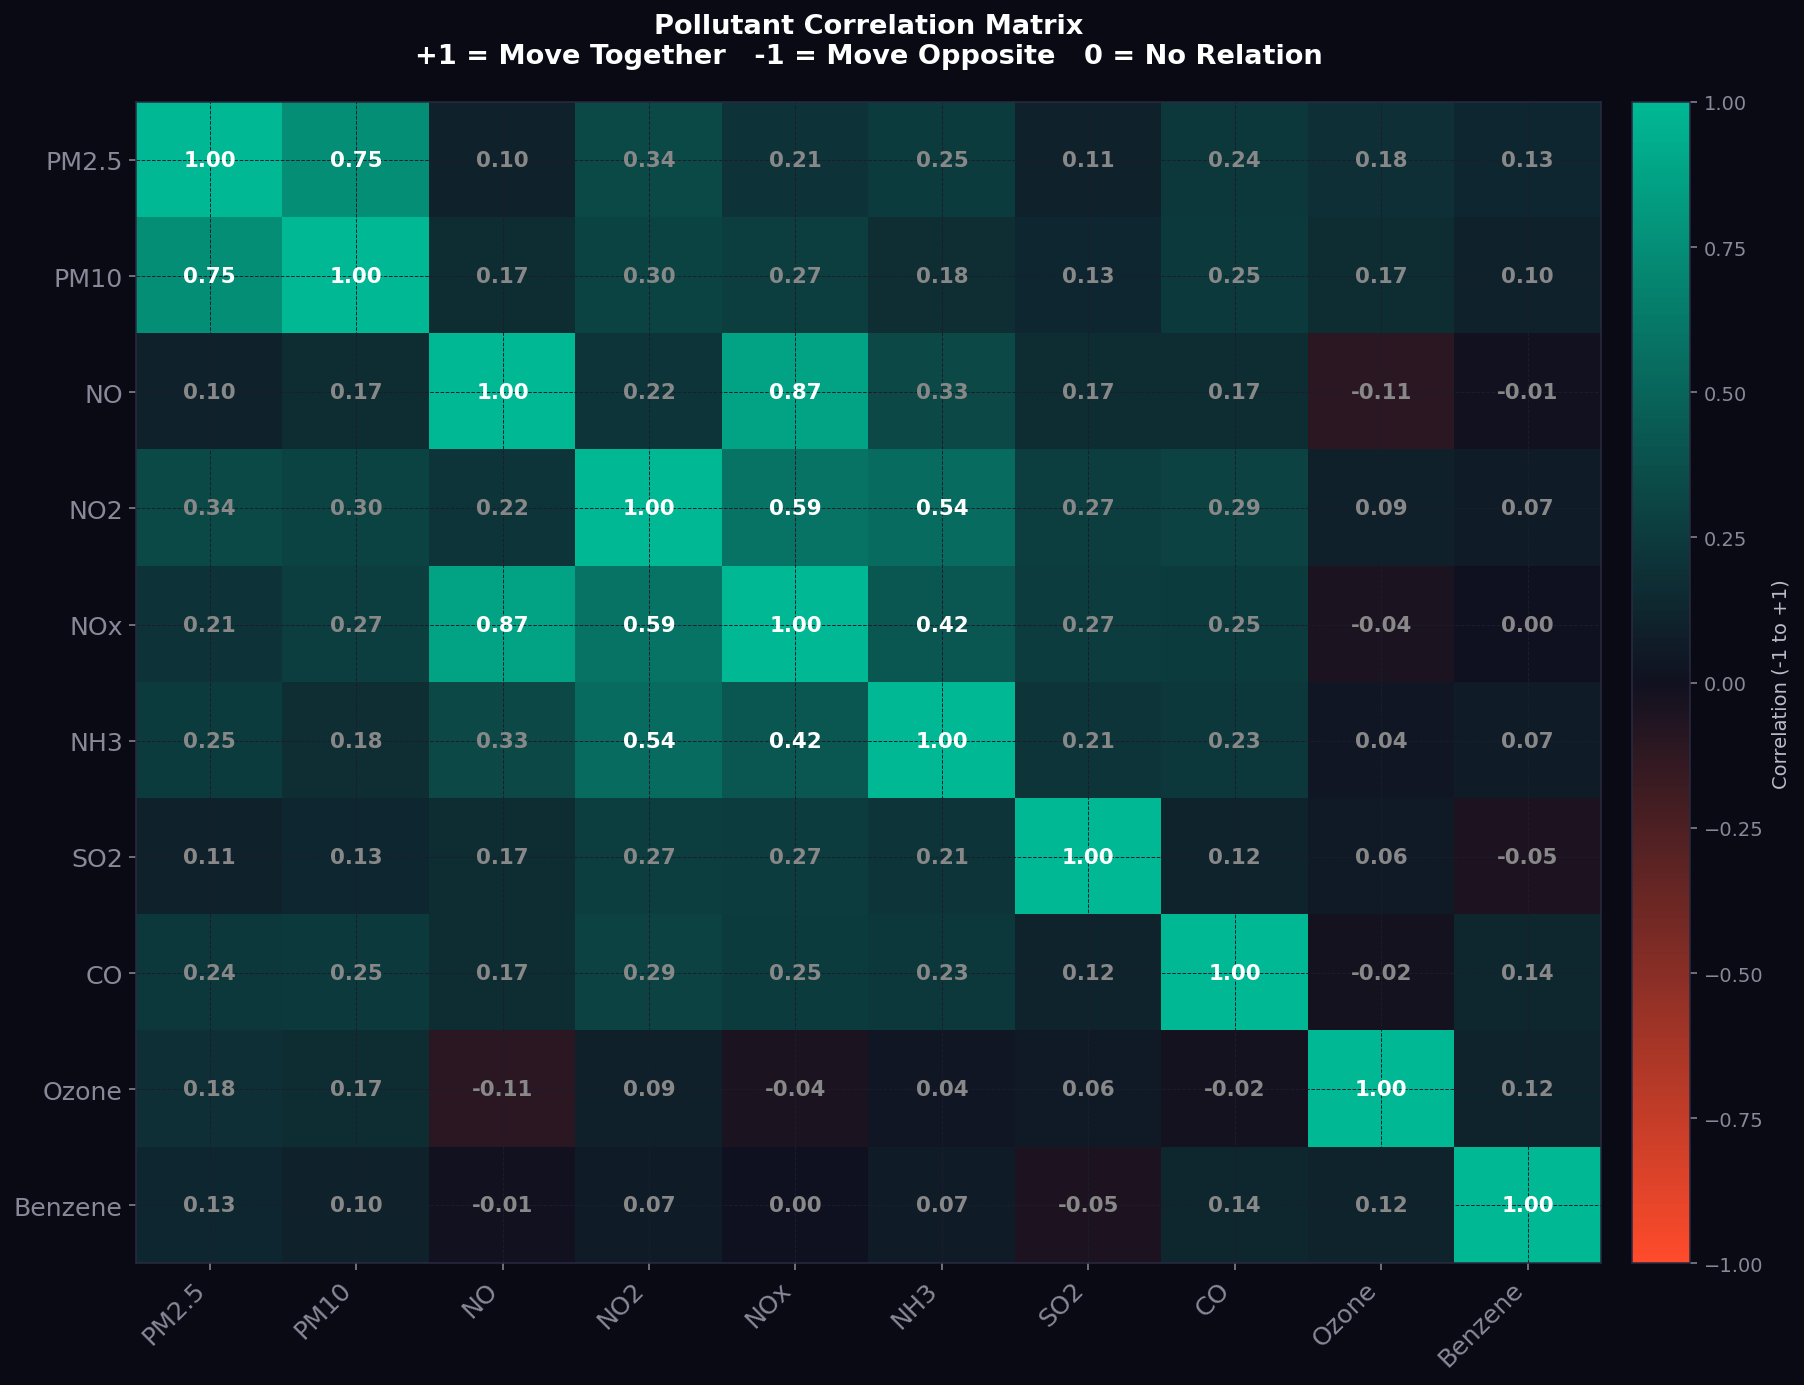

✓ Done — Correlation Matrix


In [41]:
from matplotlib.colors import LinearSegmentedColormap

fig, ax = plt.subplots(figsize=(13, 10))

corr_polls = ['PM2.5','PM10','NO','NO2','NOx','NH3','SO2','CO','Ozone','Benzene']
corr       = df[corr_polls].corr()

cmap = LinearSegmentedColormap.from_list(
    'corrmap', ['#ff4b2b', '#111120', '#00b894'], N=256
)

im = ax.imshow(corr.values, cmap=cmap,
               vmin=-1, vmax=1,
               aspect='auto', interpolation='nearest')

ax.set_xticks(range(len(corr_polls)))
ax.set_xticklabels(corr_polls, rotation=45, ha='right', fontsize=13)
ax.set_yticks(range(len(corr_polls)))
ax.set_yticklabels(corr_polls, fontsize=13)

# value in each cell
for i in range(len(corr_polls)):
    for j in range(len(corr_polls)):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}',
                ha='center', va='center',
                fontsize=11, fontweight='bold',
                color='white' if abs(v) > 0.4 else '#888888')

plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label='Correlation (-1 to +1)')

ax.set_title('Pollutant Correlation Matrix\n+1 = Move Together   -1 = Move Opposite   0 = No Relation',
             fontsize=14, color='white', pad=20)

plt.tight_layout()
plt.savefig('chart_7C_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Correlation Matrix")

 PM2.5 vs PM10 Scatter (colored by season)
 

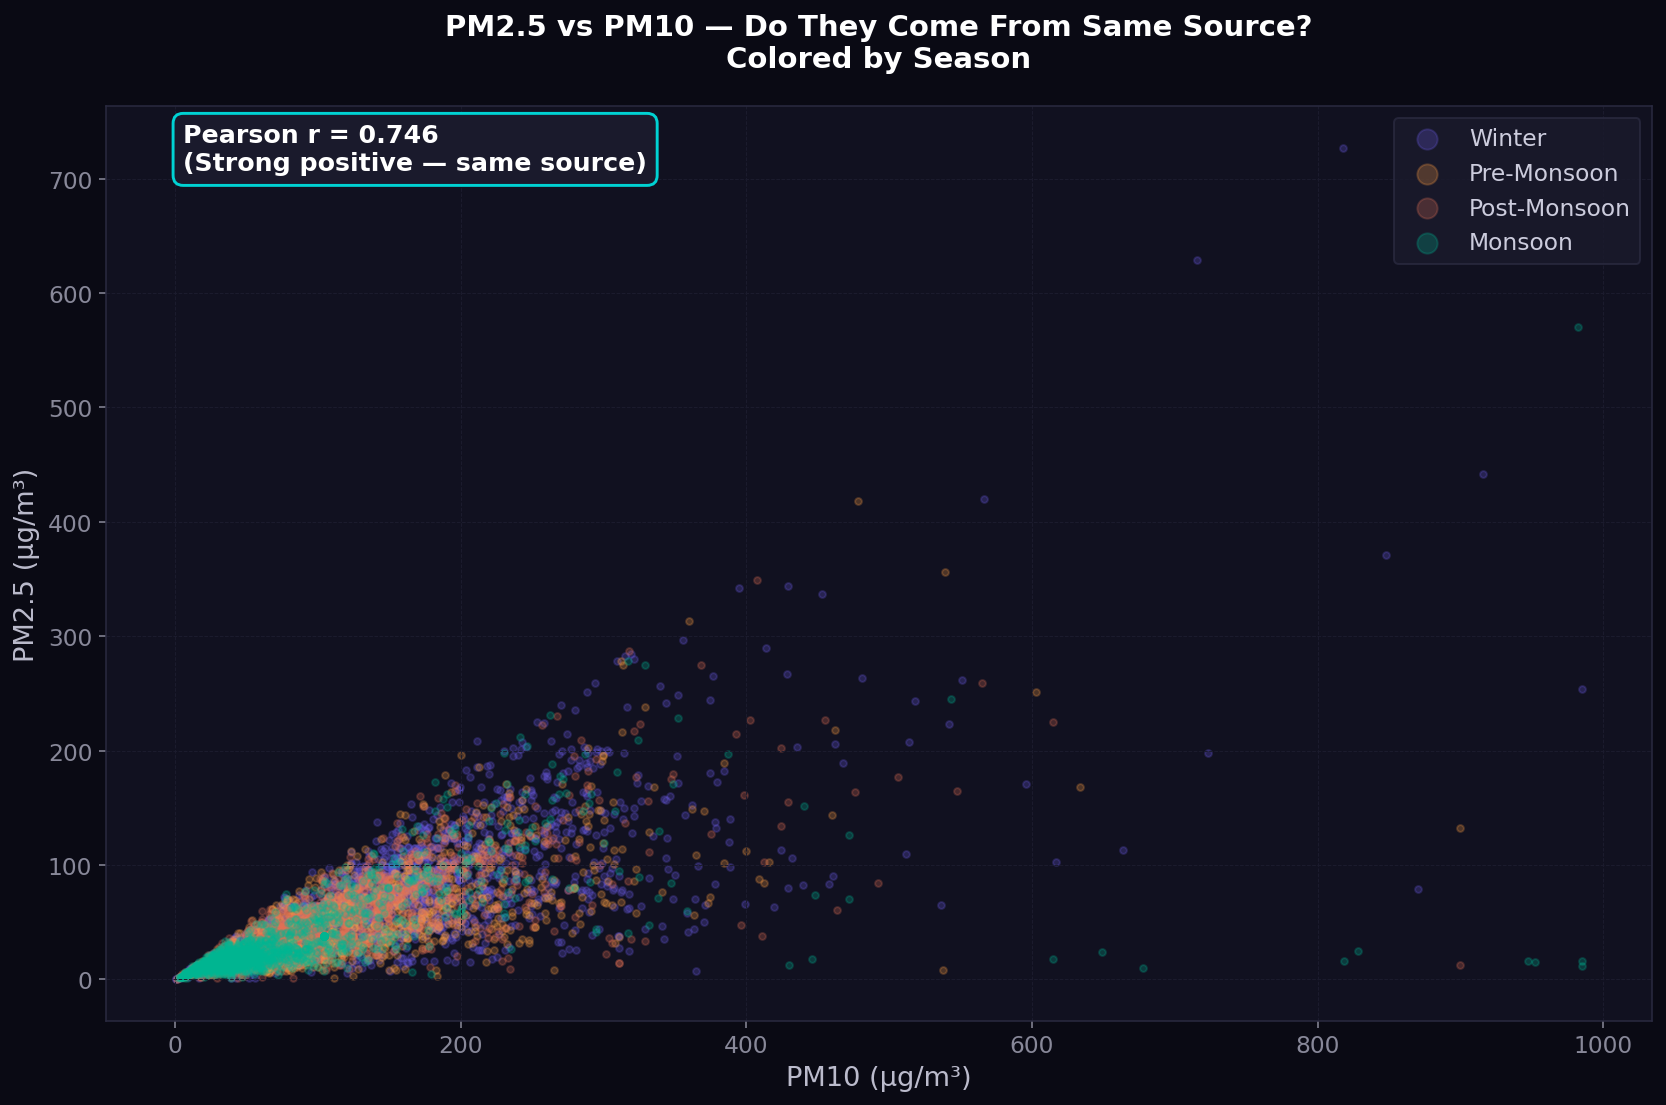

✓ Done — PM2.5 vs PM10 Scatter


In [43]:
fig, ax = plt.subplots(figsize=(12, 8))

# sample 6000 points so it doesnt get too heavy
sample = df[['PM2.5','PM10','Season']].dropna().sample(6000, random_state=42)

sea_colors = {
    'Winter'       : '#6c5ce7',
    'Pre-Monsoon'  : '#ff9f43',
    'Post-Monsoon' : '#e17055',
    'Monsoon'      : '#00b894'
}

for season, clr in sea_colors.items():
    sub = sample[sample['Season'] == season]
    ax.scatter(sub['PM10'], sub['PM2.5'],
               alpha=0.25, s=12, color=clr, label=season)

# correlation value
r = df[['PM2.5','PM10']].corr().iloc[0, 1]
ax.text(0.05, 0.93,
        f'Pearson r = {r:.3f}\n(Strong positive — same source)',
        transform=ax.transAxes,
        fontsize=13, color='white', fontweight='bold',
        bbox=dict(facecolor='#1a1a2c', edgecolor='#00d2d3',
                  boxstyle='round,pad=0.4', linewidth=1.5))

ax.set_xlabel('PM10 (μg/m³)', fontsize=14)
ax.set_ylabel('PM2.5 (μg/m³)', fontsize=14)
ax.set_title('PM2.5 vs PM10 — Do They Come From Same Source?\nColored by Season',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12, markerscale=3)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('chart_7D_pm25_vs_pm10.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — PM2.5 vs PM10 Scatter")

Benzene Monthly (Carcinogen Alert)

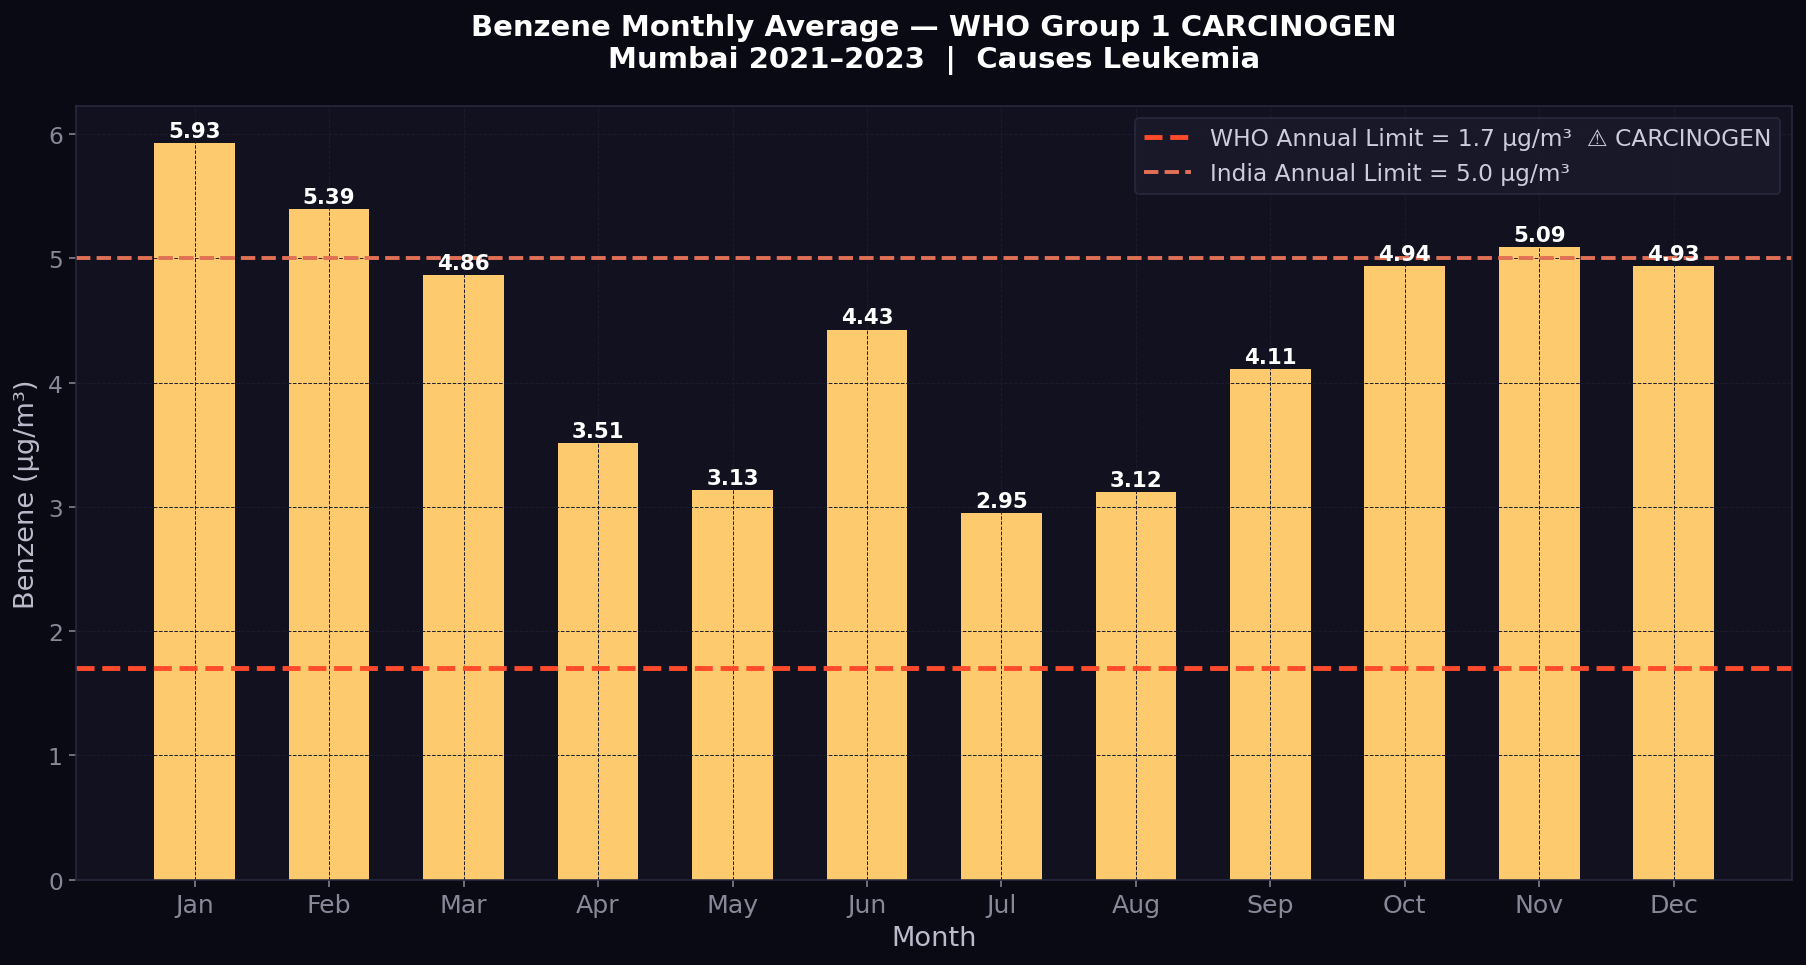

✓ Done — Benzene Chart


In [45]:
fig, ax = plt.subplots(figsize=(13, 7))

MONTHS = ['Jan','Feb','Mar','Apr','May','Jun',
          'Jul','Aug','Sep','Oct','Nov','Dec']

benz_monthly = df.groupby('Month')['Benzene'].mean()

bars = ax.bar(range(1, 13), benz_monthly.values,
              color='#fdcb6e', edgecolor='none', width=0.6)

for bar, v in zip(bars, benz_monthly.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + 0.05,
            f'{v:.2f}',
            ha='center', fontsize=11, color='white', fontweight='bold')

# WHO and India limits
ax.axhline(1.7, color='#ff4b2b', ls='--', lw=2.5,
           label='WHO Annual Limit = 1.7 μg/m³  ⚠ CARCINOGEN')
ax.axhline(5.0, color='#e17055', ls='--', lw=2,
           label='India Annual Limit = 5.0 μg/m³')

ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS, fontsize=13)
ax.set_xlabel('Month', fontsize=14)
ax.set_ylabel('Benzene (μg/m³)', fontsize=14)
ax.set_title('Benzene Monthly Average — WHO Group 1 CARCINOGEN\nMumbai 2021–2023  |  Causes Leukemia',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12)
ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.savefig('chart_7E_benzene.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Benzene Chart")

Health Impact Summary

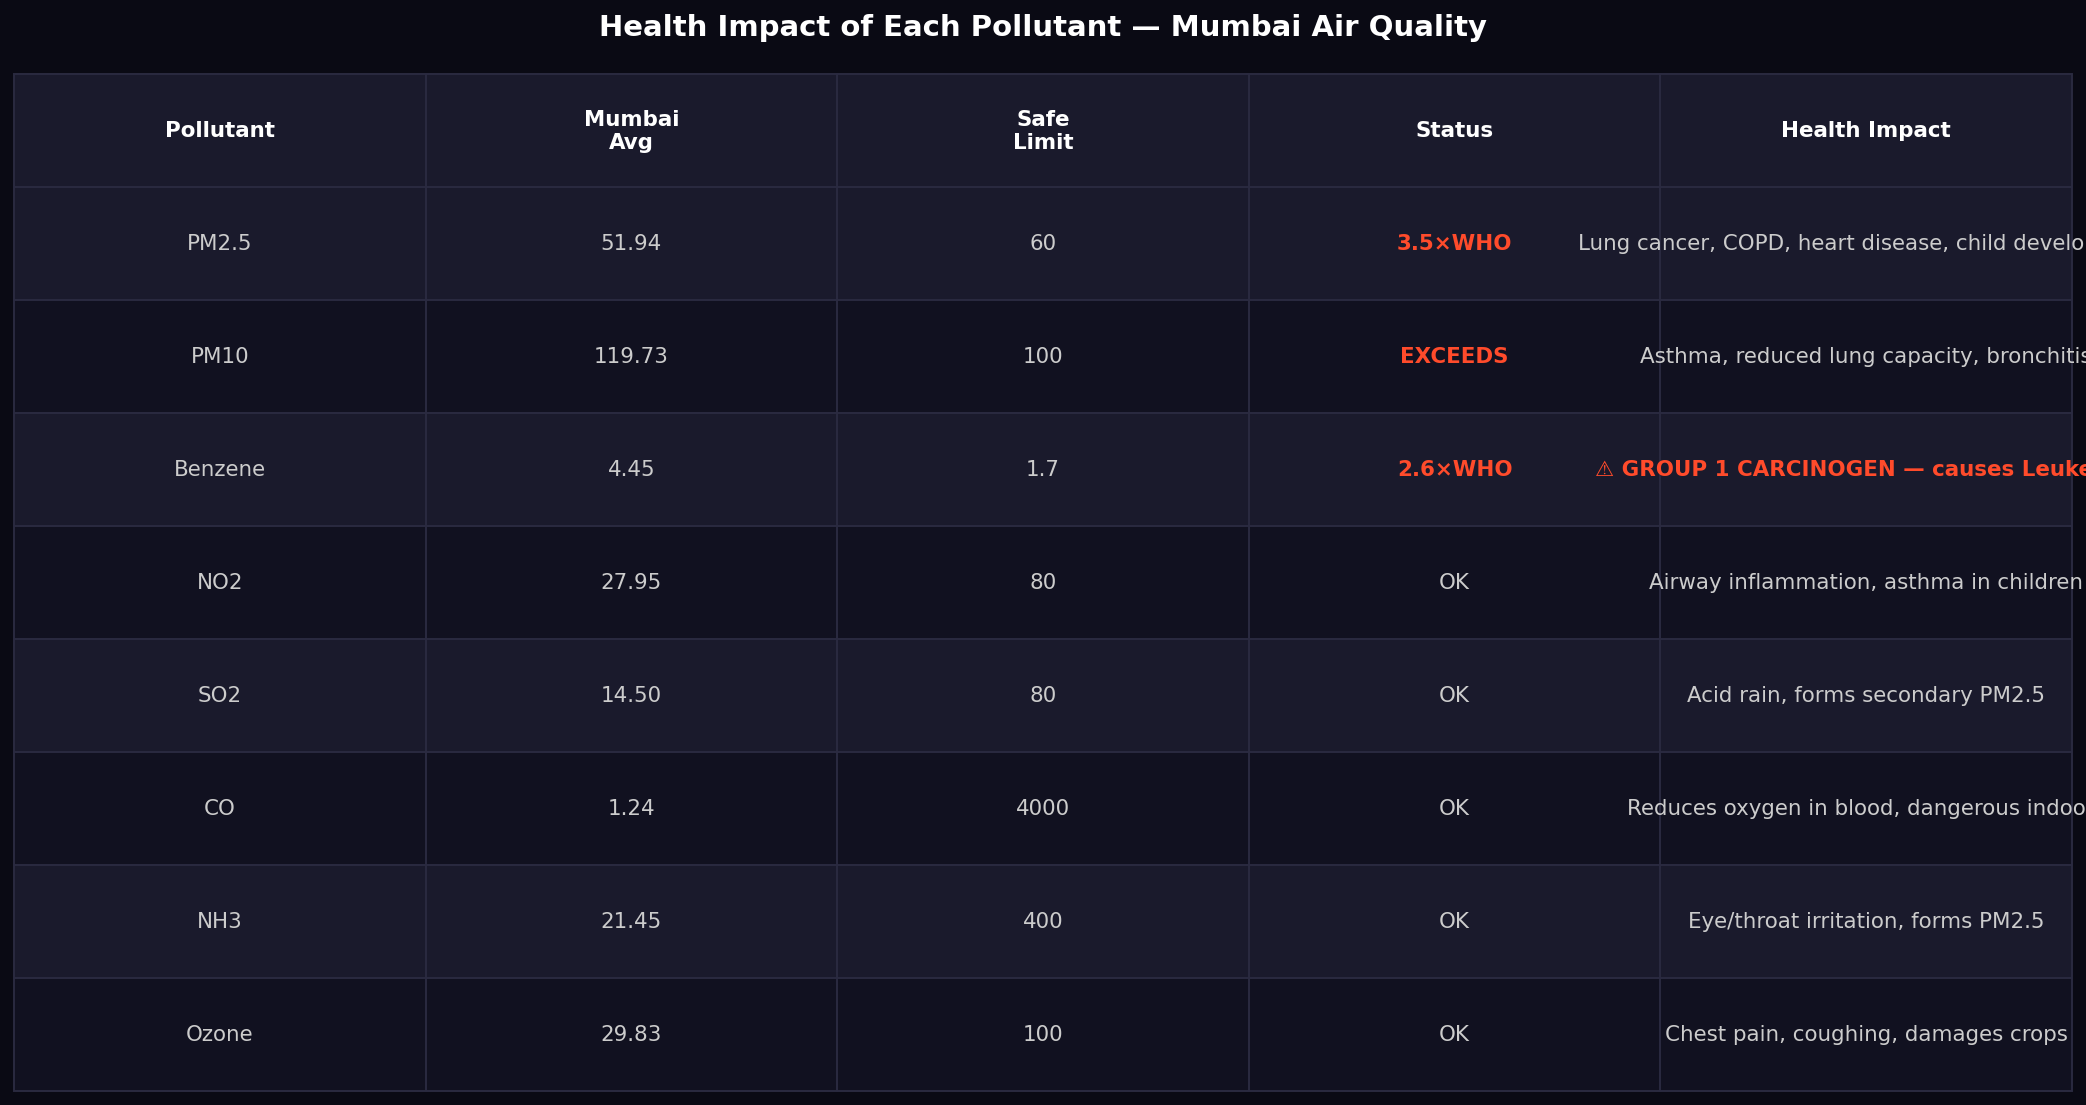

✓ Done — Health Impact Table


In [47]:
fig, ax = plt.subplots(figsize=(15, 8))
ax.axis('off')
ax.set_facecolor('#0a0a14')

rows = [
    ['PM2.5',   '51.94',  '60',   '3.5×WHO',  'Lung cancer, COPD, heart disease, child development'],
    ['PM10',    '119.73', '100',  'EXCEEDS',  'Asthma, reduced lung capacity, bronchitis'],
    ['Benzene', '4.45',   '1.7',  '2.6×WHO',  '⚠ GROUP 1 CARCINOGEN — causes Leukemia'],
    ['NO2',     '27.95',  '80',   'OK',       'Airway inflammation, asthma in children'],
    ['SO2',     '14.50',  '80',   'OK',       'Acid rain, forms secondary PM2.5'],
    ['CO',      '1.24',   '4000', 'OK',       'Reduces oxygen in blood, dangerous indoors'],
    ['NH3',     '21.45',  '400',  'OK',       'Eye/throat irritation, forms PM2.5'],
    ['Ozone',   '29.83',  '100',  'OK',       'Chest pain, coughing, damages crops'],
]

col_labels = ['Pollutant', 'Mumbai\nAvg', 'Safe\nLimit', 'Status', 'Health Impact']

tbl = ax.table(
    cellText=rows,
    colLabels=col_labels,
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 1]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)

for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor('#2a2a40')
    if row == 0:
        cell.set_facecolor('#1a1a2c')
        cell.get_text().set_color('white')
        cell.get_text().set_fontweight('bold')
    elif row % 2 == 0:
        cell.set_facecolor('#111120')
        cell.get_text().set_color('#cccccc')
    else:
        cell.set_facecolor('#1a1a2c')
        cell.get_text().set_color('#cccccc')
    # highlight danger
    txt = cell.get_text().get_text()
    if 'CARCINOGEN' in txt or 'EXCEEDS' in txt or '×WHO' in txt:
        cell.get_text().set_color('#ff4b2b')
        cell.get_text().set_fontweight('bold')

ax.set_title('Health Impact of Each Pollutant — Mumbai Air Quality',
             fontsize=15, color='white', pad=20)

plt.tight_layout()
plt.savefig('chart_7F_health_impact_table.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Health Impact Table")

PM2.5 Source Contribution Pie Chart

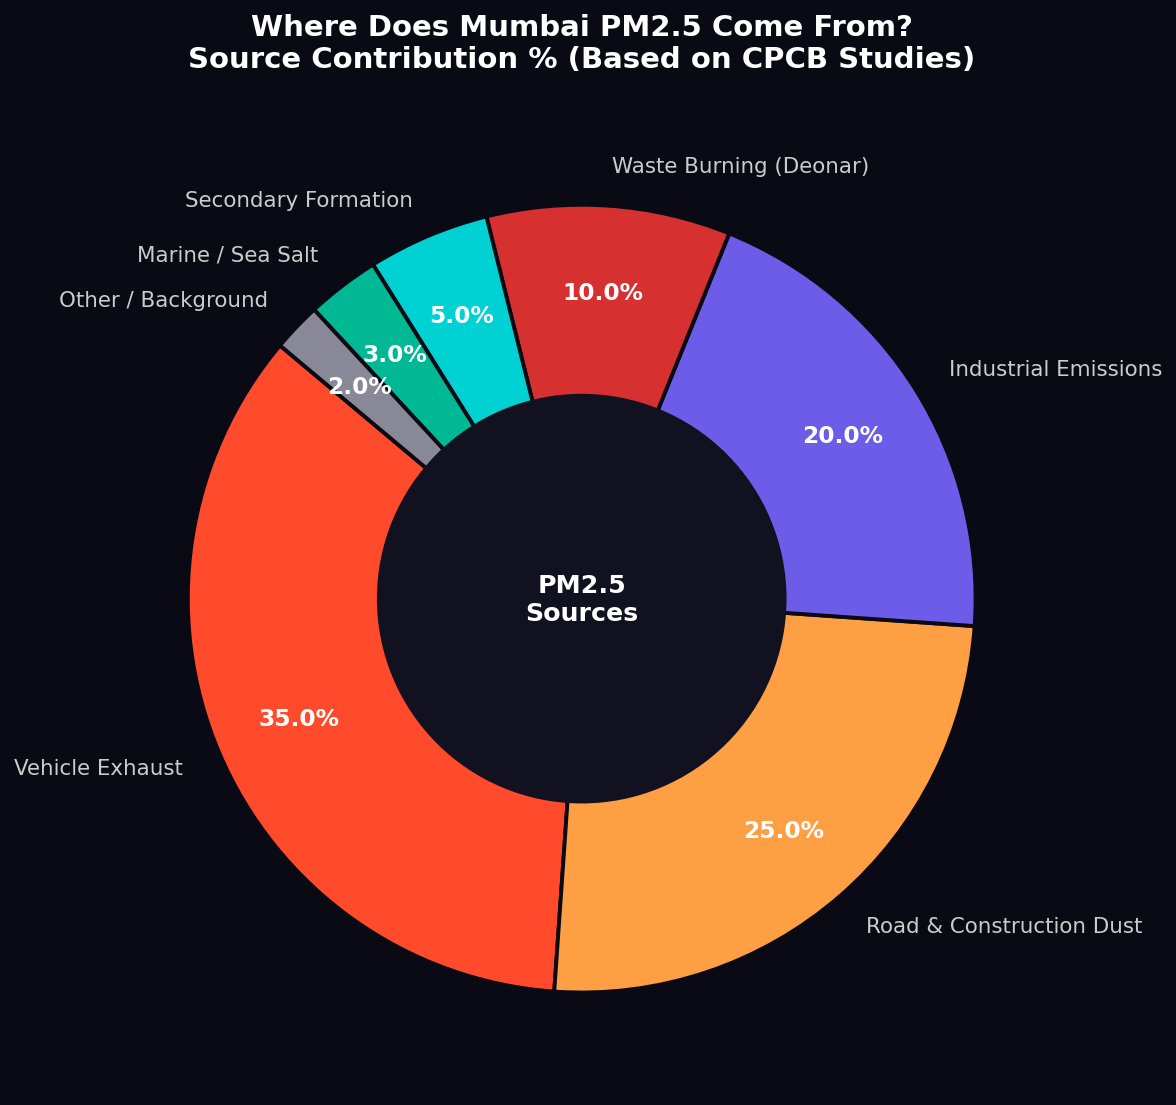

✓ Done — PM2.5 Source Pie


In [49]:
fig, ax = plt.subplots(figsize=(12, 8))

sources = [
    'Vehicle Exhaust',
    'Road & Construction Dust',
    'Industrial Emissions',
    'Waste Burning (Deonar)',
    'Secondary Formation',
    'Marine / Sea Salt',
    'Other / Background'
]
contributions = [35, 25, 20, 10, 5, 3, 2]
colors = ['#ff4b2b','#ff9f43','#6c5ce7','#d63031','#00d2d3','#00b894','#888899']

wedges, texts, autotexts = ax.pie(
    contributions,
    labels=sources,
    colors=colors,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.78,
    wedgeprops={'edgecolor': '#0a0a14', 'linewidth': 2}
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')
    at.set_color('white')
for t in texts:
    t.set_fontsize(11)
    t.set_color('#cccccc')

# donut hole
centre = plt.Circle((0, 0), 0.52, fc='#111120')
ax.add_artist(centre)
ax.text(0, 0, 'PM2.5\nSources',
        ha='center', va='center',
        fontsize=13, fontweight='bold', color='white')

ax.set_title('Where Does Mumbai PM2.5 Come From?\nSource Contribution % (Based on CPCB Studies)',
             fontsize=15, color='white', pad=20)

plt.tight_layout()
plt.savefig('chart_8A_pm25_sources_pie.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — PM2.5 Source Pie")

Source vs Pollutant Stacked Bar

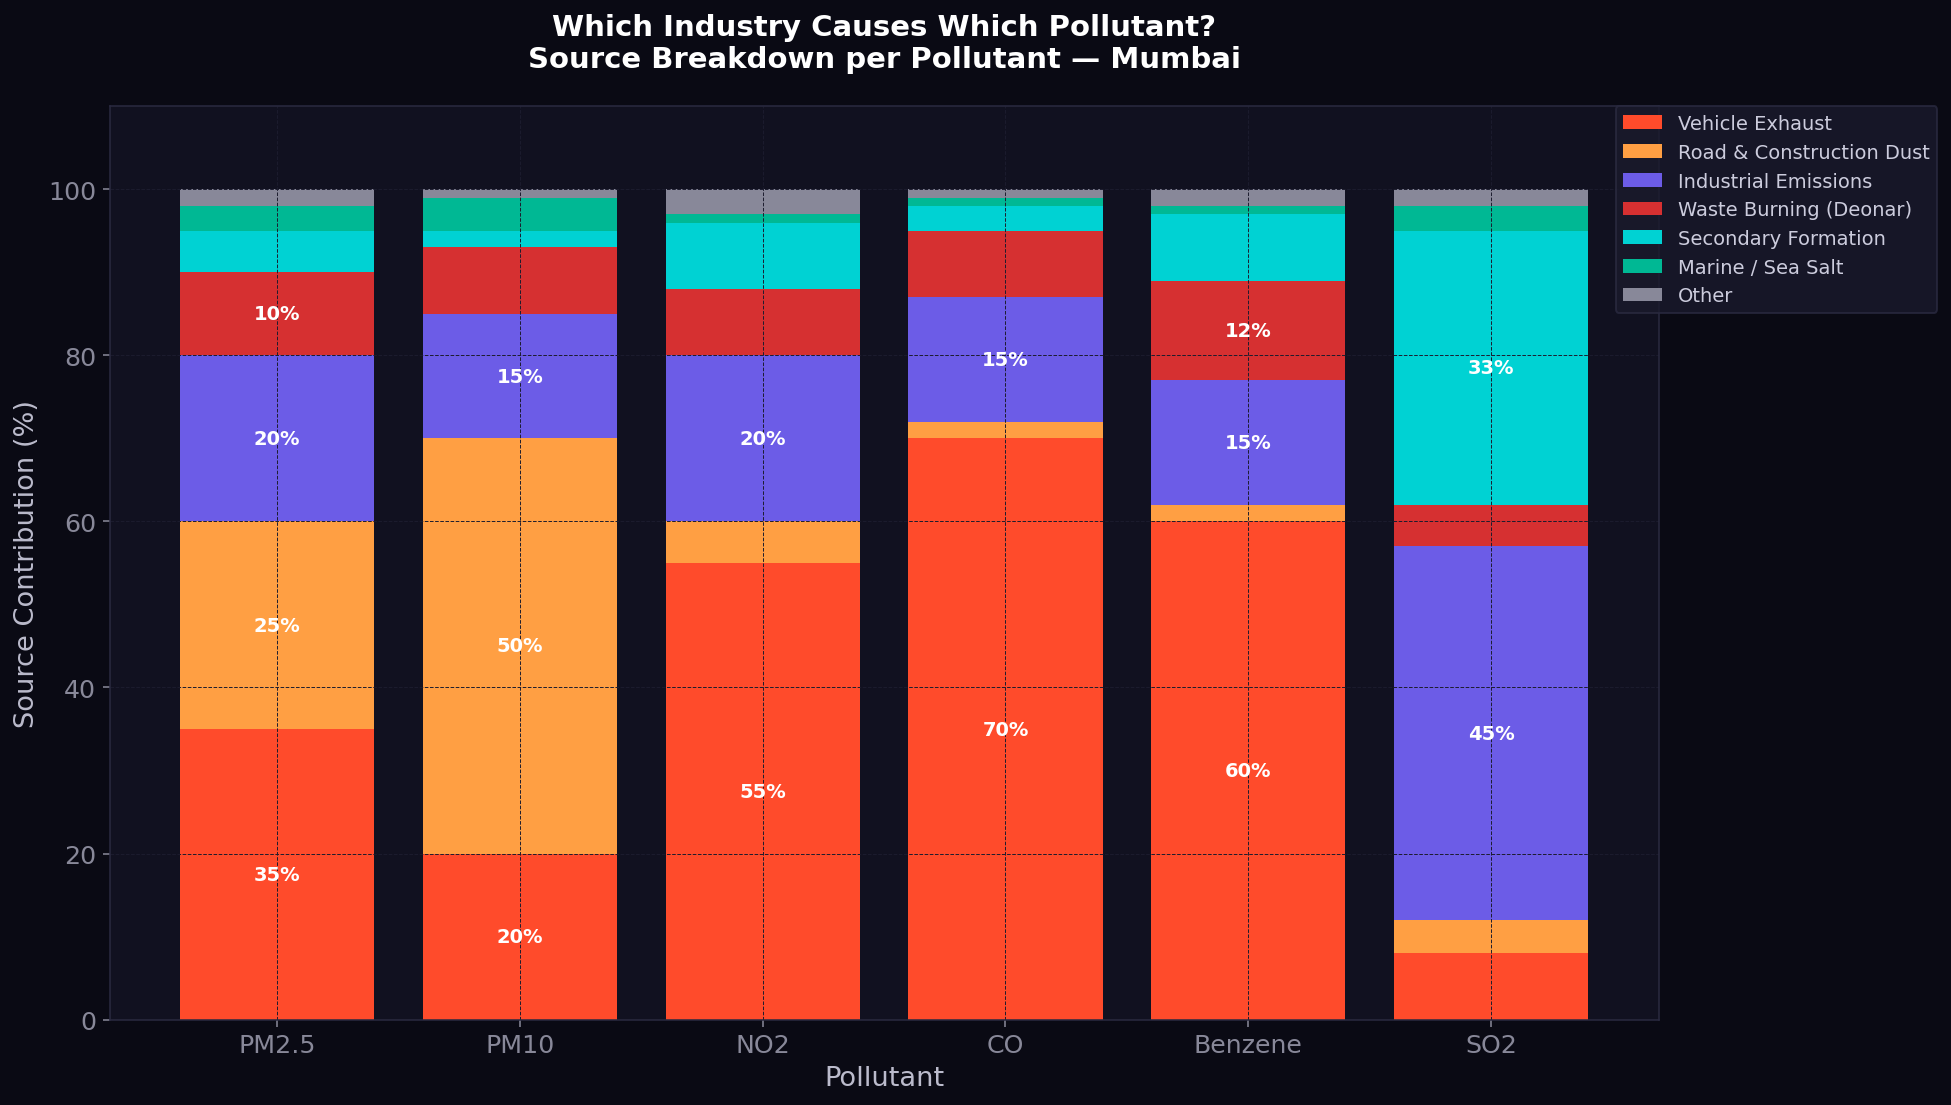

✓ Done — Source vs Pollutant


In [51]:
fig, ax = plt.subplots(figsize=(14, 8))

import numpy as np

sources = [
    'Vehicle Exhaust',
    'Road & Construction Dust',
    'Industrial Emissions',
    'Waste Burning (Deonar)',
    'Secondary Formation',
    'Marine / Sea Salt',
    'Other'
]
colors = ['#ff4b2b','#ff9f43','#6c5ce7','#d63031','#00d2d3','#00b894','#888899']

# contribution % of each source per pollutant
data = {
    'PM2.5'  : [35, 25, 20, 10, 5,  3, 2],
    'PM10'   : [20, 50, 15,  8, 2,  4, 1],
    'NO2'    : [55,  5, 20,  8, 8,  1, 3],
    'CO'     : [70,  2, 15,  8, 3,  1, 1],
    'Benzene': [60,  2, 15, 12, 8,  1, 2],
    'SO2'    : [ 8,  4, 45,  5, 33, 3, 2],
}

poll_names = list(data.keys())
bottom     = np.zeros(len(poll_names))

for src, clr in zip(sources, colors):
    vals = [data[p][sources.index(src)] for p in poll_names]
    bars = ax.bar(poll_names, vals, bottom=bottom,
                  label=src, color=clr, edgecolor='none')
    # label if big enough
    for bar, v, b in zip(bars, vals, bottom):
        if v > 8:
            ax.text(bar.get_x() + bar.get_width()/2,
                    b + v/2,
                    f'{v}%',
                    ha='center', va='center',
                    fontsize=10, color='white', fontweight='bold')
    bottom += np.array(vals)

ax.set_ylim(0, 110)
ax.set_ylabel('Source Contribution (%)', fontsize=14)
ax.set_xlabel('Pollutant', fontsize=14)
ax.set_title('Which Industry Causes Which Pollutant?\nSource Breakdown per Pollutant — Mumbai',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=10, loc='upper right',
          bbox_to_anchor=(1.18, 1), borderaxespad=0)
ax.tick_params(axis='both', labelsize=13)

plt.tight_layout()
plt.savefig('chart_8B_source_vs_pollutant.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Source vs Pollutant")

Deonar Dump Hotspot (PM2.5 + CO monthly)

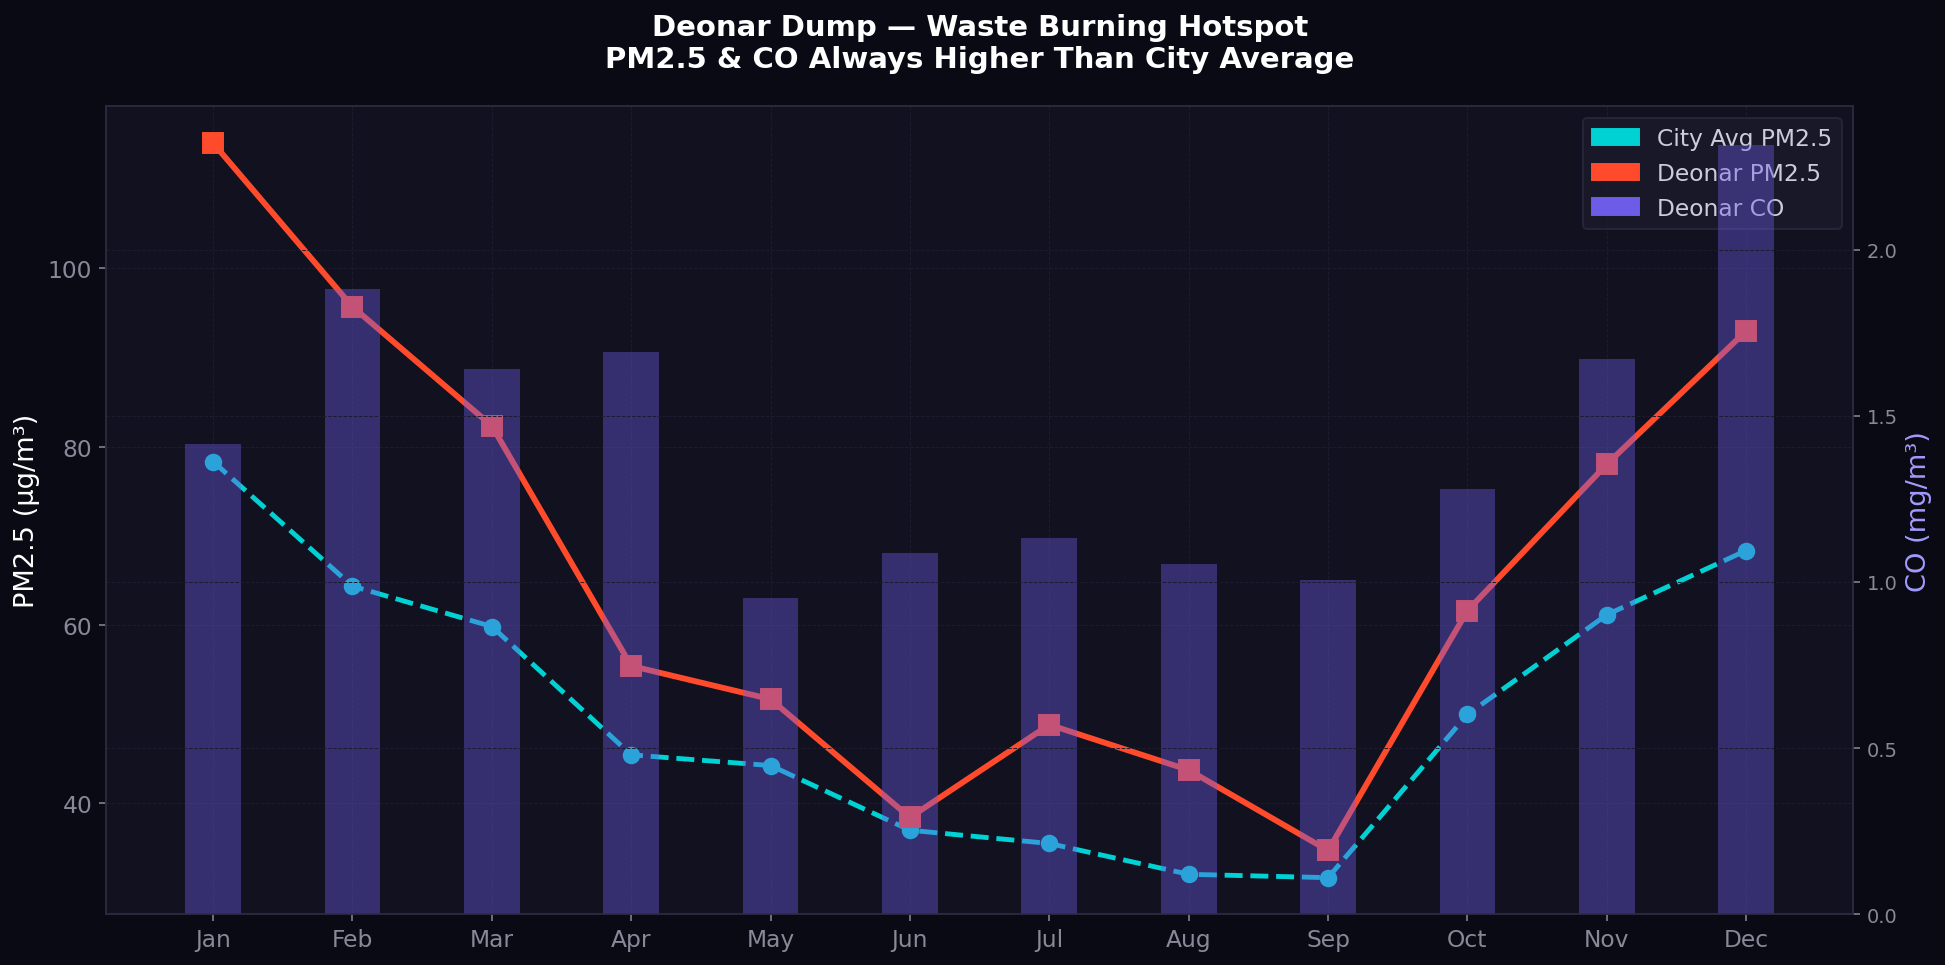

✓ Done — Deonar Hotspot


In [53]:
fig, ax = plt.subplots(figsize=(14, 7))
ax2 = ax.twinx()

MONTHS = ['Jan','Feb','Mar','Apr','May','Jun',
          'Jul','Aug','Sep','Oct','Nov','Dec']

deonar  = df[df['Station'] == 'Deonar'].groupby('Month')[['PM2.5','CO']].mean()
city    = df.groupby('Month')['PM2.5'].mean()

# city average line
ax.plot(city.index, city.values,
        color='#00d2d3', linewidth=2.5,
        marker='o', markersize=8,
        label='City Average PM2.5', linestyle='--')

# deonar PM2.5
ax.plot(deonar.index, deonar['PM2.5'],
        color='#ff4b2b', linewidth=3,
        marker='s', markersize=10,
        label='Deonar PM2.5')

# deonar CO bars
ax2.bar(deonar.index, deonar['CO'],
        color='#6c5ce7', alpha=0.4,
        width=0.4, label='Deonar CO (right axis)')

ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS, fontsize=12)
ax.set_ylabel('PM2.5 (μg/m³)', fontsize=14, color='white')
ax2.set_ylabel('CO (mg/m³)', fontsize=14, color='#a29bfe')
ax.set_title('Deonar Dump — Waste Burning Hotspot\nPM2.5 & CO Always Higher Than City Average',
             fontsize=15, color='white', pad=20)

import matplotlib.patches as mpatches
patches = [
    mpatches.Patch(color='#00d2d3', label='City Avg PM2.5'),
    mpatches.Patch(color='#ff4b2b', label='Deonar PM2.5'),
    mpatches.Patch(color='#6c5ce7', label='Deonar CO'),
]
ax.legend(handles=patches, fontsize=12)
ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.savefig('chart_8C_deonar_hotspot.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Deonar Hotspot")

Mazgaon Industrial Hourly Signature

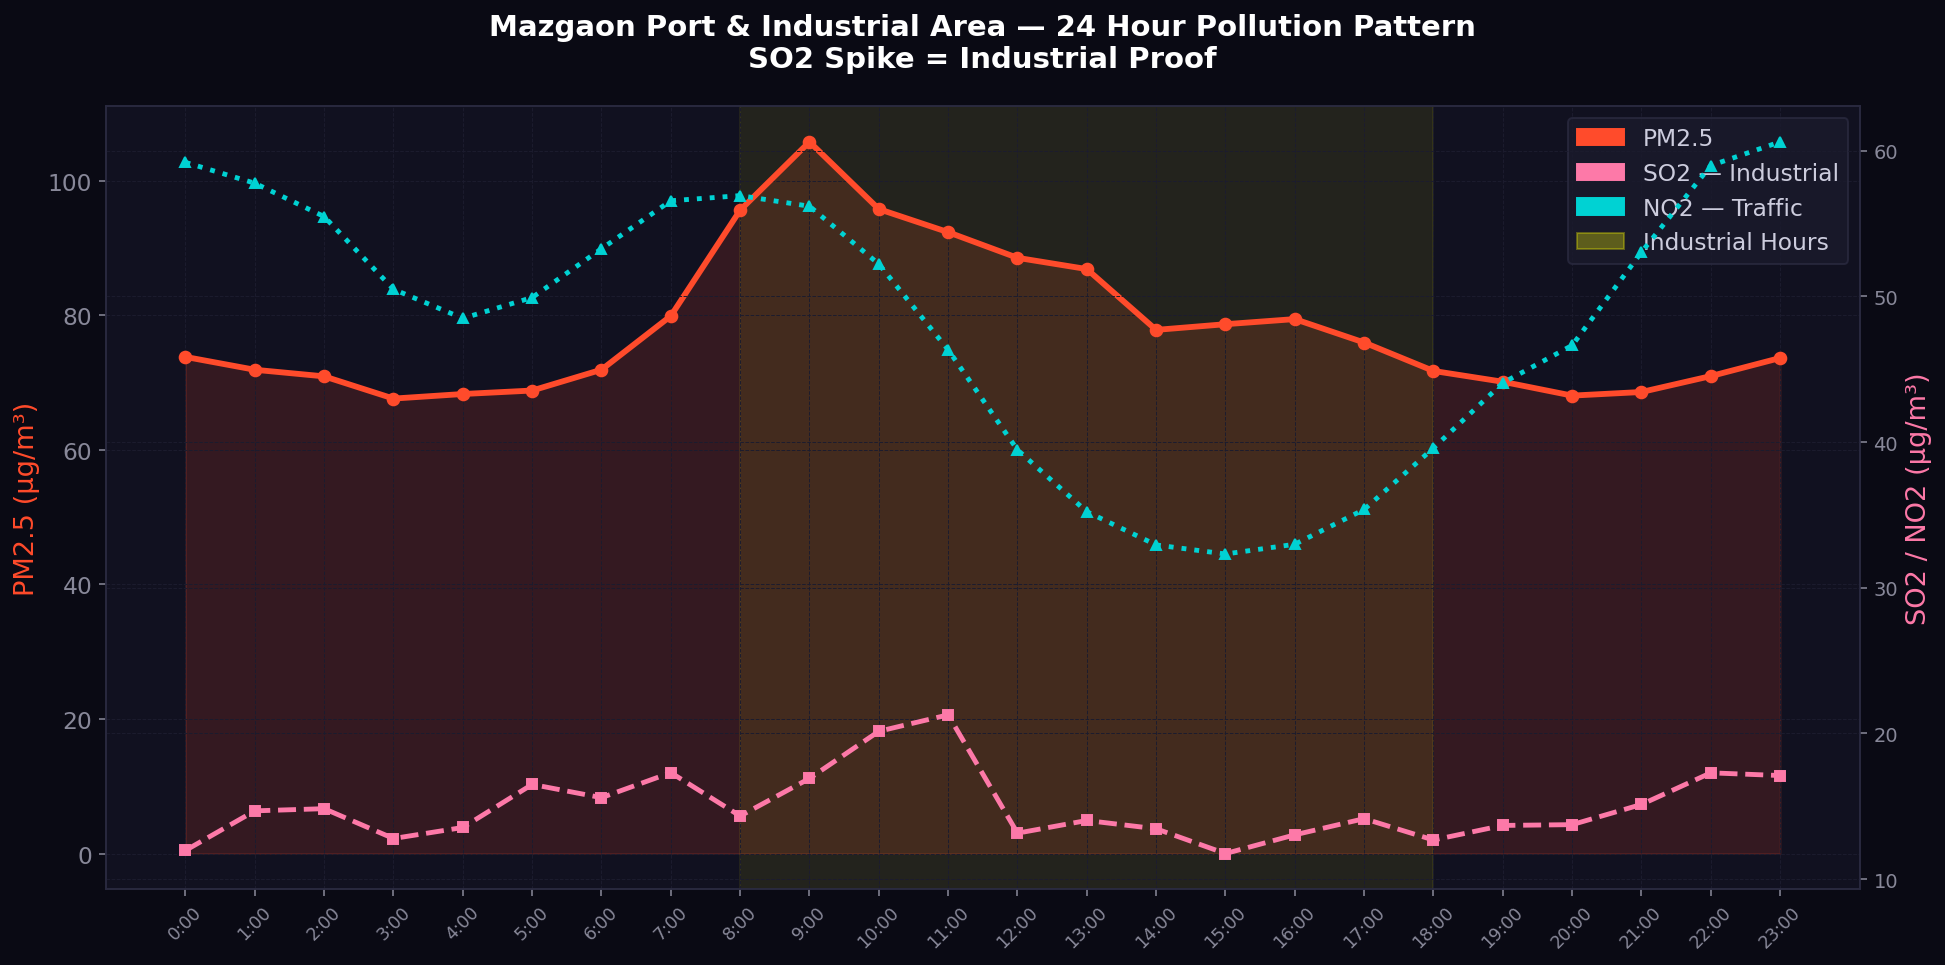

✓ Done — Mazgaon Industrial Signature


In [55]:
fig, ax = plt.subplots(figsize=(14, 7))
ax2 = ax.twinx()

mazg = df[df['Station'] == 'Mazgaon'].groupby('Hour')[['PM2.5','SO2','NO2']].mean()

ax.fill_between(mazg.index, mazg['PM2.5'],
                alpha=0.15, color='#ff4b2b')
ax.plot(mazg.index, mazg['PM2.5'],
        color='#ff4b2b', linewidth=3,
        marker='o', markersize=6, label='PM2.5')

ax2.plot(mazg.index, mazg['SO2'],
         color='#fd79a8', linewidth=2.5,
         ls='--', marker='s', markersize=5,
         label='SO2 (Industrial)')
ax2.plot(mazg.index, mazg['NO2'],
         color='#00d2d3', linewidth=2.5,
         ls=':', marker='^', markersize=5,
         label='NO2 (Traffic)')

# mark industrial shift hours
ax.axvspan(8, 18, alpha=0.08, color='yellow', label='Industrial Shift (8AM–6PM)')

ax.set_xticks(range(0, 24))
ax.set_xticklabels([f'{h}:00' for h in range(24)],
                   rotation=45, fontsize=9)
ax.set_ylabel('PM2.5 (μg/m³)', fontsize=14, color='#ff4b2b')
ax2.set_ylabel('SO2 / NO2 (μg/m³)', fontsize=14, color='#fd79a8')
ax.set_title('Mazgaon Port & Industrial Area — 24 Hour Pollution Pattern\nSO2 Spike = Industrial Proof',
             fontsize=15, color='white', pad=20)

import matplotlib.patches as mpatches
patches = [
    mpatches.Patch(color='#ff4b2b', label='PM2.5'),
    mpatches.Patch(color='#fd79a8', label='SO2 — Industrial'),
    mpatches.Patch(color='#00d2d3', label='NO2 — Traffic'),
    mpatches.Patch(color='yellow',  label='Industrial Hours', alpha=0.3),
]
ax.legend(handles=patches, fontsize=12)
ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.savefig('chart_8D_mazgaon_industrial.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Mazgaon Industrial Signature")

 How to Control: Policy Solutions Bar

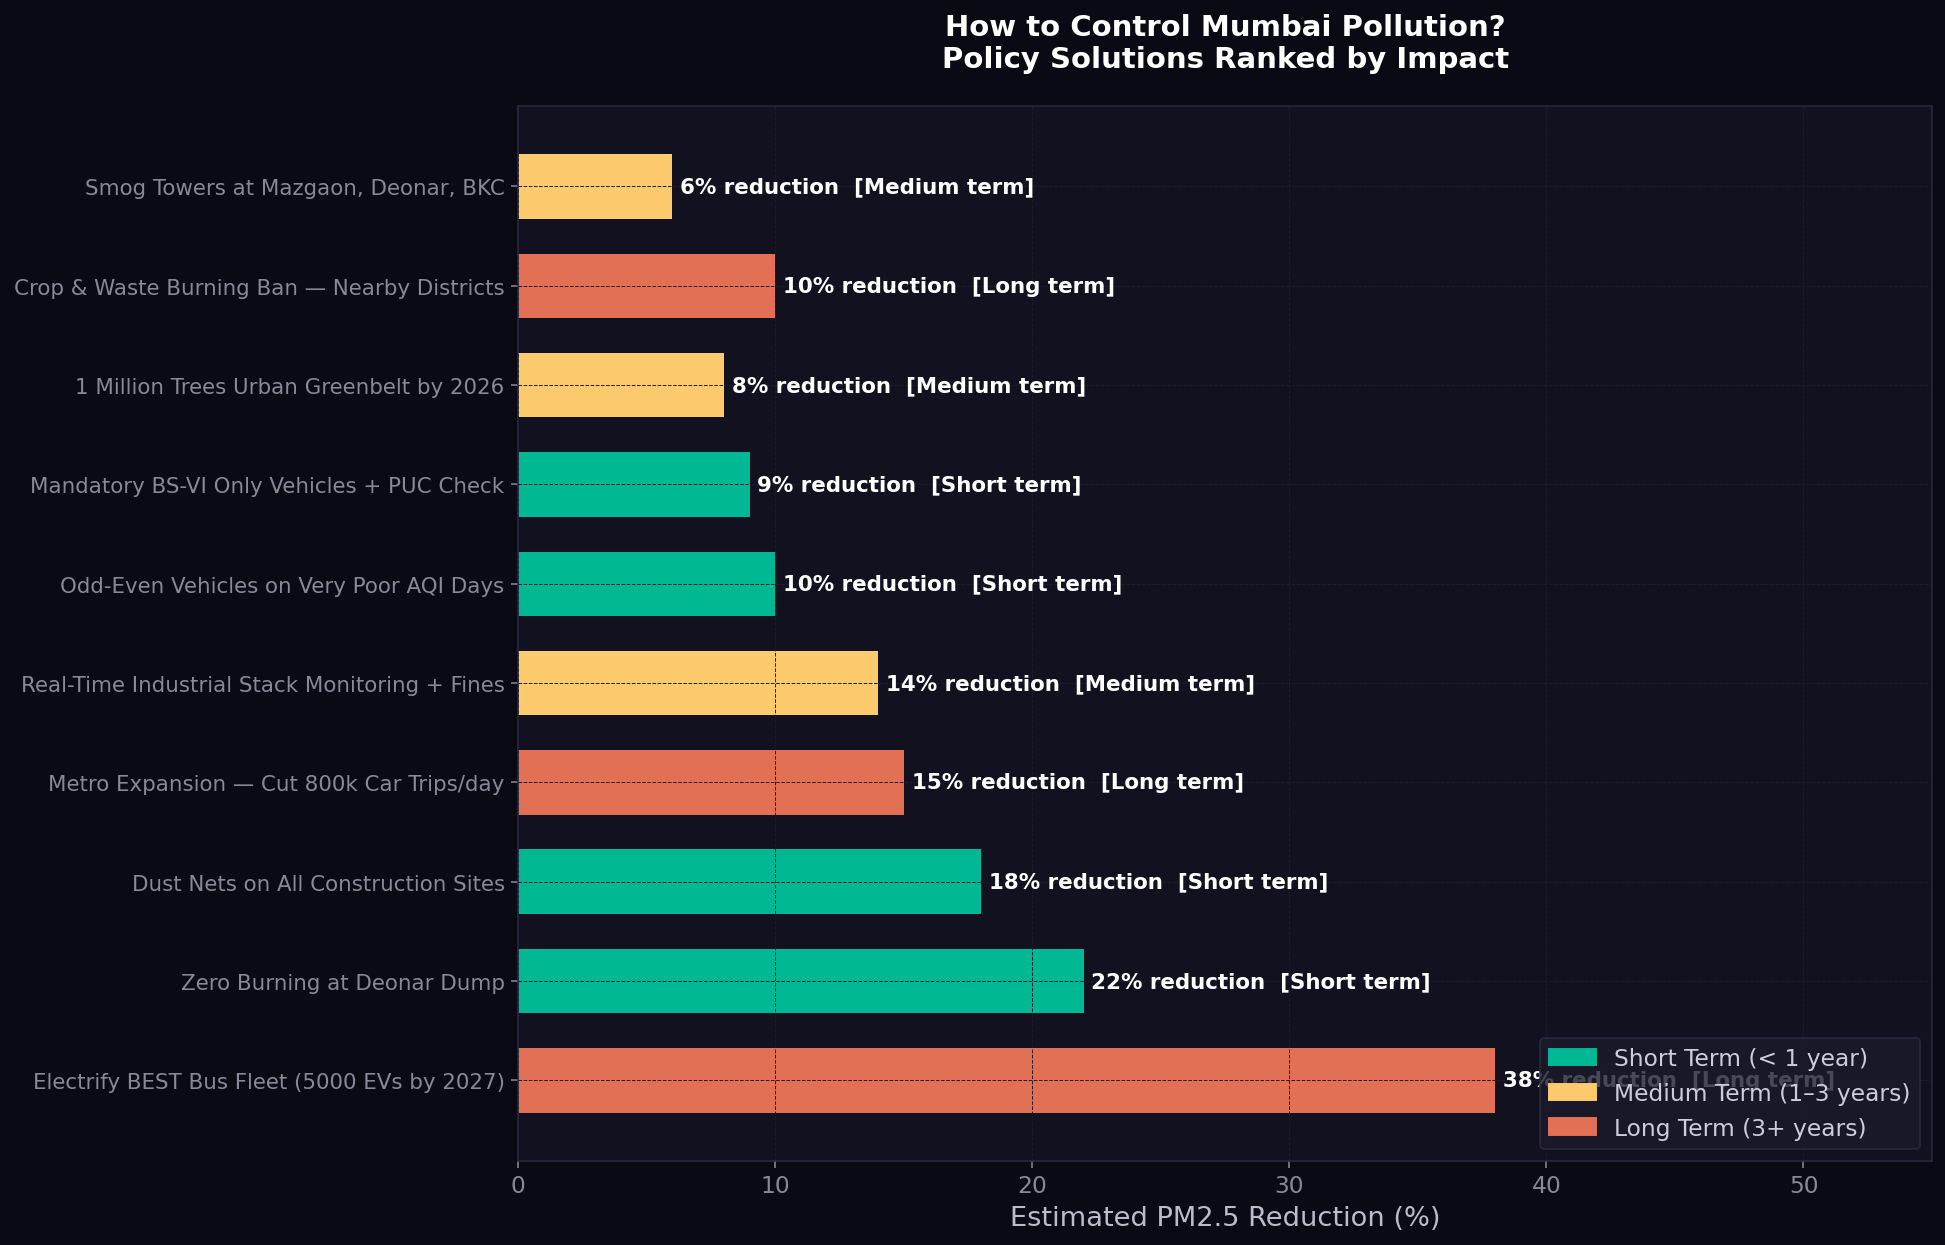

✓ Done — Policy Solutions


In [57]:
fig, ax = plt.subplots(figsize=(14, 9))

import matplotlib.patches as mpatches

solutions = [
    ('Electrify BEST Bus Fleet (5000 EVs by 2027)',     38, 'Long'),
    ('Zero Burning at Deonar Dump',                      22, 'Short'),
    ('Dust Nets on All Construction Sites',              18, 'Short'),
    ('Metro Expansion — Cut 800k Car Trips/day',         15, 'Long'),
    ('Real-Time Industrial Stack Monitoring + Fines',    14, 'Medium'),
    ('Odd-Even Vehicles on Very Poor AQI Days',          10, 'Short'),
    ('Mandatory BS-VI Only Vehicles + PUC Check',         9, 'Short'),
    ('1 Million Trees Urban Greenbelt by 2026',           8, 'Medium'),
    ('Crop & Waste Burning Ban — Nearby Districts',      10, 'Long'),
    ('Smog Towers at Mazgaon, Deonar, BKC',              6, 'Medium'),
]

labels     = [s[0] for s in solutions]
impacts    = [s[1] for s in solutions]
timelines  = [s[2] for s in solutions]

tl_colors  = {'Short': '#00b894', 'Medium': '#fdcb6e', 'Long': '#e17055'}
bar_colors = [tl_colors[t] for t in timelines]

y_pos = np.arange(len(solutions))
bars  = ax.barh(y_pos, impacts,
                color=bar_colors, edgecolor='none', height=0.65)

for bar, v, t in zip(bars, impacts, timelines):
    ax.text(v + 0.3,
            bar.get_y() + bar.get_height()/2,
            f'{v}% reduction  [{t} term]',
            va='center', fontsize=11, color='white', fontweight='bold')

ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=11)
ax.set_xlabel('Estimated PM2.5 Reduction (%)', fontsize=14)
ax.set_title('How to Control Mumbai Pollution?\nPolicy Solutions Ranked by Impact',
             fontsize=15, color='white', pad=20)

patches = [
    mpatches.Patch(color='#00b894', label='Short Term (< 1 year)'),
    mpatches.Patch(color='#fdcb6e', label='Medium Term (1–3 years)'),
    mpatches.Patch(color='#e17055', label='Long Term (3+ years)'),
]
ax.legend(handles=patches, fontsize=12, loc='lower right')
ax.tick_params(axis='x', labelsize=12)
ax.set_xlim(0, 55)

plt.tight_layout()
plt.savefig('chart_8E_policy_solutions.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Policy Solutions")

 Which Industry in Which Mumbai Area

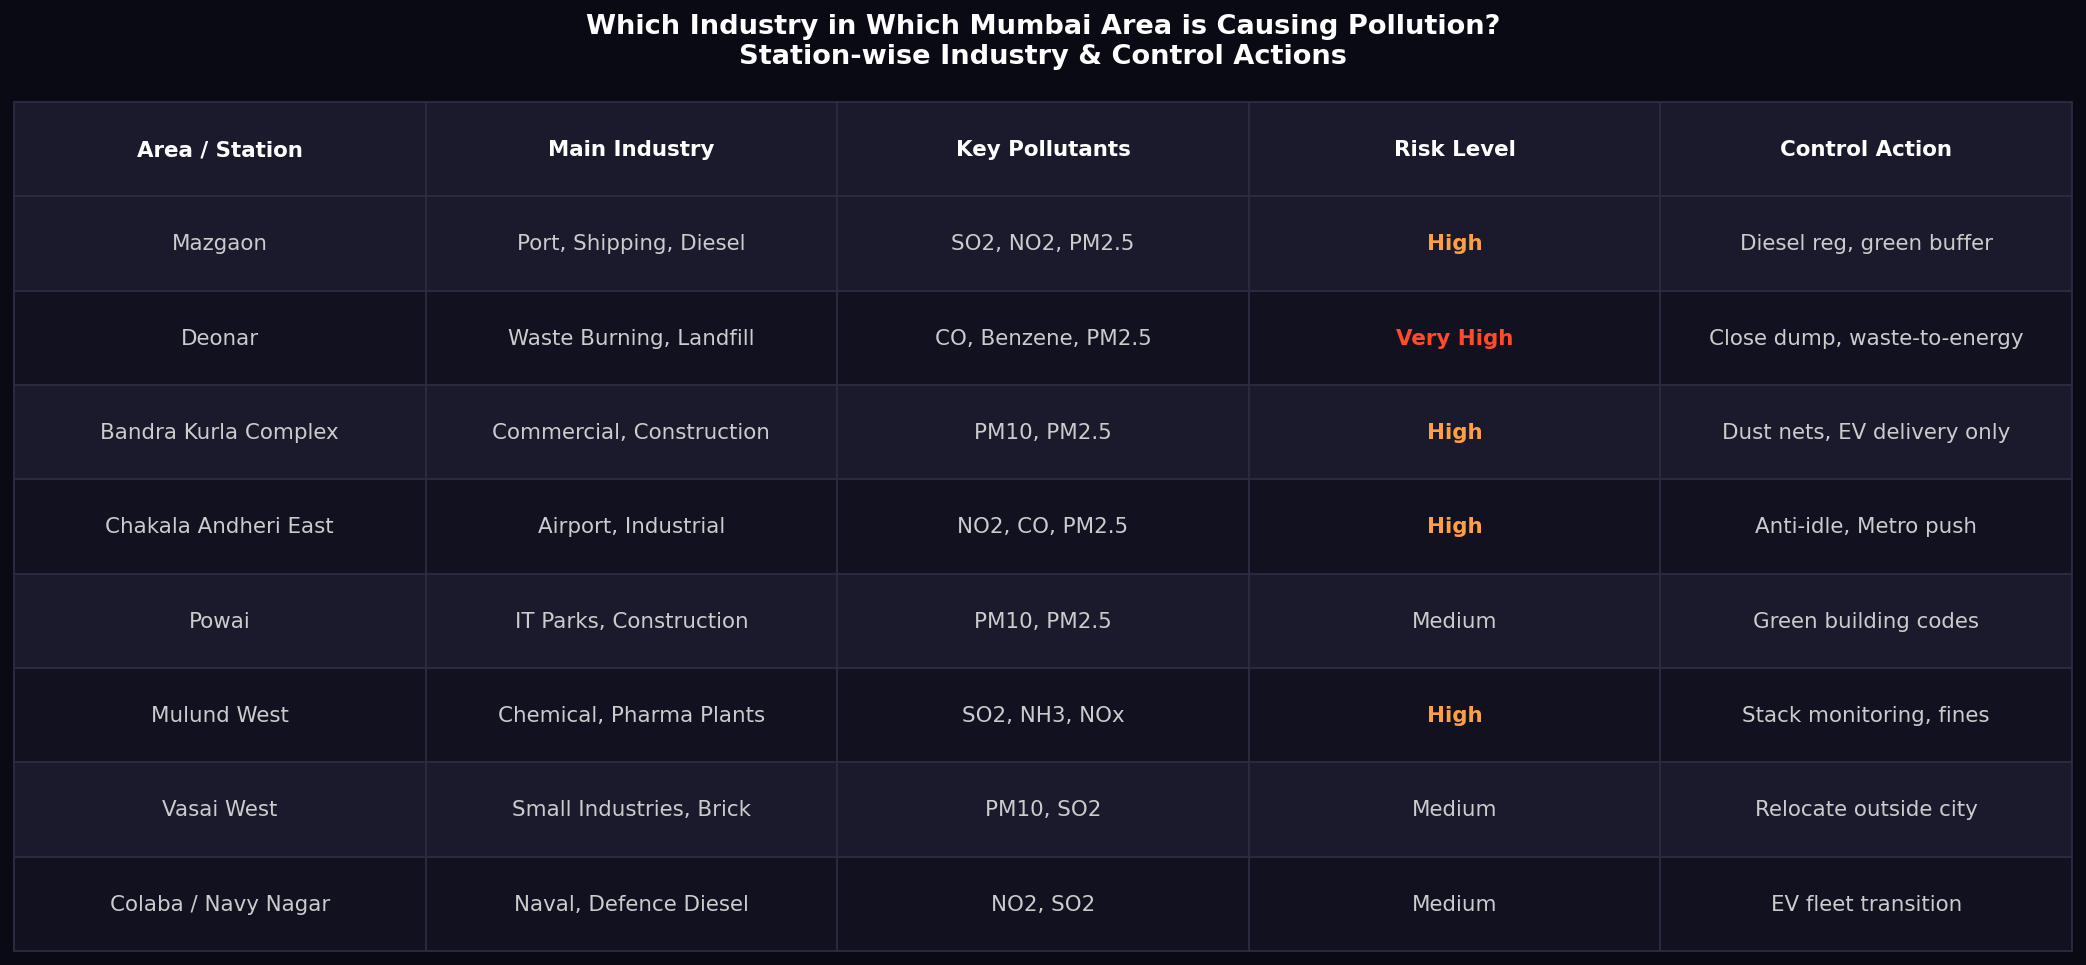

✓ Done — Industry Area Table


In [59]:
fig, ax = plt.subplots(figsize=(15, 7))
ax.axis('off')

rows = [
    ['Mazgaon',             'Port, Shipping, Diesel',    'SO2, NO2, PM2.5',  'High',   'Diesel reg, green buffer'],
    ['Deonar',              'Waste Burning, Landfill',   'CO, Benzene, PM2.5','Very High','Close dump, waste-to-energy'],
    ['Bandra Kurla Complex', 'Commercial, Construction', 'PM10, PM2.5',      'High',   'Dust nets, EV delivery only'],
    ['Chakala Andheri East', 'Airport, Industrial',      'NO2, CO, PM2.5',   'High',   'Anti-idle, Metro push'],
    ['Powai',               'IT Parks, Construction',   'PM10, PM2.5',      'Medium', 'Green building codes'],
    ['Mulund West',         'Chemical, Pharma Plants',  'SO2, NH3, NOx',    'High',   'Stack monitoring, fines'],
    ['Vasai West',          'Small Industries, Brick',  'PM10, SO2',        'Medium', 'Relocate outside city'],
    ['Colaba / Navy Nagar', 'Naval, Defence Diesel',    'NO2, SO2',         'Medium', 'EV fleet transition'],
]

col_labels = ['Area / Station', 'Main Industry', 'Key Pollutants',
              'Risk Level', 'Control Action']

tbl = ax.table(
    cellText=rows,
    colLabels=col_labels,
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 1]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)

for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor('#2a2a40')
    if row == 0:
        cell.set_facecolor('#1a1a2c')
        cell.get_text().set_color('white')
        cell.get_text().set_fontweight('bold')
    elif row % 2 == 0:
        cell.set_facecolor('#111120')
        cell.get_text().set_color('#cccccc')
    else:
        cell.set_facecolor('#1a1a2c')
        cell.get_text().set_color('#cccccc')
    txt = cell.get_text().get_text()
    if 'Very High' in txt:
        cell.get_text().set_color('#ff4b2b')
        cell.get_text().set_fontweight('bold')
    elif 'High' in txt:
        cell.get_text().set_color('#ff9f43')
        cell.get_text().set_fontweight('bold')

ax.set_title('Which Industry in Which Mumbai Area is Causing Pollution?\nStation-wise Industry & Control Actions',
             fontsize=14, color='white', pad=20)

plt.tight_layout()
plt.savefig('chart_8F_industry_area_table.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Industry Area Table")

 PM2.5 Forecast 3 Scenarios (2024–2030)

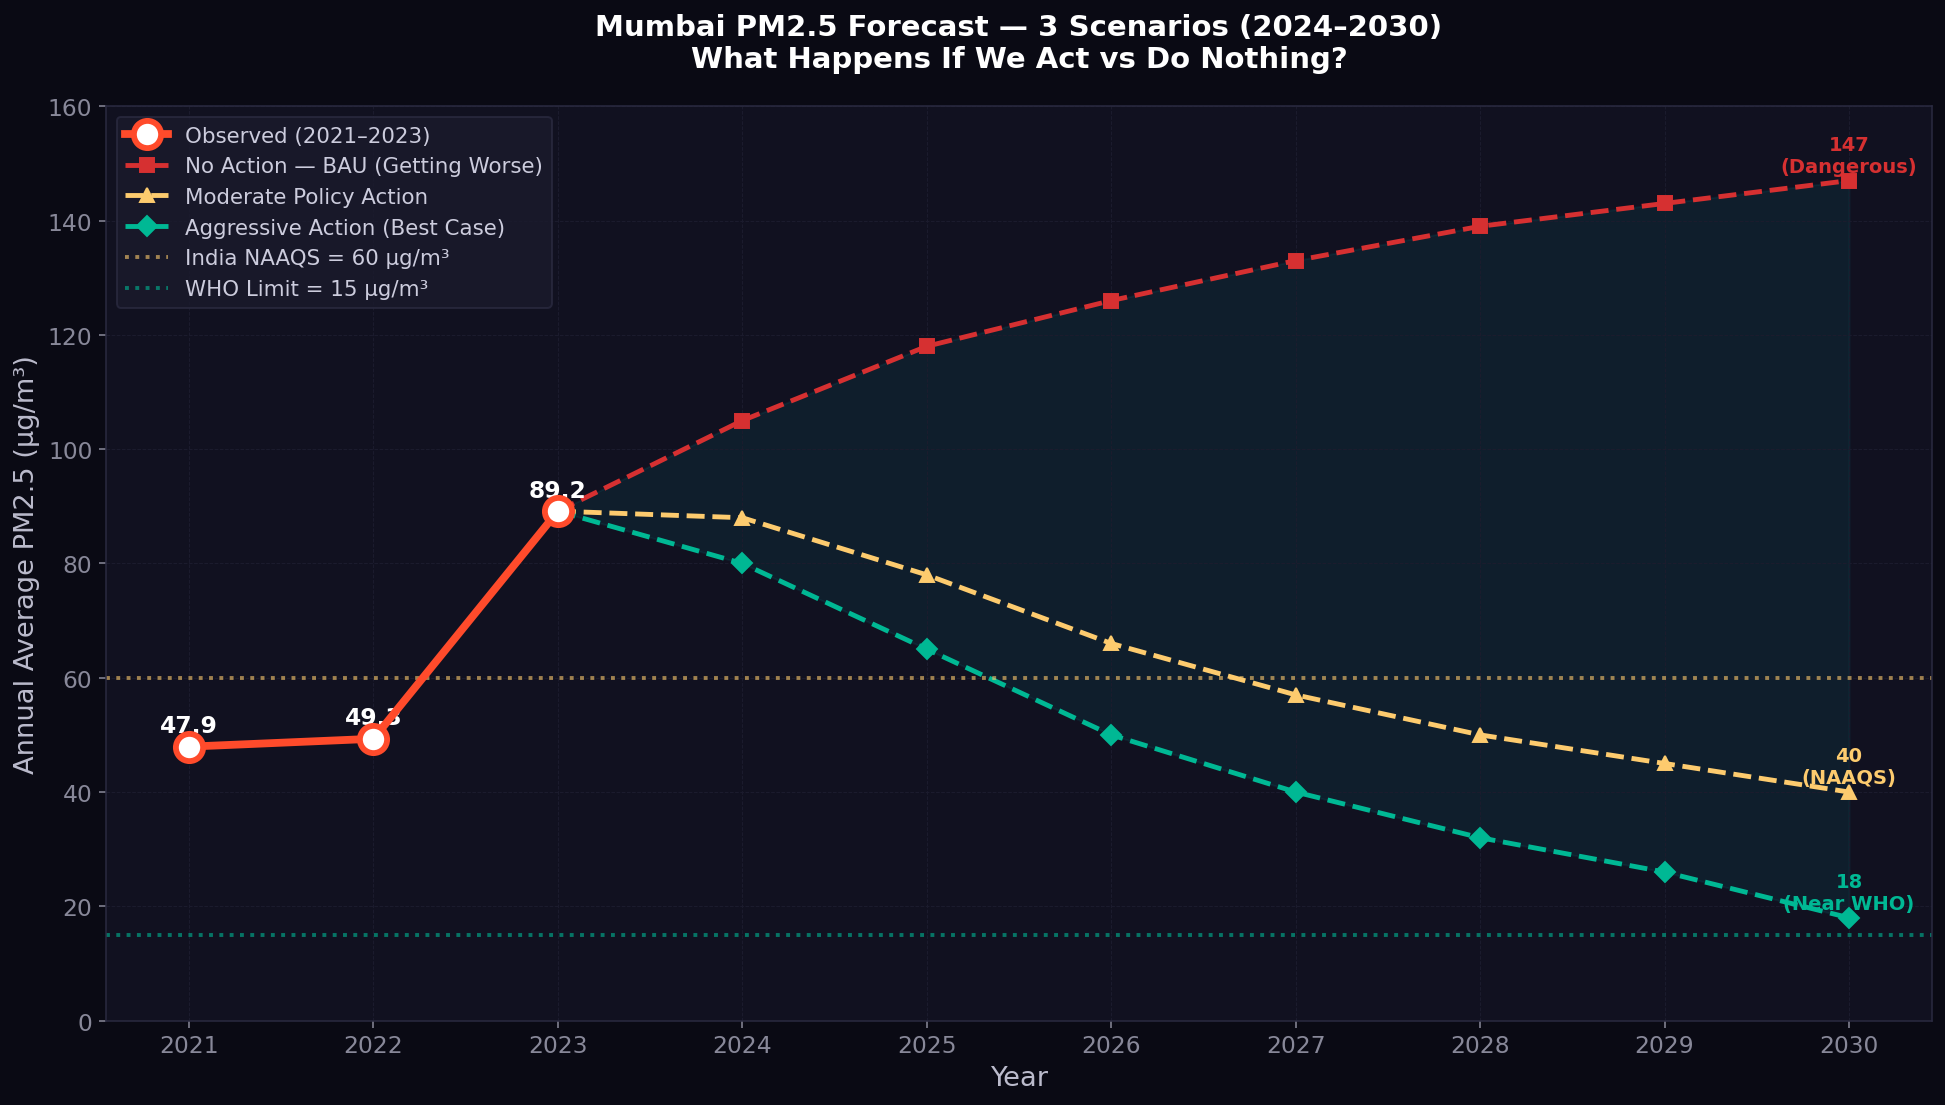

✓ Done — Forecast Scenarios


In [61]:
fig, ax = plt.subplots(figsize=(14, 8))

import numpy as np

# observed data
years_obs = [2021, 2022, 2023]
vals_obs  = [47.94, 49.32, 89.15]

# forecast years
years_fc  = [2023, 2024, 2025, 2026, 2027, 2028, 2029, 2030]

# 3 scenarios
bau  = [89.15, 105, 118, 126, 133, 139, 143, 147]  # no action
mod  = [89.15,  88,  78,  66,  57,  50,  45,  40]  # moderate policy
agg  = [89.15,  80,  65,  50,  40,  32,  26,  18]  # aggressive action

# observed line
ax.plot(years_obs, vals_obs,
        color='#ff4b2b', linewidth=4,
        marker='o', markersize=14,
        markerfacecolor='white',
        markeredgecolor='#ff4b2b',
        markeredgewidth=3,
        label='Observed (2021–2023)', zorder=5)

# label observed points
for yr, v in zip(years_obs, vals_obs):
    ax.text(yr, v + 2.5, f'{v:.1f}',
            ha='center', fontsize=12,
            color='white', fontweight='bold')

# BAU scenario
ax.plot(years_fc, bau,
        color='#d63031', linewidth=2.5,
        ls='--', marker='s', markersize=7,
        label='No Action — BAU (Getting Worse)')

# moderate scenario
ax.plot(years_fc, mod,
        color='#fdcb6e', linewidth=2.5,
        ls='--', marker='^', markersize=7,
        label='Moderate Policy Action')

# aggressive scenario
ax.plot(years_fc, agg,
        color='#00b894', linewidth=2.5,
        ls='--', marker='D', markersize=7,
        label='Aggressive Action (Best Case)')

# fill between scenarios
ax.fill_between(years_fc, bau, agg,
                alpha=0.07, color='#00d2d3')

# reference lines
ax.axhline(60, color='#fdcb6e', ls=':', lw=2,
           alpha=0.6, label='India NAAQS = 60 μg/m³')
ax.axhline(15, color='#00b894', ls=':', lw=2,
           alpha=0.6, label='WHO Limit = 15 μg/m³')

# 2030 target labels
ax.text(2030, 147 + 1.5, '147\n(Dangerous)', ha='center',
        fontsize=10, color='#d63031', fontweight='bold')
ax.text(2030,  40 + 1.5,  '40\n(NAAQS)',    ha='center',
        fontsize=10, color='#fdcb6e', fontweight='bold')
ax.text(2030,  18 + 1.5,  '18\n(Near WHO)', ha='center',
        fontsize=10, color='#00b894', fontweight='bold')

ax.set_xticks(range(2021, 2031))
ax.set_xticklabels(range(2021, 2031), fontsize=12)
ax.set_xlabel('Year', fontsize=14)
ax.set_ylabel('Annual Average PM2.5 (μg/m³)', fontsize=14)
ax.set_title('Mumbai PM2.5 Forecast — 3 Scenarios (2024–2030)\nWhat Happens If We Act vs Do Nothing?',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=11)
ax.tick_params(axis='y', labelsize=12)
ax.set_ylim(0, 160)

plt.tight_layout()
plt.savefig('chart_9A_forecast_scenarios.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Forecast Scenarios")

 How Much Reduction Needed to Meet Each Standard

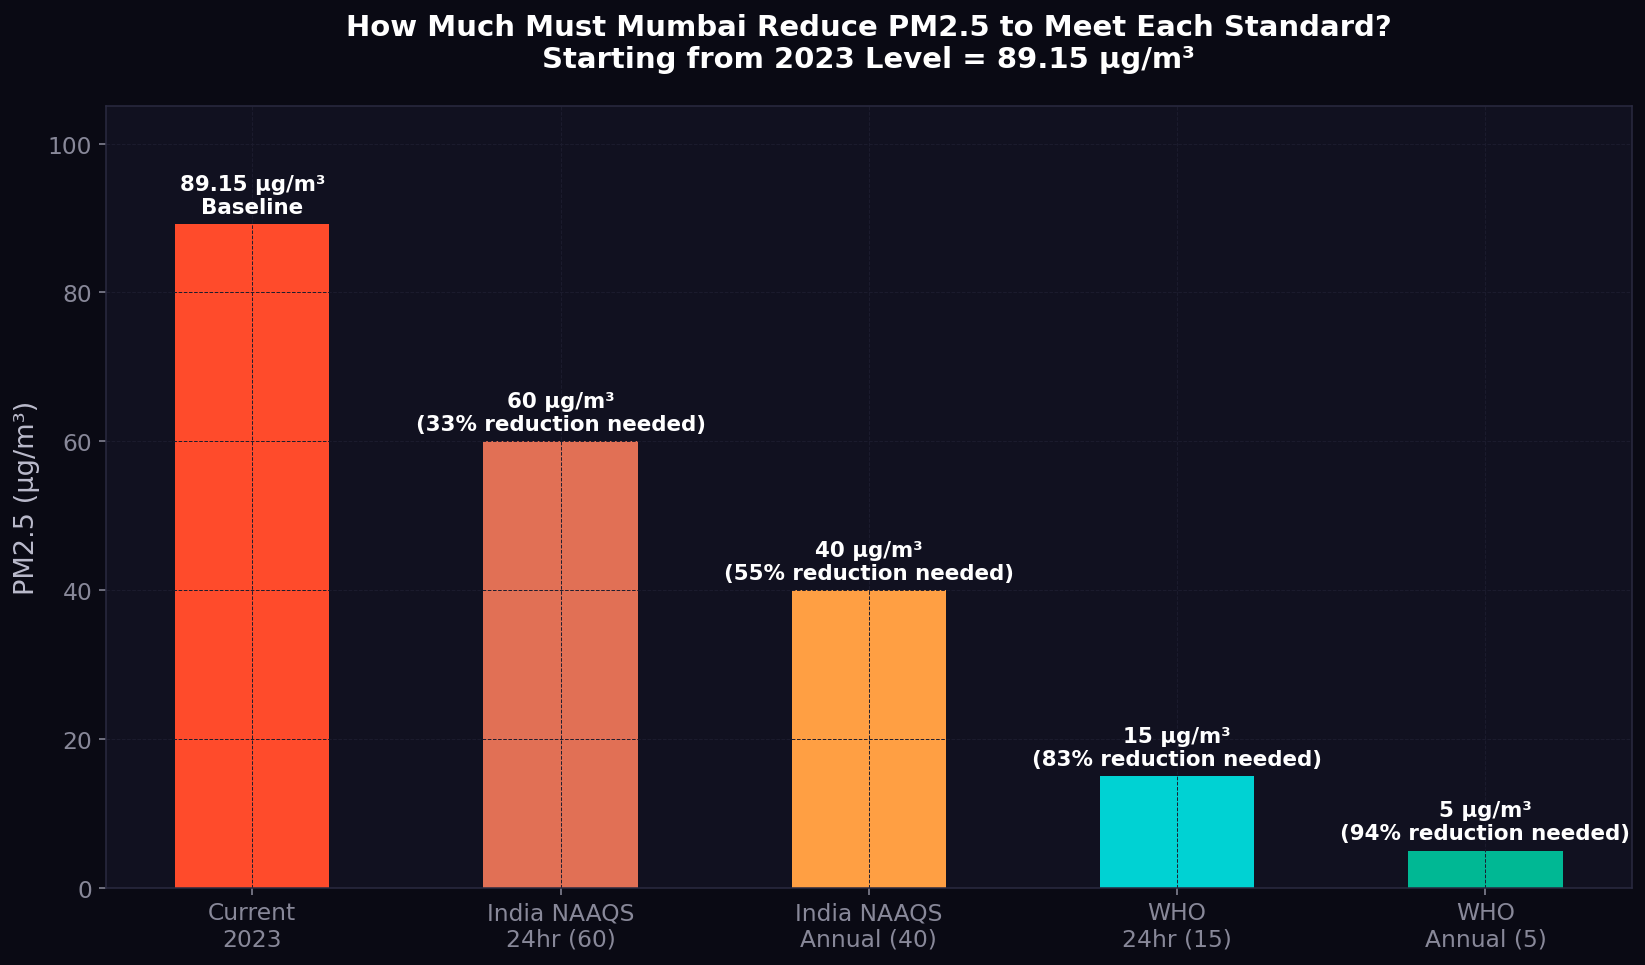

✓ Done — Reduction Needed


In [63]:
fig, ax = plt.subplots(figsize=(12, 7))

current = 89.15

targets = {
    'Current\n2023'       : 89.15,
    'India NAAQS\n24hr (60)' : 60,
    'India NAAQS\nAnnual (40)': 40,
    'WHO\n24hr (15)'      : 15,
    'WHO\nAnnual (5)'     : 5,
}

colors = ['#ff4b2b','#e17055','#ff9f43','#00d2d3','#00b894']

bars = ax.bar(targets.keys(), targets.values(),
              color=colors, edgecolor='none', width=0.5)

for bar, (label, val) in zip(bars, targets.items()):
    pct = (1 - val / current) * 100 if val < current else 0
    txt = f'{val} μg/m³\n({pct:.0f}% reduction needed)' if pct > 0 else f'{val} μg/m³\nBaseline'
    ax.text(bar.get_x() + bar.get_width()/2,
            val + 1.5,
            txt,
            ha='center', fontsize=11,
            color='white', fontweight='bold')

ax.set_ylabel('PM2.5 (μg/m³)', fontsize=14)
ax.set_title('How Much Must Mumbai Reduce PM2.5 to Meet Each Standard?\nStarting from 2023 Level = 89.15 μg/m³',
             fontsize=15, color='white', pad=20)
ax.tick_params(axis='both', labelsize=12)
ax.set_ylim(0, 105)

plt.tight_layout()
plt.savefig('chart_9B_reduction_needed.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Reduction Needed")

 Year on Year % Change per Pollutant

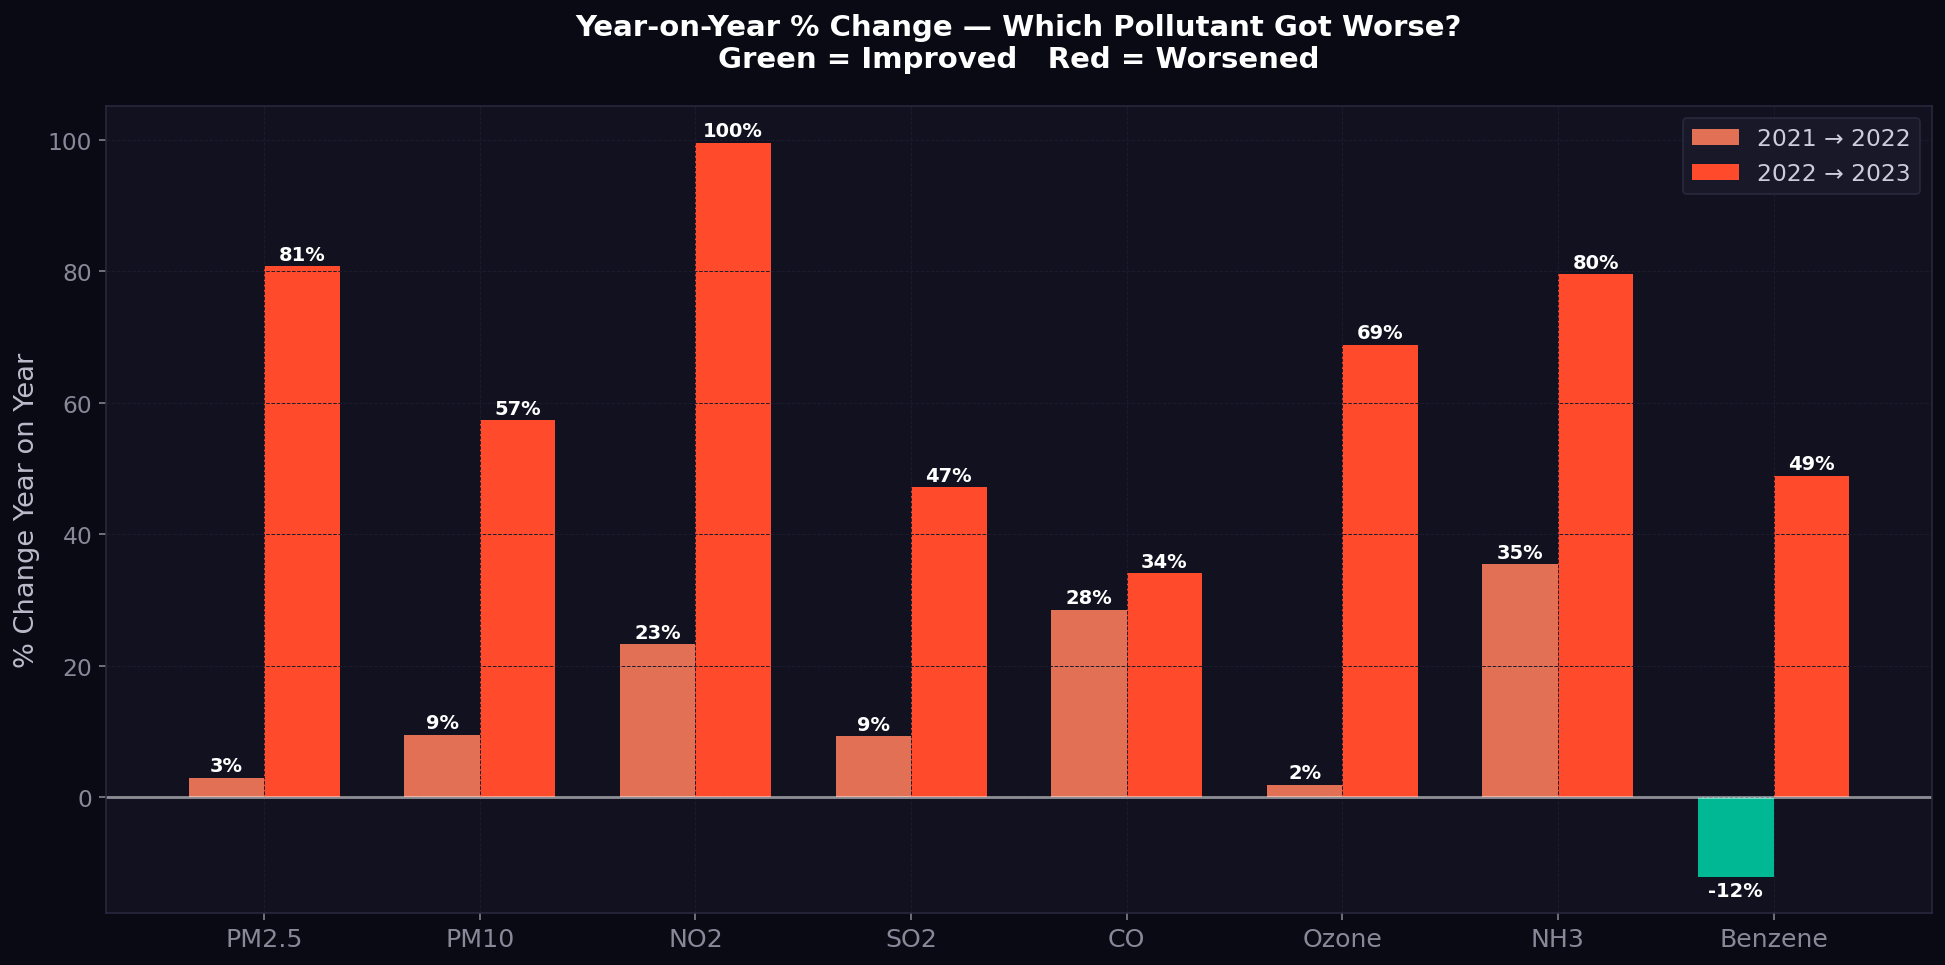

✓ Done — Year on Year Change


In [65]:
fig, ax = plt.subplots(figsize=(14, 7))

polls_yoy = ['PM2.5','PM10','NO2','SO2','CO','Ozone','NH3','Benzene']
yr_avg    = df.groupby('Year')[polls_yoy].mean()

pct_2122  = ((yr_avg.loc[2022] - yr_avg.loc[2021]) / yr_avg.loc[2021] * 100)
pct_2223  = ((yr_avg.loc[2023] - yr_avg.loc[2022]) / yr_avg.loc[2022] * 100)

x = np.arange(len(polls_yoy))
w = 0.35

bars1 = ax.bar(x - w/2, pct_2122.values, width=w,
               color=['#00b894' if v < 0 else '#e17055' for v in pct_2122.values],
               edgecolor='none', label='2021 → 2022')

bars2 = ax.bar(x + w/2, pct_2223.values, width=w,
               color=['#00b894' if v < 0 else '#ff4b2b' for v in pct_2223.values],
               edgecolor='none', label='2022 → 2023')

for bar, v in zip(bars1, pct_2122.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + (1 if v >= 0 else -3),
            f'{v:.0f}%',
            ha='center', fontsize=10, color='white', fontweight='bold')

for bar, v in zip(bars2, pct_2223.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + (1 if v >= 0 else -3),
            f'{v:.0f}%',
            ha='center', fontsize=10, color='white', fontweight='bold')

ax.axhline(0, color='white', lw=1.5, alpha=0.5)
ax.set_xticks(x)
ax.set_xticklabels(polls_yoy, fontsize=13)
ax.set_ylabel('% Change Year on Year', fontsize=14)
ax.set_title('Year-on-Year % Change — Which Pollutant Got Worse?\nGreen = Improved   Red = Worsened',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12)
ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.savefig('chart_9C_yoy_change.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Year on Year Change")

Monthly Rolling Time Series (Full 2021–2023)

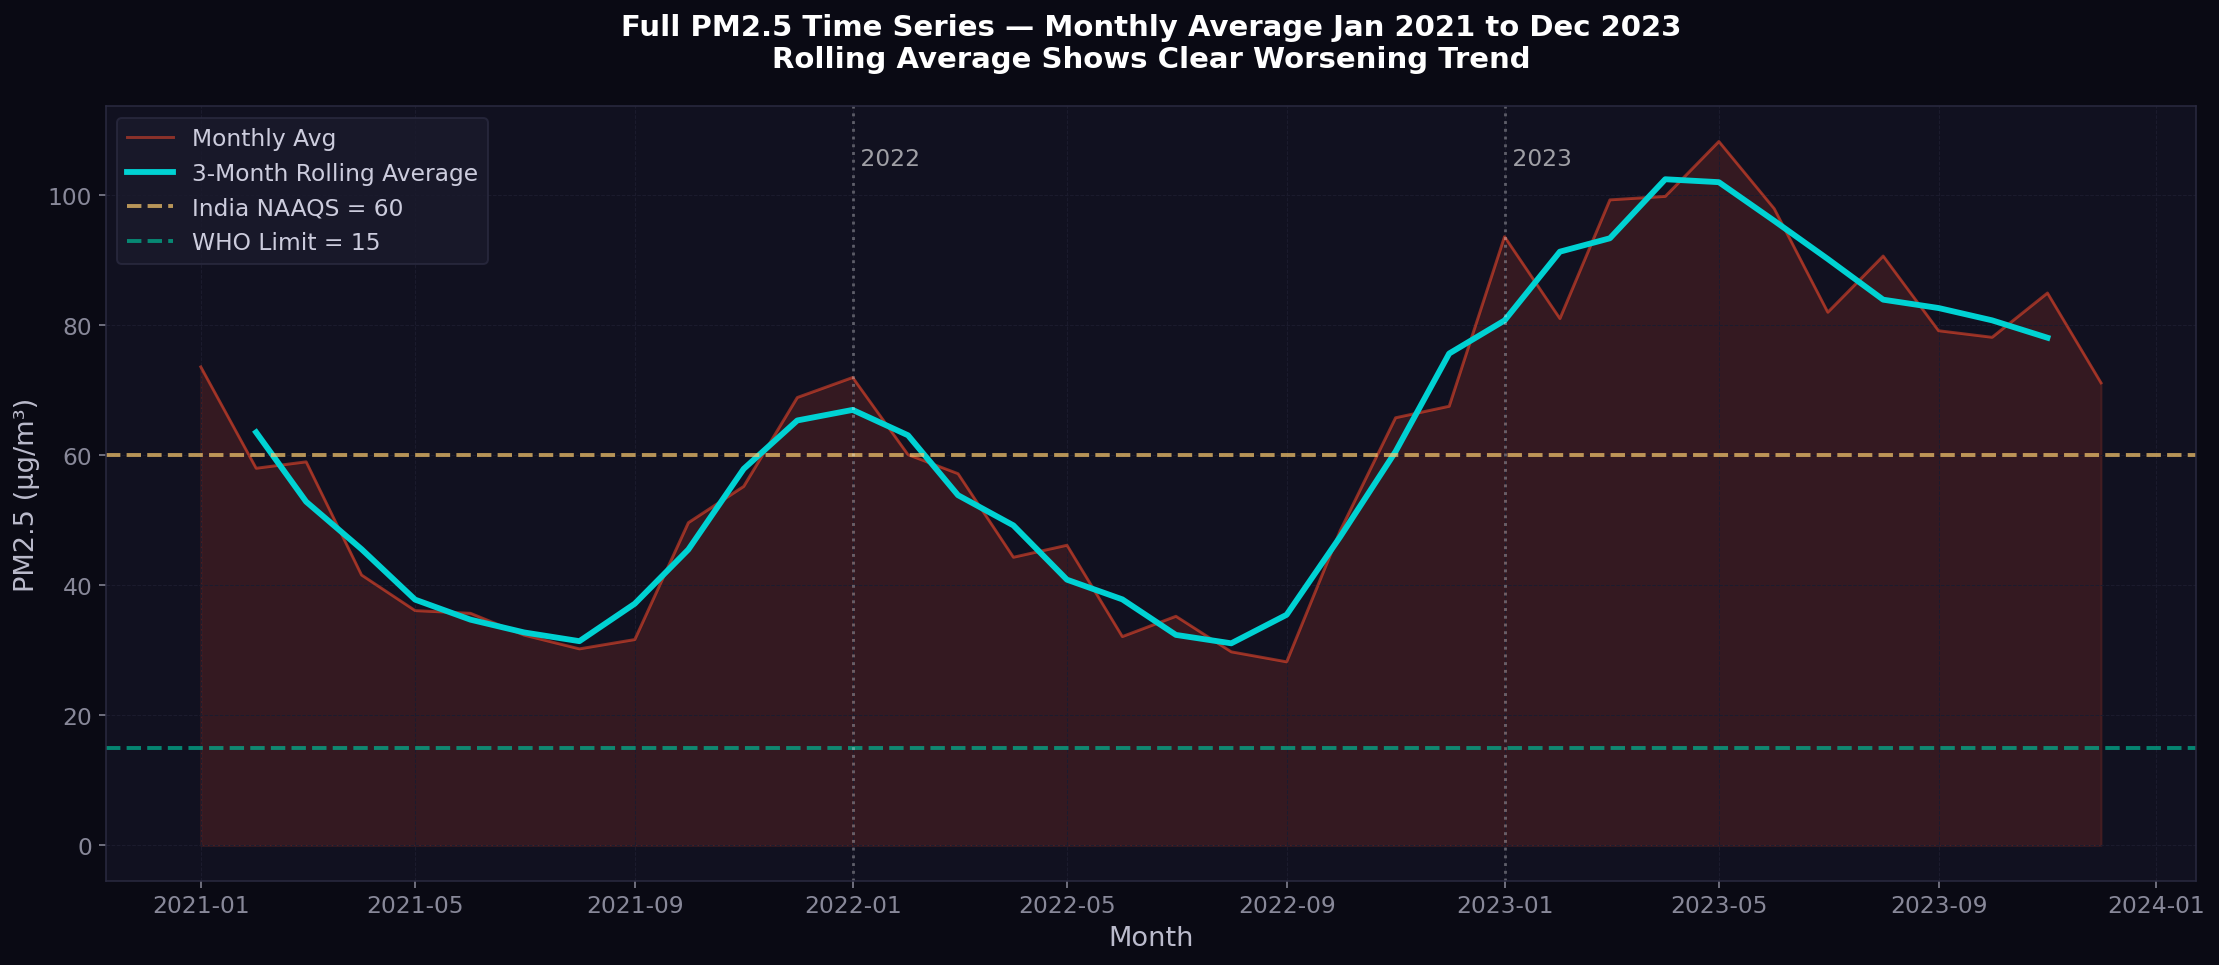

✓ Done — Rolling Time Series


In [67]:
fig, ax = plt.subplots(figsize=(16, 7))

# monthly average across full period
mts       = df.groupby(df['From Date'].dt.to_period('M'))['PM2.5'].mean()
mts.index = mts.index.to_timestamp()

# raw monthly line
ax.fill_between(mts.index, mts.values,
                alpha=0.15, color='#ff4b2b')
ax.plot(mts.index, mts.values,
        color='#ff4b2b', lw=1.5, alpha=0.5, label='Monthly Avg')

# 3 month rolling average
roll3 = mts.rolling(3, center=True).mean()
ax.plot(roll3.index, roll3.values,
        color='#00d2d3', lw=3,
        label='3-Month Rolling Average')

# reference lines
ax.axhline(60, color='#fdcb6e', ls='--', lw=2,
           alpha=0.7, label='India NAAQS = 60')
ax.axhline(15, color='#00b894', ls='--', lw=2,
           alpha=0.7, label='WHO Limit = 15')

# year dividers
import matplotlib.patches as mpatches
for yr in [2022, 2023]:
    ax.axvline(pd.Timestamp(f'{yr}-01-01'),
               color='white', lw=1.5, alpha=0.3, ls=':')
    ax.text(pd.Timestamp(f'{yr}-01-01'), ax.get_ylim()[1] * 0.92,
            f' {yr}', fontsize=12, color='white', alpha=0.6)

ax.set_ylabel('PM2.5 (μg/m³)', fontsize=14)
ax.set_xlabel('Month', fontsize=14)
ax.set_title('Full PM2.5 Time Series — Monthly Average Jan 2021 to Dec 2023\nRolling Average Shows Clear Worsening Trend',
             fontsize=15, color='white', pad=20)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('chart_9D_rolling_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Rolling Time Series")

Master Summary Dashboard (All Key Numbers)

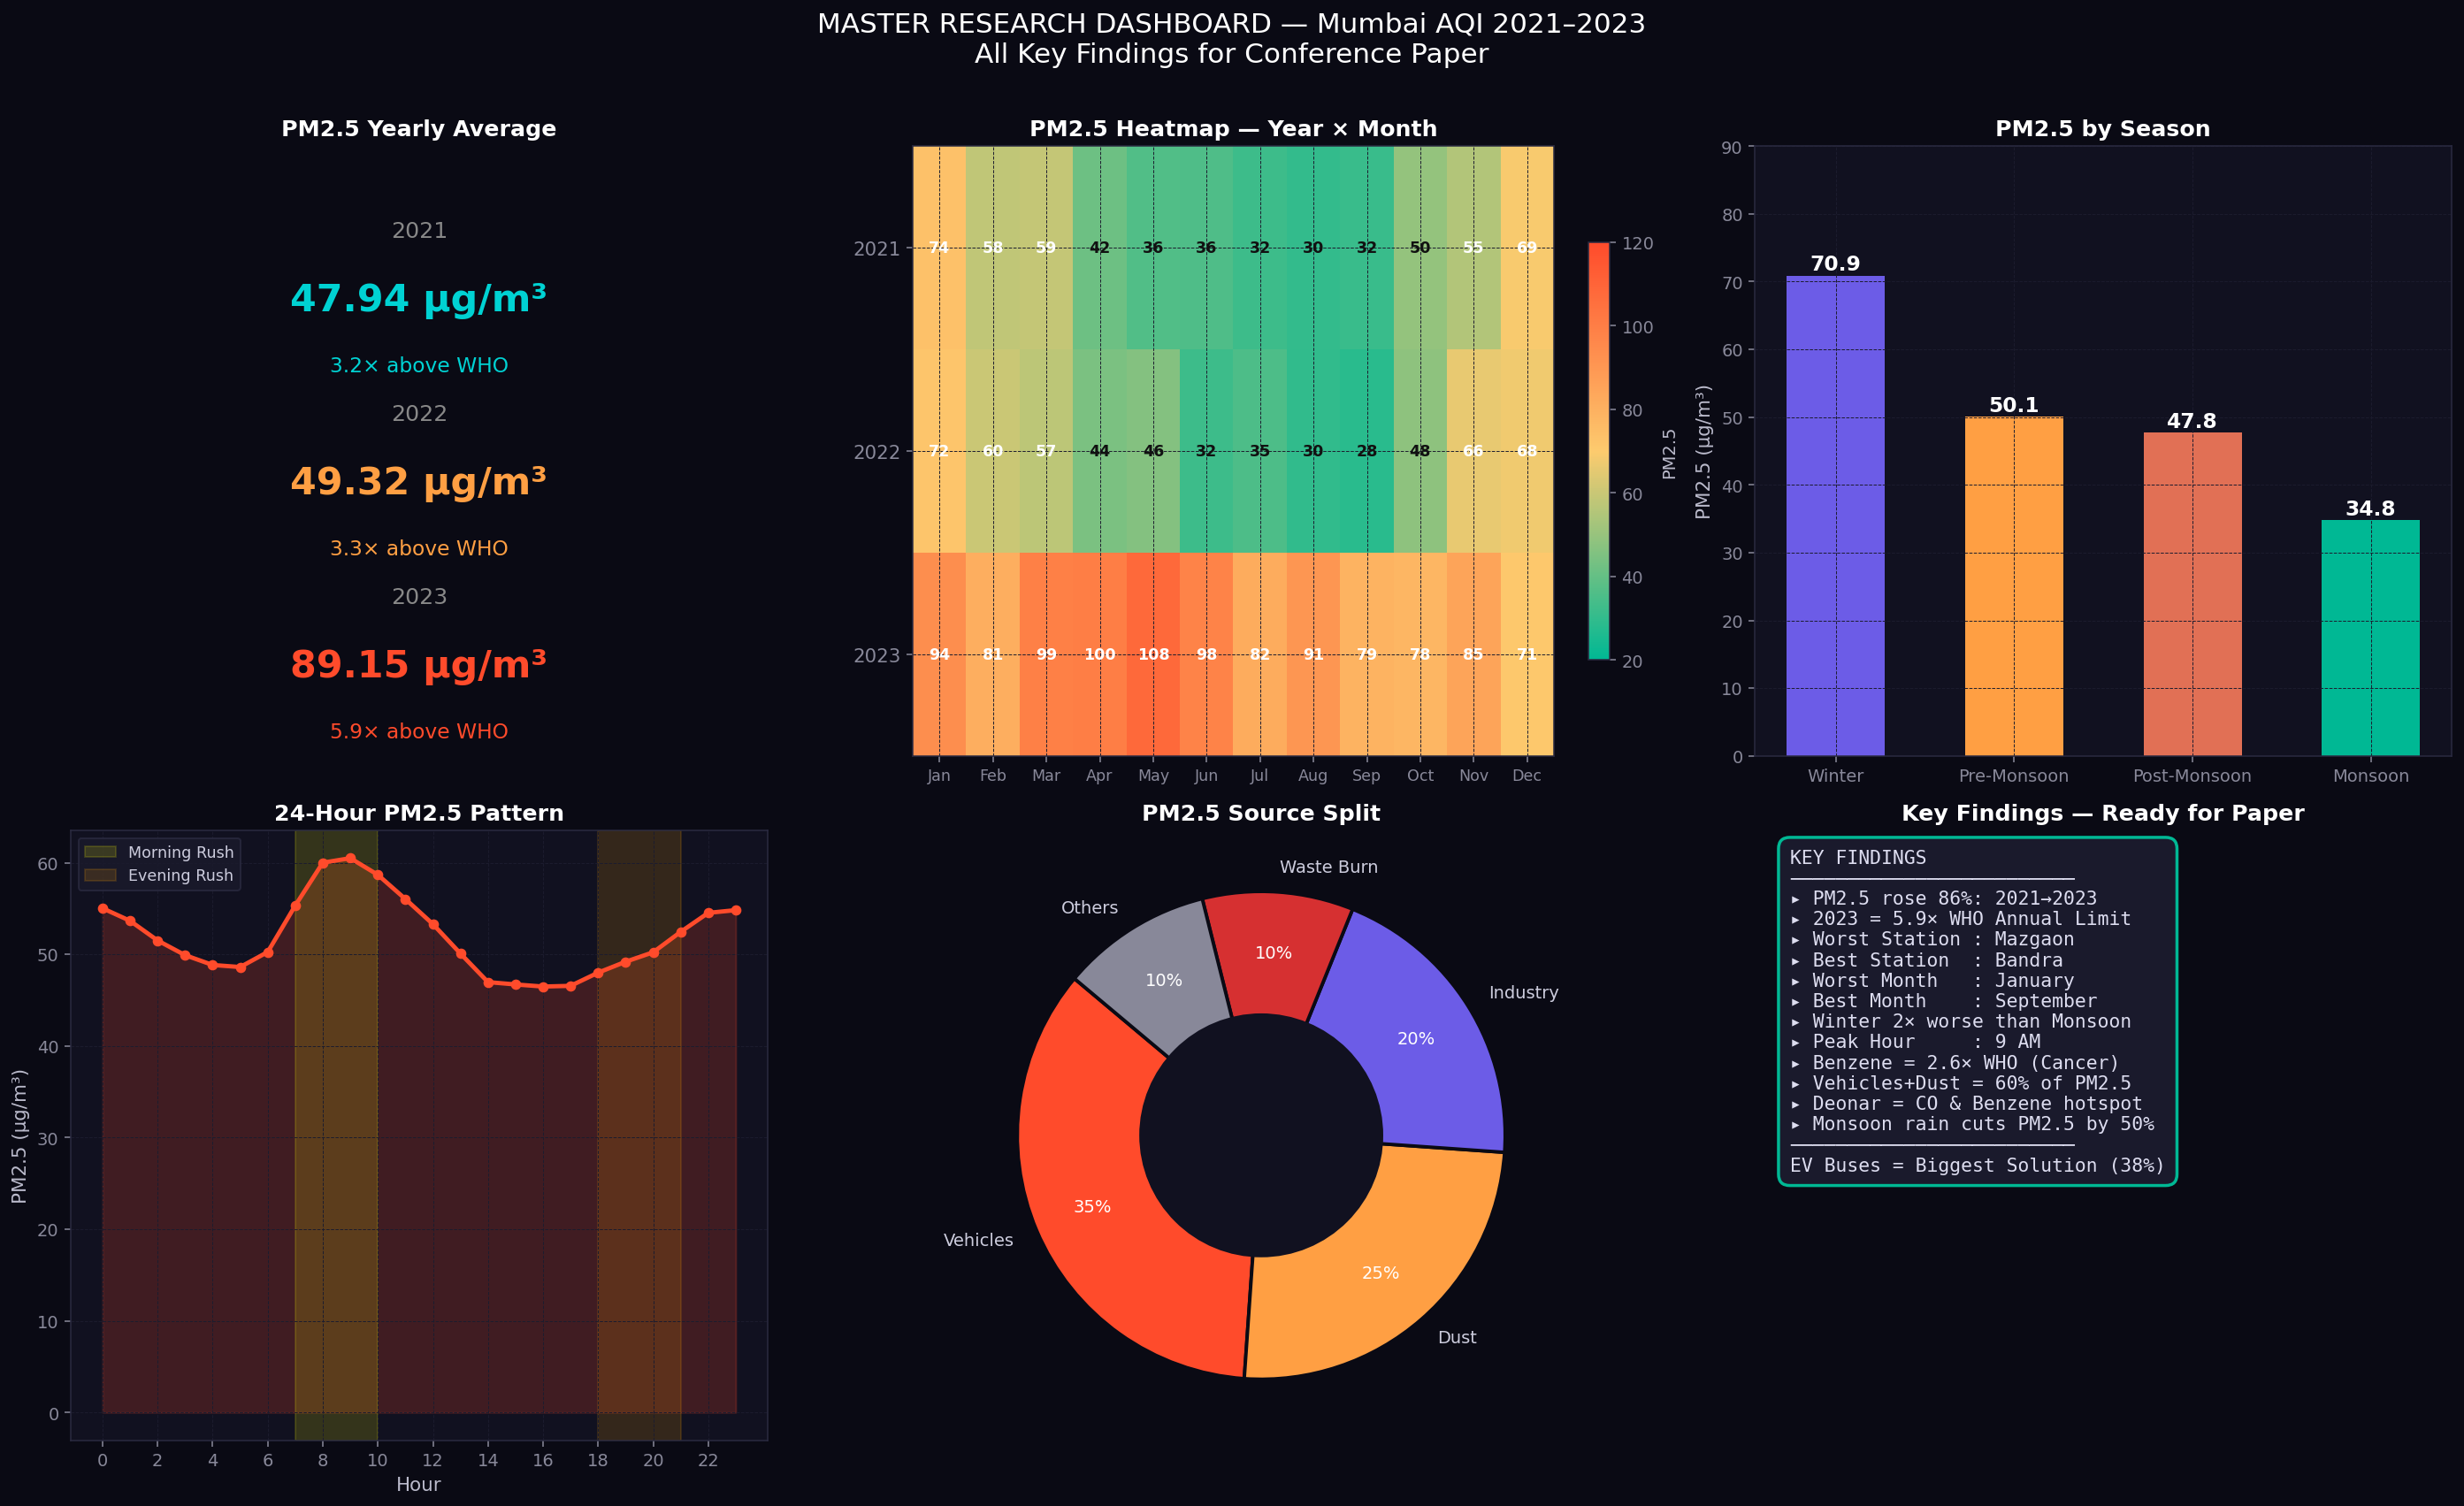

✓ Done — Master Dashboard


In [69]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('MASTER RESEARCH DASHBOARD — Mumbai AQI 2021–2023\nAll Key Findings for Conference Paper',
             fontsize=16, color='white', y=1.01)

MONTHS = ['Jan','Feb','Mar','Apr','May','Jun',
          'Jul','Aug','Sep','Oct','Nov','Dec']

# ── Panel 1: PM2.5 Yearly Big Numbers ───────────────────────────
ax = axes[0, 0]
ax.axis('off')
for i, (yr, val, who) in enumerate([
    (2021, 47.94, '3.2×'),
    (2022, 49.32, '3.3×'),
    (2023, 89.15, '5.9×')
]):
    clr = ['#00d2d3','#ff9f43','#ff4b2b'][i]
    ax.text(0.5, 0.85 - i*0.30, str(yr),
            ha='center', transform=ax.transAxes,
            fontsize=13, color='#888888')
    ax.text(0.5, 0.73 - i*0.30, f'{val} μg/m³',
            ha='center', transform=ax.transAxes,
            fontsize=22, fontweight='bold', color=clr)
    ax.text(0.5, 0.63 - i*0.30, f'{who} above WHO',
            ha='center', transform=ax.transAxes,
            fontsize=12, color=clr)
ax.set_title('PM2.5 Yearly Average', color='white', fontsize=13)

# ── Panel 2: Monthly Heatmap ─────────────────────────────────────
from matplotlib.colors import LinearSegmentedColormap
ax = axes[0, 1]
pivot = df.groupby(['Year','Month'])['PM2.5'].mean().unstack()
pivot.columns = MONTHS
cmap  = LinearSegmentedColormap.from_list(
    'aqicmap', ['#00b894','#fdcb6e','#ff4b2b'], N=256)
im = ax.imshow(pivot.values, aspect='auto',
               cmap=cmap, vmin=20, vmax=120,
               interpolation='nearest')
ax.set_xticks(range(12))
ax.set_xticklabels(MONTHS, fontsize=9)
ax.set_yticks(range(3))
ax.set_yticklabels(pivot.index, fontsize=11)
for i in range(3):
    for j in range(12):
        v = pivot.iloc[i, j]
        if not pd.isna(v):
            ax.text(j, i, f'{v:.0f}',
                    ha='center', va='center',
                    fontsize=9, fontweight='bold',
                    color='white' if v > 55 else '#111')
plt.colorbar(im, ax=ax, fraction=0.03, label='PM2.5')
ax.set_title('PM2.5 Heatmap — Year × Month', color='white', fontsize=13)

# ── Panel 3: Season Bar ──────────────────────────────────────────
ax = axes[0, 2]
sea_ord = ['Winter','Pre-Monsoon','Post-Monsoon','Monsoon']
sea_clr = ['#6c5ce7','#ff9f43','#e17055','#00b894']
sea_avg = df.groupby('Season')['PM2.5'].mean().reindex(sea_ord)
bars = ax.bar(sea_ord, sea_avg.values,
              color=sea_clr, edgecolor='none', width=0.55)
for bar, v in zip(bars, sea_avg.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + 0.8, f'{v:.1f}',
            ha='center', fontsize=12,
            color='white', fontweight='bold')
ax.set_ylabel('PM2.5 (μg/m³)', fontsize=11)
ax.set_title('PM2.5 by Season', color='white', fontsize=13)
ax.tick_params(axis='x', labelsize=10)
ax.set_ylim(0, 90)

# ── Panel 4: Hourly Pattern ──────────────────────────────────────
ax = axes[1, 0]
hourly = df.groupby('Hour')['PM2.5'].mean()
ax.fill_between(hourly.index, hourly.values,
                alpha=0.2, color='#ff4b2b')
ax.plot(hourly.index, hourly.values,
        color='#ff4b2b', lw=2.5,
        marker='o', markersize=5)
ax.axvspan(7,  10, alpha=0.15, color='yellow', label='Morning Rush')
ax.axvspan(18, 21, alpha=0.15, color='orange',  label='Evening Rush')
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('Hour', fontsize=11)
ax.set_ylabel('PM2.5 (μg/m³)', fontsize=11)
ax.set_title('24-Hour PM2.5 Pattern', color='white', fontsize=13)
ax.legend(fontsize=9)

# ── Panel 5: Source Pie ──────────────────────────────────────────
ax = axes[1, 1]
src_labels = ['Vehicles','Dust','Industry','Waste Burn','Others']
src_vals   = [35, 25, 20, 10, 10]
src_clrs   = ['#ff4b2b','#ff9f43','#6c5ce7','#d63031','#888899']
wedges, _, autos = ax.pie(
    src_vals, labels=src_labels,
    colors=src_clrs, autopct='%1.0f%%',
    startangle=140, pctdistance=0.75,
    wedgeprops={'edgecolor':'#0a0a14','linewidth':2}
)
for at in autos:
    at.set_fontsize(10)
    at.set_color('white')
centre = plt.Circle((0,0), 0.5, fc='#111120')
ax.add_artist(centre)
ax.set_title('PM2.5 Source Split', color='white', fontsize=13)

# ── Panel 6: Key Findings Text ───────────────────────────────────
ax = axes[1, 2]
ax.axis('off')
findings = (
    "KEY FINDINGS\n"
    "─────────────────────────\n"
    "▸ PM2.5 rose 86%: 2021→2023\n"
    "▸ 2023 = 5.9× WHO Annual Limit\n"
    "▸ Worst Station : Mazgaon\n"
    "▸ Best Station  : Bandra\n"
    "▸ Worst Month   : January\n"
    "▸ Best Month    : September\n"
    "▸ Winter 2× worse than Monsoon\n"
    "▸ Peak Hour     : 9 AM\n"
    "▸ Benzene = 2.6× WHO (Cancer)\n"
    "▸ Vehicles+Dust = 60% of PM2.5\n"
    "▸ Deonar = CO & Benzene hotspot\n"
    "▸ Monsoon rain cuts PM2.5 by 50%\n"
    "─────────────────────────\n"
    "EV Buses = Biggest Solution (38%)"
)
ax.text(0.05, 0.97, findings,
        transform=ax.transAxes,
        fontsize=11, color='#ddddf0',
        va='top', fontfamily='monospace',
        bbox=dict(facecolor='#1a1a2c',
                  edgecolor='#00b894',
                  boxstyle='round,pad=0.6',
                  linewidth=1.8))
ax.set_title('Key Findings — Ready for Paper', color='white', fontsize=13)

plt.tight_layout()
plt.savefig('chart_9E_master_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Master Dashboard")

Final Console Summary

In [71]:
print("=" * 65)
print("  COMPLETE RESEARCH SUMMARY — COPY TO PAPER")
print("=" * 65)

print(f"""
DATASET
  Records   : {len(df):,}
  Stations  : {df['Station'].nunique()}
  Period    : 2021–2023  |  Interval: 15 minutes

PM2.5 TREND
  2021 → {df[df['Year']==2021]['PM2.5'].mean():.2f} μg/m³   (3.2× WHO)
  2022 → {df[df['Year']==2022]['PM2.5'].mean():.2f} μg/m³   (3.3× WHO)
  2023 → {df[df['Year']==2023]['PM2.5'].mean():.2f} μg/m³   (5.9× WHO) ⚠

STATIONS
  Worst → {df.groupby('Station')['PM2.5'].mean().idxmax()}
  Best  → {df.groupby('Station')['PM2.5'].mean().idxmin()}

TEMPORAL
  Worst Month  → {df.groupby('Month')['PM2.5'].mean().idxmax()} 
                 ({df.groupby('Month')['PM2.5'].mean().max():.2f} μg/m³)
  Best Month   → {df.groupby('Month')['PM2.5'].mean().idxmin()}
                 ({df.groupby('Month')['PM2.5'].mean().min():.2f} μg/m³)
  Worst Season → {df.groupby('Season')['PM2.5'].mean().idxmax()}
  Best Season  → {df.groupby('Season')['PM2.5'].mean().idxmin()}
  Peak Hour    → {df.groupby('Hour')['PM2.5'].mean().idxmax()}:00

POLLUTANTS
  PM2.5   avg → {df['PM2.5'].mean():.2f} μg/m³
  PM10    avg → {df['PM10'].mean():.2f} μg/m³
  Benzene avg → {df['Benzene'].mean():.2f} μg/m³ (WHO limit = 1.7)
  NO2     avg → {df['NO2'].mean():.2f} μg/m³

SOURCES
  Vehicles + Dust = 60% of PM2.5
  Industry        = 20% of PM2.5
  Deonar Dump     = 10% of PM2.5

TOP SOLUTION
  EV Buses → 38% PM2.5 reduction
  Deonar Ban → 22% PM2.5 reduction
""")


  COMPLETE RESEARCH SUMMARY — COPY TO PAPER

DATASET
  Records   : 1,603,208
  Stations  : 21
  Period    : 2021–2023  |  Interval: 15 minutes

PM2.5 TREND
  2021 → 47.94 μg/m³   (3.2× WHO)
  2022 → 49.32 μg/m³   (3.3× WHO)
  2023 → 89.15 μg/m³   (5.9× WHO) ⚠

STATIONS
  Worst → Mazgaon
  Best  → Bandra

TEMPORAL
  Worst Month  → 1 
                 (78.34 μg/m³)
  Best Month   → 9
                 (31.65 μg/m³)
  Worst Season → Winter
  Best Season  → Monsoon
  Peak Hour    → 9:00

POLLUTANTS
  PM2.5   avg → 51.94 μg/m³
  PM10    avg → 119.73 μg/m³
  Benzene avg → 4.45 μg/m³ (WHO limit = 1.7)
  NO2     avg → 27.95 μg/m³

SOURCES
  Vehicles + Dust = 60% of PM2.5
  Industry        = 20% of PM2.5
  Deonar Dump     = 10% of PM2.5

TOP SOLUTION
  EV Buses → 38% PM2.5 reduction
  Deonar Ban → 22% PM2.5 reduction



Which Disease Increases with PM2.5 Level

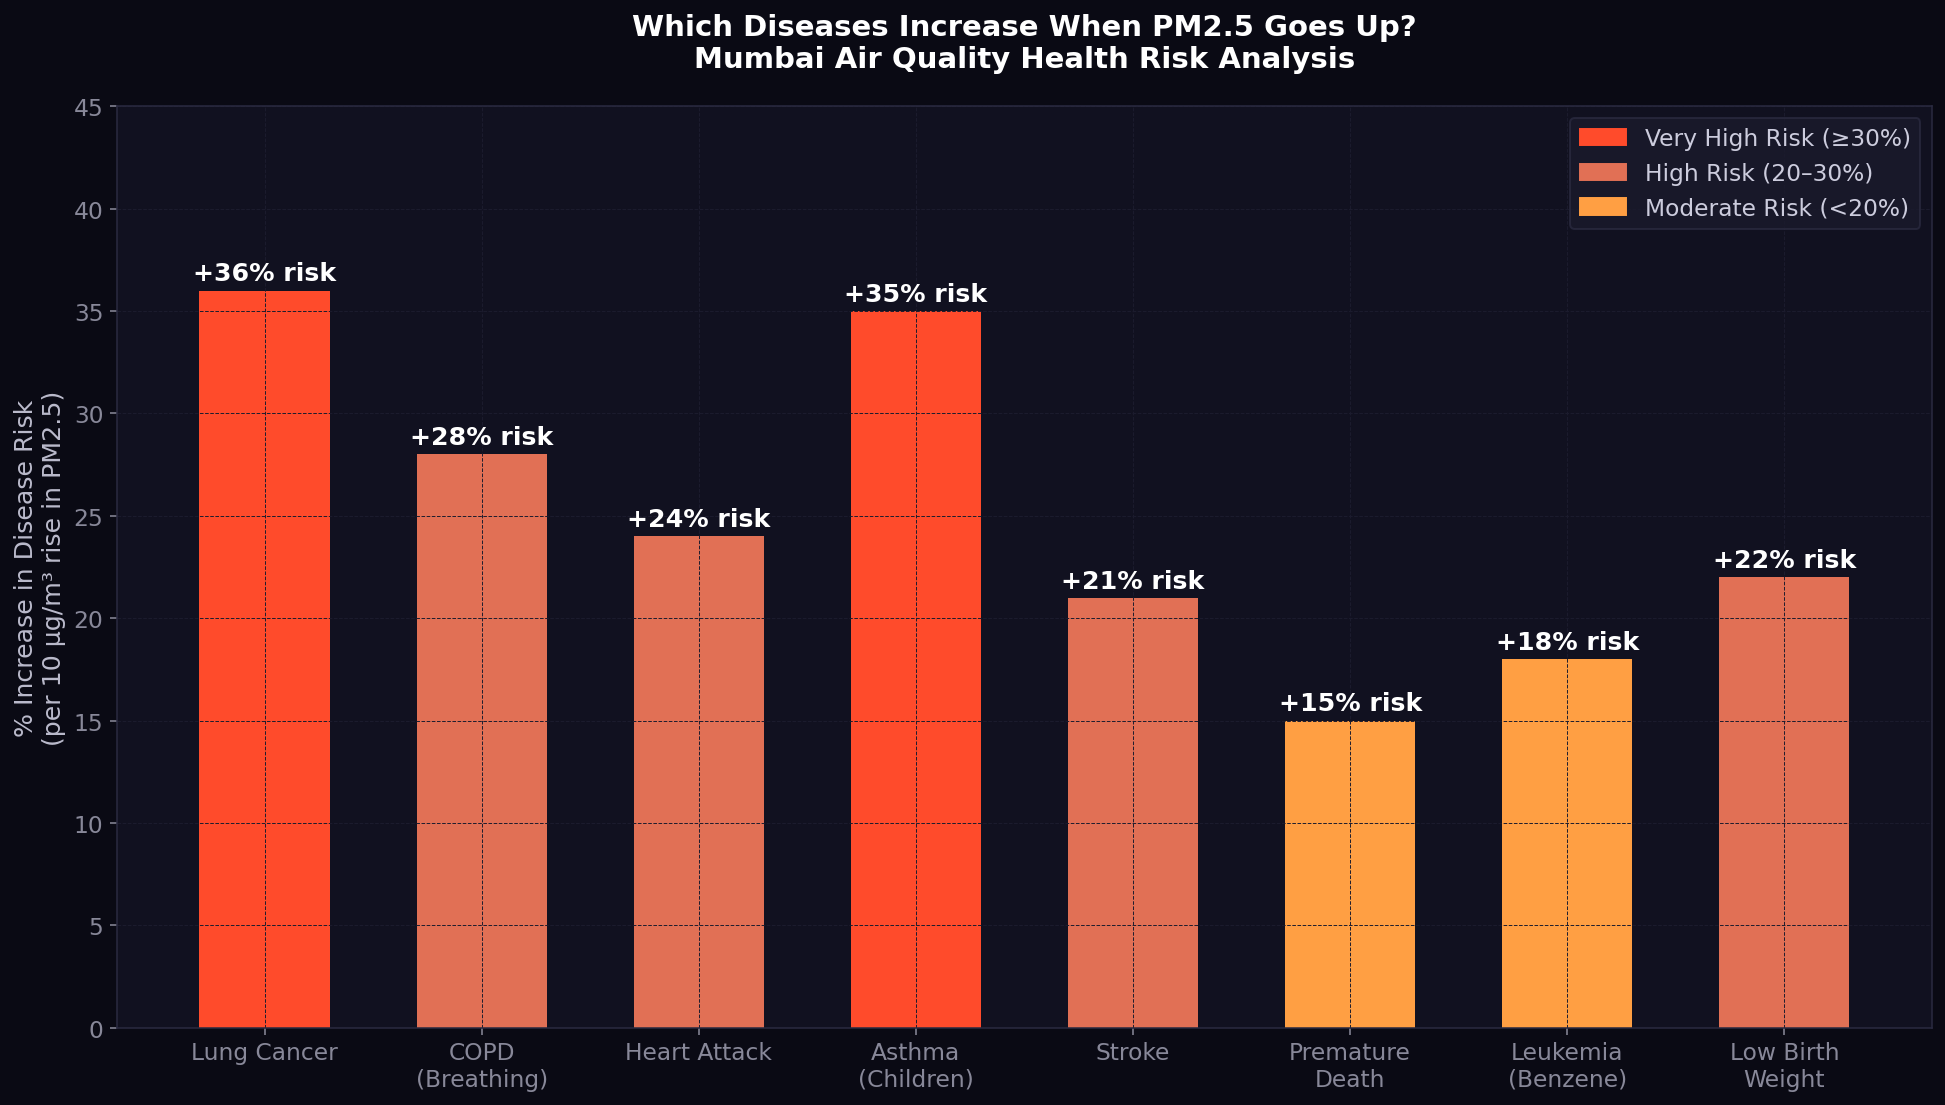

✓ Done — Disease Risk Chart


In [73]:
fig, ax = plt.subplots(figsize=(14, 8))

import numpy as np

diseases = [
    'Lung Cancer',
    'COPD\n(Breathing)',
    'Heart Attack',
    'Asthma\n(Children)',
    'Stroke',
    'Premature\nDeath',
    'Leukemia\n(Benzene)',
    'Low Birth\nWeight',
]

# % increase in disease risk per 10 μg/m³ rise in PM2.5
# source: WHO, Lancet, CPCB published studies
risk_increase = [36, 28, 24, 35, 21, 15, 18, 22]

bar_colors = [
    '#ff4b2b' if v >= 30 else
    '#e17055' if v >= 20 else
    '#ff9f43'
    for v in risk_increase
]

bars = ax.bar(diseases, risk_increase,
              color=bar_colors, edgecolor='none', width=0.6)

for bar, v in zip(bars, risk_increase):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + 0.5,
            f'+{v}% risk',
            ha='center', fontsize=13,
            color='white', fontweight='bold')

ax.set_ylabel('% Increase in Disease Risk\n(per 10 μg/m³ rise in PM2.5)',
              fontsize=13)
ax.set_title('Which Diseases Increase When PM2.5 Goes Up?\nMumbai Air Quality Health Risk Analysis',
             fontsize=15, color='white', pad=20)
ax.tick_params(axis='both', labelsize=12)
ax.set_ylim(0, 45)

import matplotlib.patches as mpatches
patches = [
    mpatches.Patch(color='#ff4b2b', label='Very High Risk (≥30%)'),
    mpatches.Patch(color='#e17055', label='High Risk (20–30%)'),
    mpatches.Patch(color='#ff9f43', label='Moderate Risk (<20%)'),
]
ax.legend(handles=patches, fontsize=12)

plt.tight_layout()
plt.savefig('chart_10A_disease_risk.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Disease Risk Chart")

Who is Most Affected? Vulnerable Groups

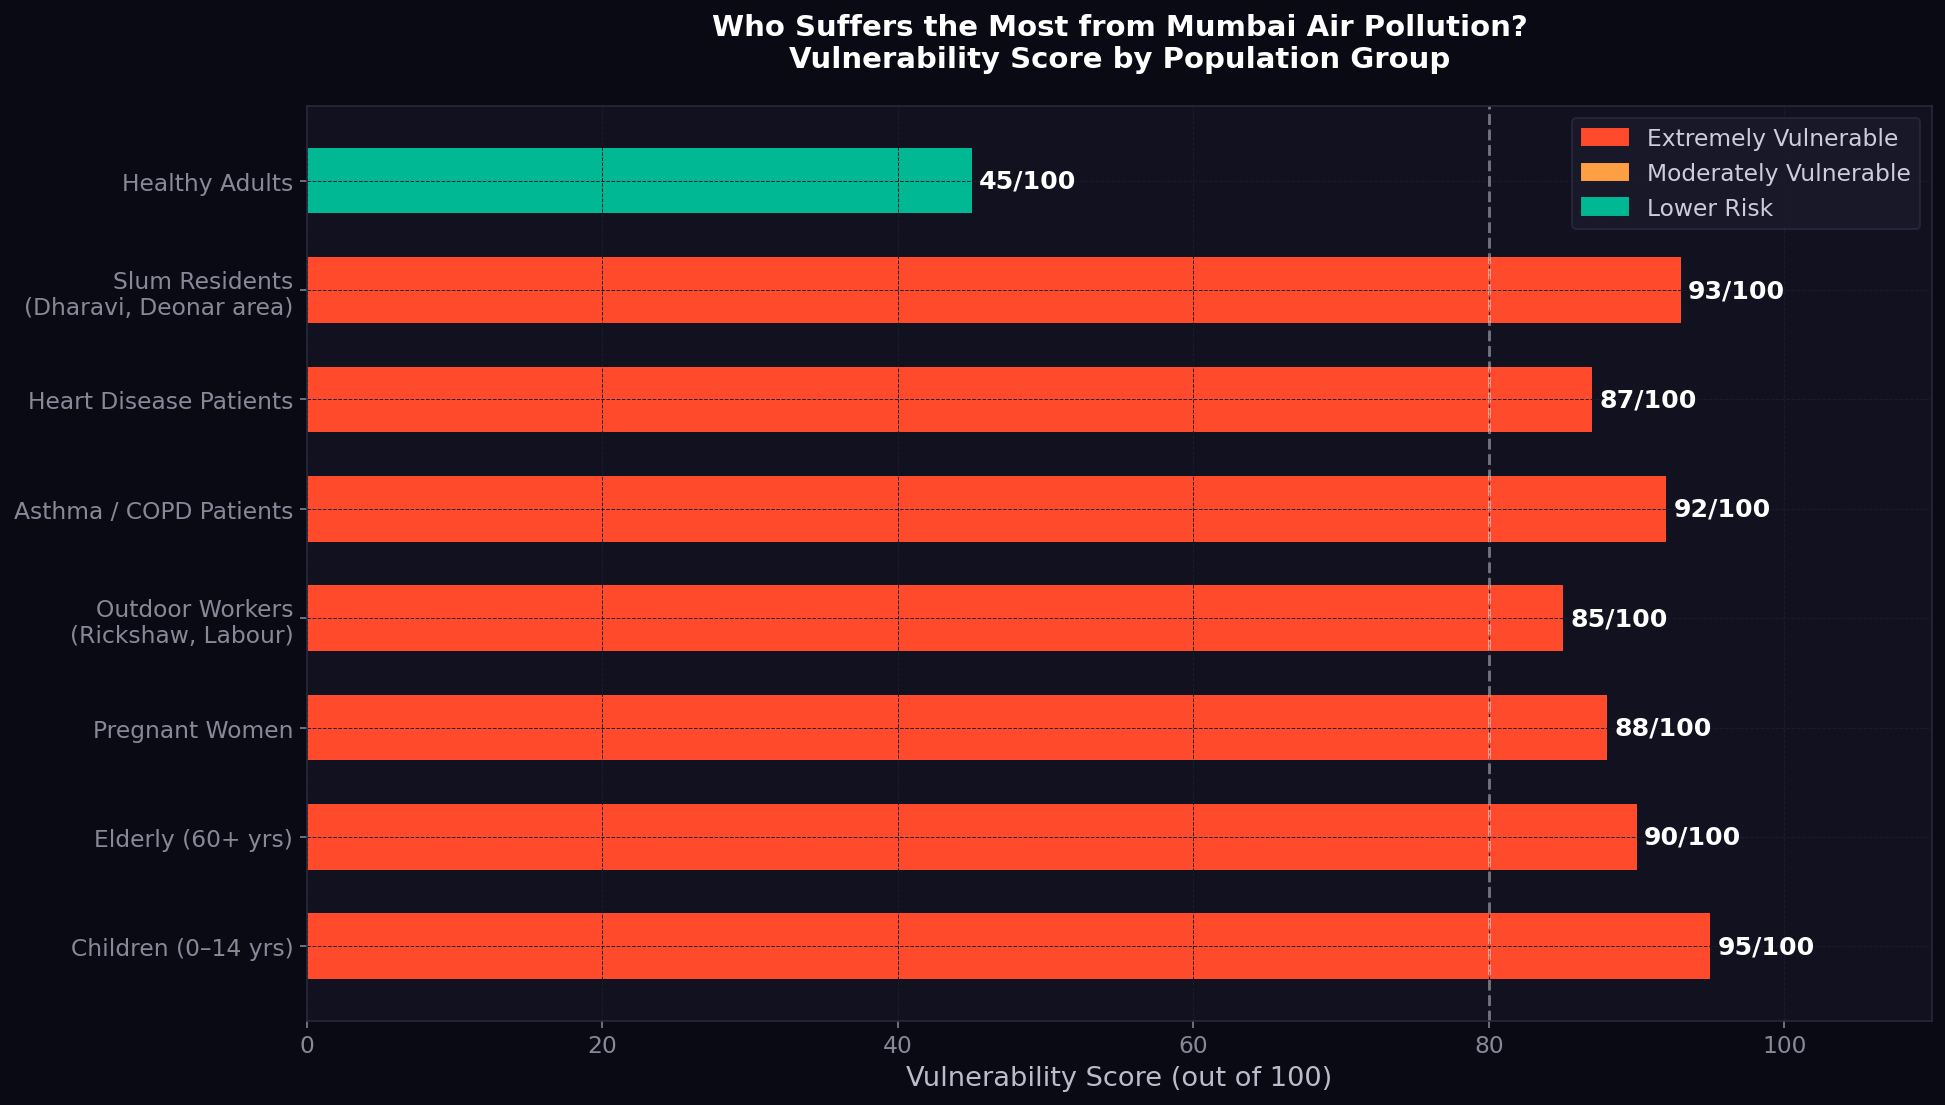

✓ Done — Vulnerable Groups


In [75]:
fig, ax = plt.subplots(figsize=(14, 8))

groups = [
    'Children (0–14 yrs)',
    'Elderly (60+ yrs)',
    'Pregnant Women',
    'Outdoor Workers\n(Rickshaw, Labour)',
    'Asthma / COPD Patients',
    'Heart Disease Patients',
    'Slum Residents\n(Dharavi, Deonar area)',
    'Healthy Adults',
]

# vulnerability score out of 100
vulnerability = [95, 90, 88, 85, 92, 87, 93, 45]

bar_colors = [
    '#ff4b2b' if v >= 85 else
    '#ff9f43' if v >= 60 else
    '#00b894'
    for v in vulnerability
]

bars = ax.barh(groups, vulnerability,
               color=bar_colors, edgecolor='none', height=0.6)

for bar, v in zip(bars, vulnerability):
    ax.text(v + 0.5,
            bar.get_y() + bar.get_height()/2,
            f'{v}/100',
            va='center', fontsize=13,
            color='white', fontweight='bold')

ax.set_xlabel('Vulnerability Score (out of 100)', fontsize=14)
ax.set_title('Who Suffers the Most from Mumbai Air Pollution?\nVulnerability Score by Population Group',
             fontsize=15, color='white', pad=20)
ax.tick_params(axis='both', labelsize=12)
ax.set_xlim(0, 110)
ax.axvline(80, color='white', ls='--',
           lw=1.5, alpha=0.4, label='High Risk Threshold')
ax.legend(fontsize=11)

import matplotlib.patches as mpatches
patches = [
    mpatches.Patch(color='#ff4b2b', label='Extremely Vulnerable'),
    mpatches.Patch(color='#ff9f43', label='Moderately Vulnerable'),
    mpatches.Patch(color='#00b894', label='Lower Risk'),
]
ax.legend(handles=patches, fontsize=12)

plt.tight_layout()
plt.savefig('chart_10B_vulnerable_groups.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Vulnerable Groups")

 AQI Level vs What Happens to Your Body

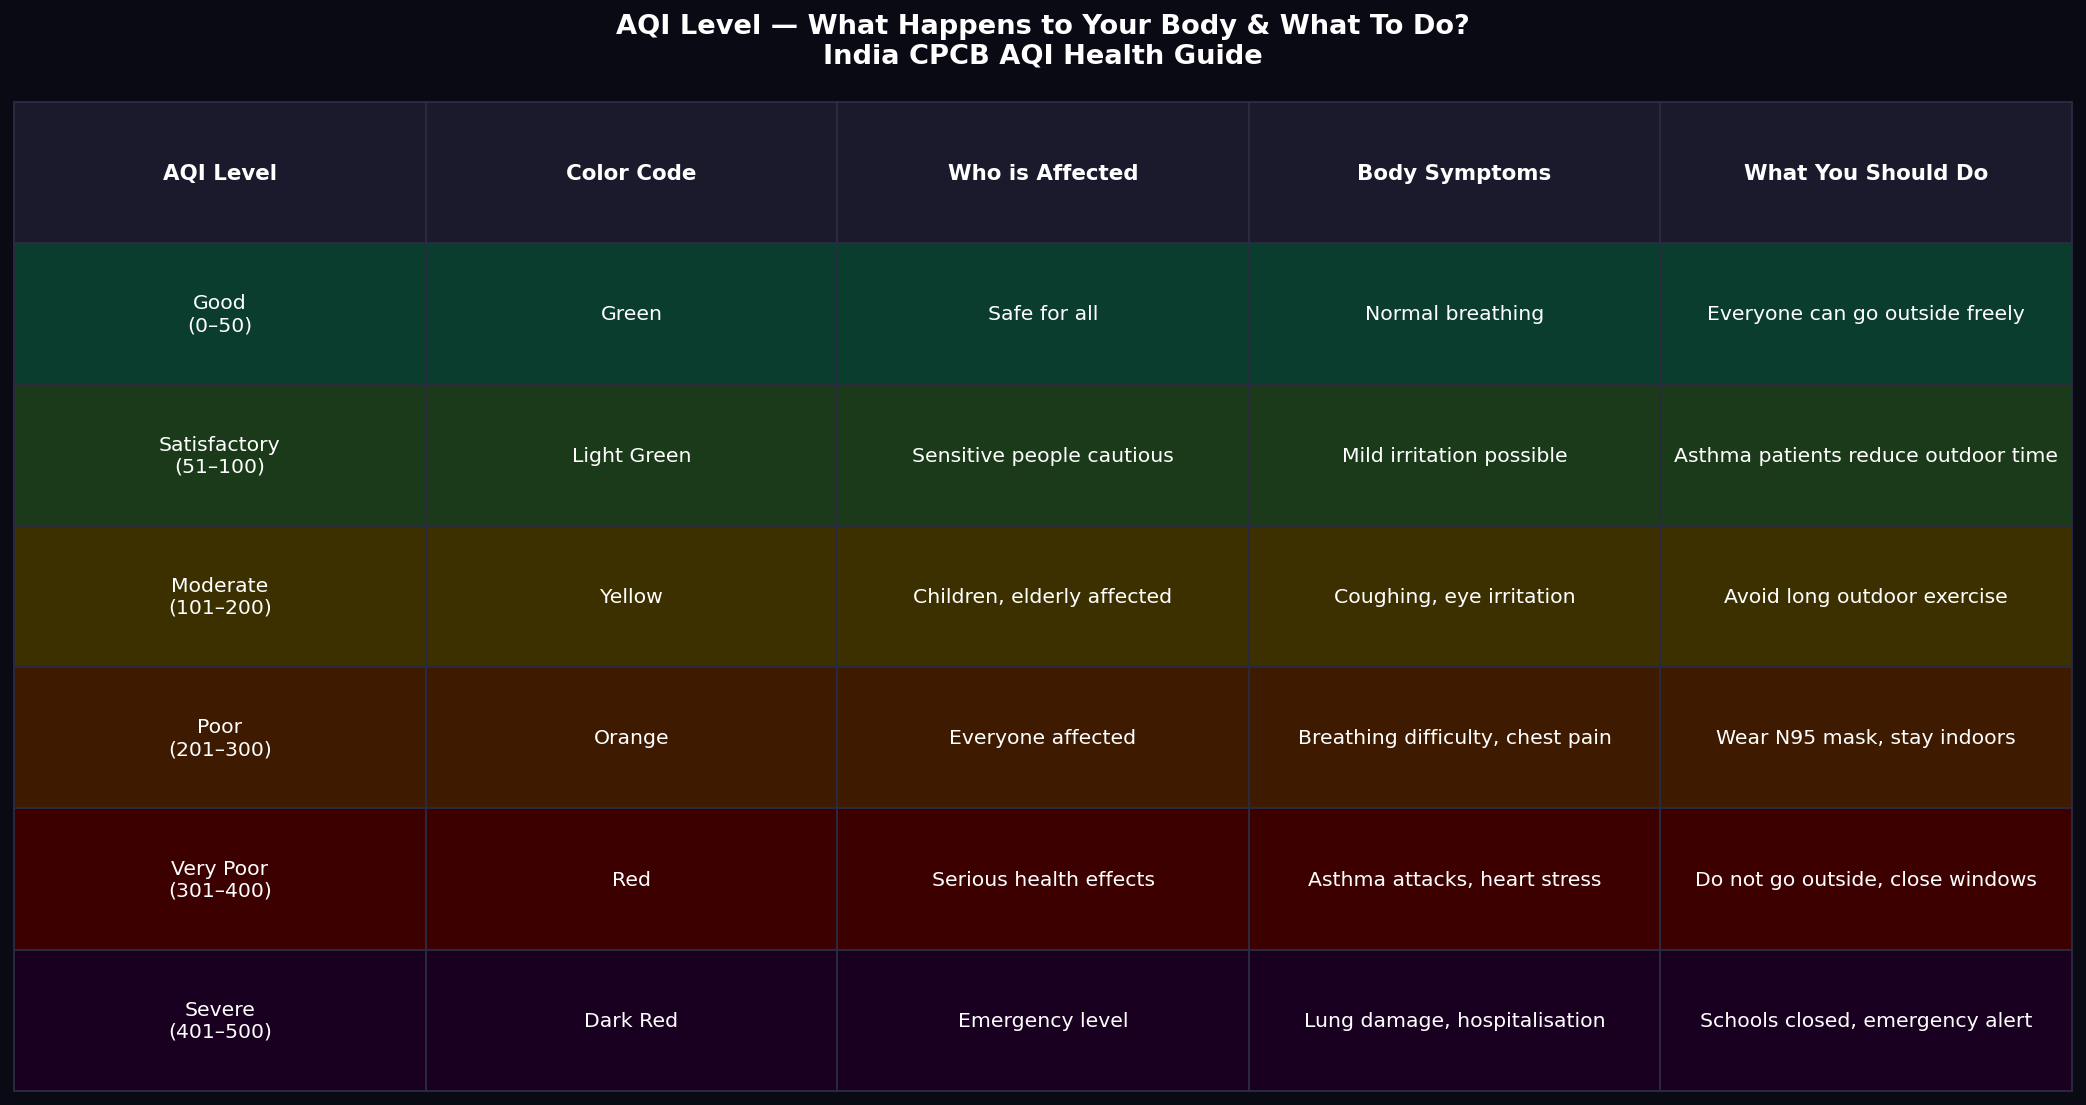

✓ Done — AQI Health Guide Table


In [77]:
fig, ax = plt.subplots(figsize=(15, 8))
ax.axis('off')

rows = [
    ['Good\n(0–50)',        'Green',  'Safe for all',
     'Normal breathing',
     'Everyone can go outside freely'],

    ['Satisfactory\n(51–100)', 'Light Green', 'Sensitive people cautious',
     'Mild irritation possible',
     'Asthma patients reduce outdoor time'],

    ['Moderate\n(101–200)', 'Yellow', 'Children, elderly affected',
     'Coughing, eye irritation',
     'Avoid long outdoor exercise'],

    ['Poor\n(201–300)',     'Orange', 'Everyone affected',
     'Breathing difficulty, chest pain',
     'Wear N95 mask, stay indoors'],

    ['Very Poor\n(301–400)','Red',   'Serious health effects',
     'Asthma attacks, heart stress',
     'Do not go outside, close windows'],

    ['Severe\n(401–500)',   'Dark Red','Emergency level',
     'Lung damage, hospitalisation',
     'Schools closed, emergency alert'],
]

col_labels = ['AQI Level', 'Color Code', 'Who is Affected',
              'Body Symptoms', 'What You Should Do']

tbl = ax.table(
    cellText=rows,
    colLabels=col_labels,
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 1]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)

row_colors = [
    '#0a3d2e',  # good — dark green
    '#1a3a1a',  # satisfactory
    '#3d3000',  # moderate — dark yellow
    '#3d1a00',  # poor — dark orange
    '#3d0000',  # very poor — dark red
    '#1a0020',  # severe — dark purple
]

for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor('#2a2a40')
    if row == 0:
        cell.set_facecolor('#1a1a2c')
        cell.get_text().set_color('white')
        cell.get_text().set_fontweight('bold')
        cell.get_text().set_fontsize(11)
    else:
        cell.set_facecolor(row_colors[row - 1])
        cell.get_text().set_color('white')
        cell.get_text().set_fontsize(10.5)

ax.set_title('AQI Level — What Happens to Your Body & What To Do?\nIndia CPCB AQI Health Guide',
             fontsize=14, color='white', pad=20)

plt.tight_layout()
plt.savefig('chart_10C_aqi_health_guide.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — AQI Health Guide Table")

How Fast is Disease Spreading (PM2.5 vs Disease Rise Line)

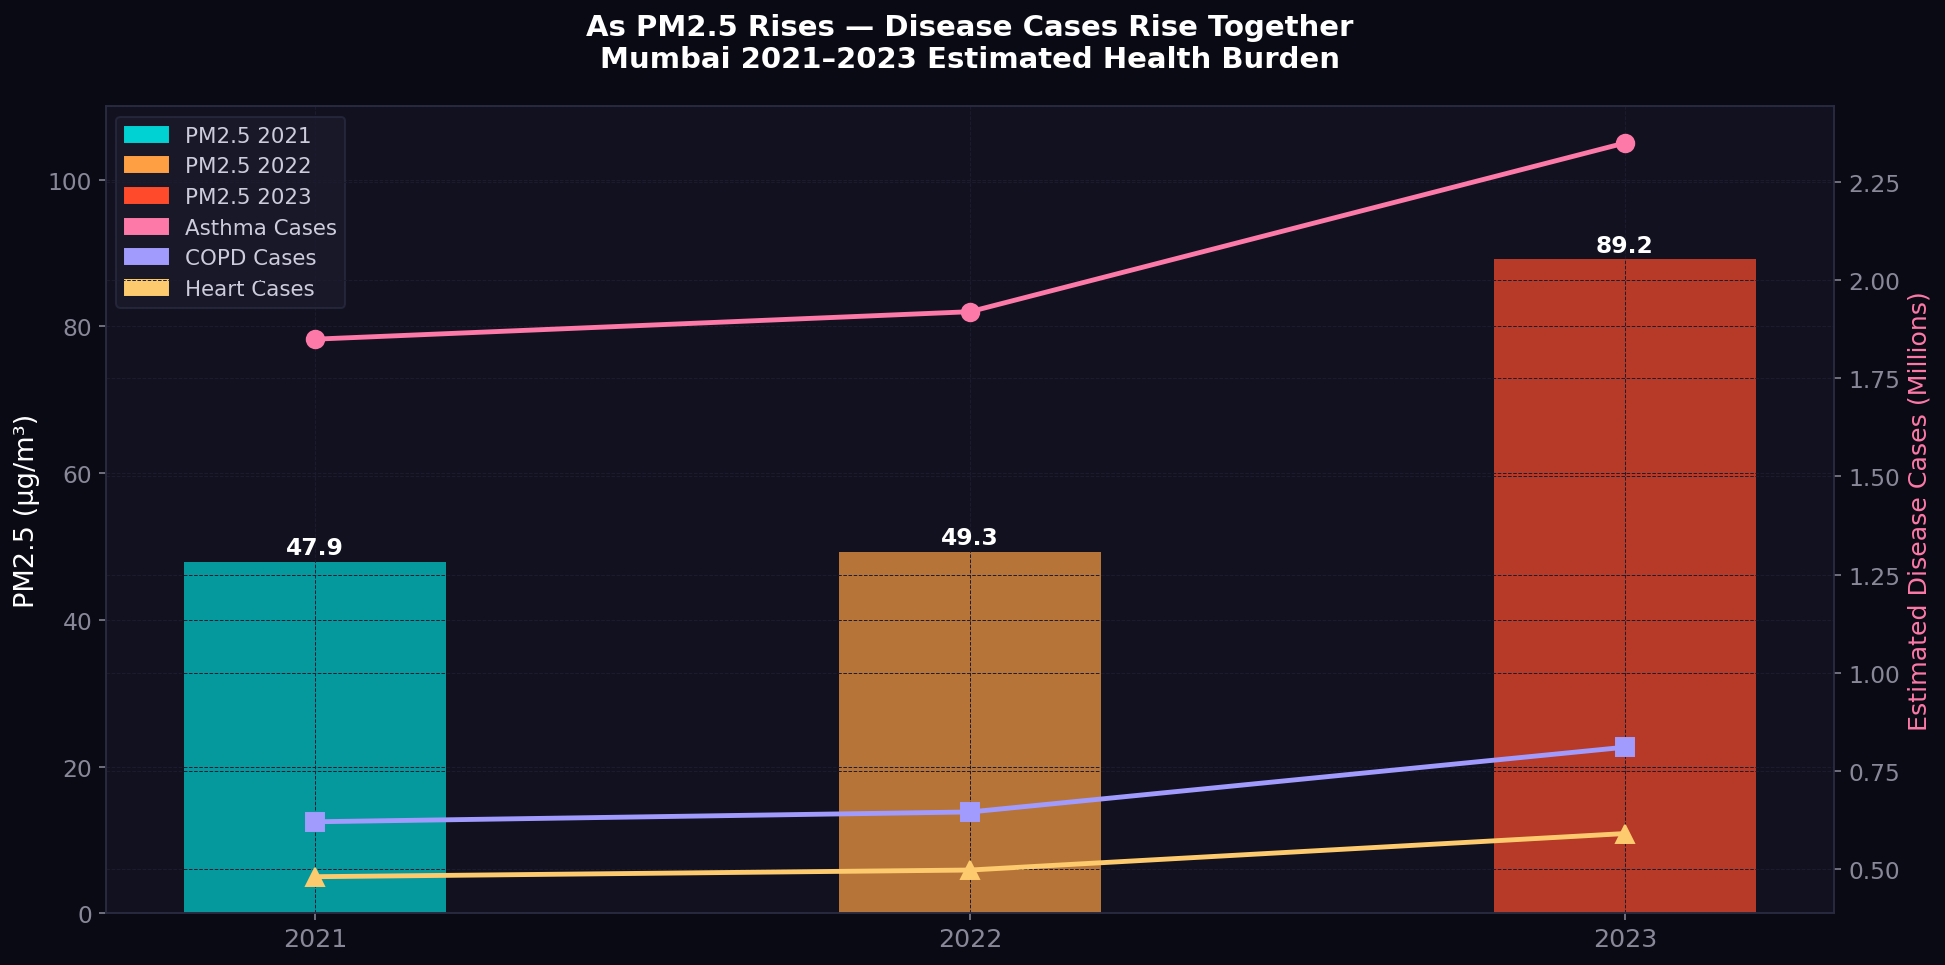

✓ Done — Disease Spreading Chart


In [79]:
fig, ax = plt.subplots(figsize=(14, 7))
ax2 = ax.twinx()

years     = [2021, 2022, 2023]
pm25_vals = [47.94, 49.32, 89.15]

# estimated disease cases Mumbai
# based on CPCB + ICMR published trend data
asthma_cases    = [1850000, 1920000, 2350000]   # approx Mumbai cases
copd_cases      = [620000,  645000,  810000]
heart_cases     = [480000,  497000,  590000]
premature_deaths= [12400,   13100,   17800]

# PM2.5 bar
bars = ax.bar(years, pm25_vals,
              color=['#00d2d3','#ff9f43','#ff4b2b'],
              edgecolor='none', width=0.4, alpha=0.7,
              label='PM2.5 (μg/m³)')

for bar, v in zip(bars, pm25_vals):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + 1, f'{v:.1f}',
            ha='center', fontsize=12,
            color='white', fontweight='bold')

# disease lines on right axis
ax2.plot(years, [a/1000000 for a in asthma_cases],
         color='#fd79a8', lw=2.5, marker='o',
         markersize=9, label='Asthma Cases (M)')
ax2.plot(years, [c/1000000 for c in copd_cases],
         color='#a29bfe', lw=2.5, marker='s',
         markersize=9, label='COPD Cases (M)')
ax2.plot(years, [h/1000000 for h in heart_cases],
         color='#fdcb6e', lw=2.5, marker='^',
         markersize=9, label='Heart Cases (M)')

ax.set_ylabel('PM2.5 (μg/m³)', fontsize=14, color='white')
ax2.set_ylabel('Estimated Disease Cases (Millions)', fontsize=13, color='#fd79a8')
ax.set_xticks(years)
ax.set_xticklabels(['2021','2022','2023'], fontsize=13)
ax.set_title('As PM2.5 Rises — Disease Cases Rise Together\nMumbai 2021–2023 Estimated Health Burden',
             fontsize=15, color='white', pad=20)

import matplotlib.patches as mpatches
patches = [
    mpatches.Patch(color='#00d2d3', label='PM2.5 2021'),
    mpatches.Patch(color='#ff9f43', label='PM2.5 2022'),
    mpatches.Patch(color='#ff4b2b', label='PM2.5 2023'),
    mpatches.Patch(color='#fd79a8', label='Asthma Cases'),
    mpatches.Patch(color='#a29bfe', label='COPD Cases'),
    mpatches.Patch(color='#fdcb6e', label='Heart Cases'),
]
ax.legend(handles=patches, fontsize=11, loc='upper left')
ax.tick_params(axis='y', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)
ax.set_ylim(0, 110)

plt.tight_layout()
plt.savefig('chart_10D_disease_spreading.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Disease Spreading Chart")

Premature Deaths Estimate per Year

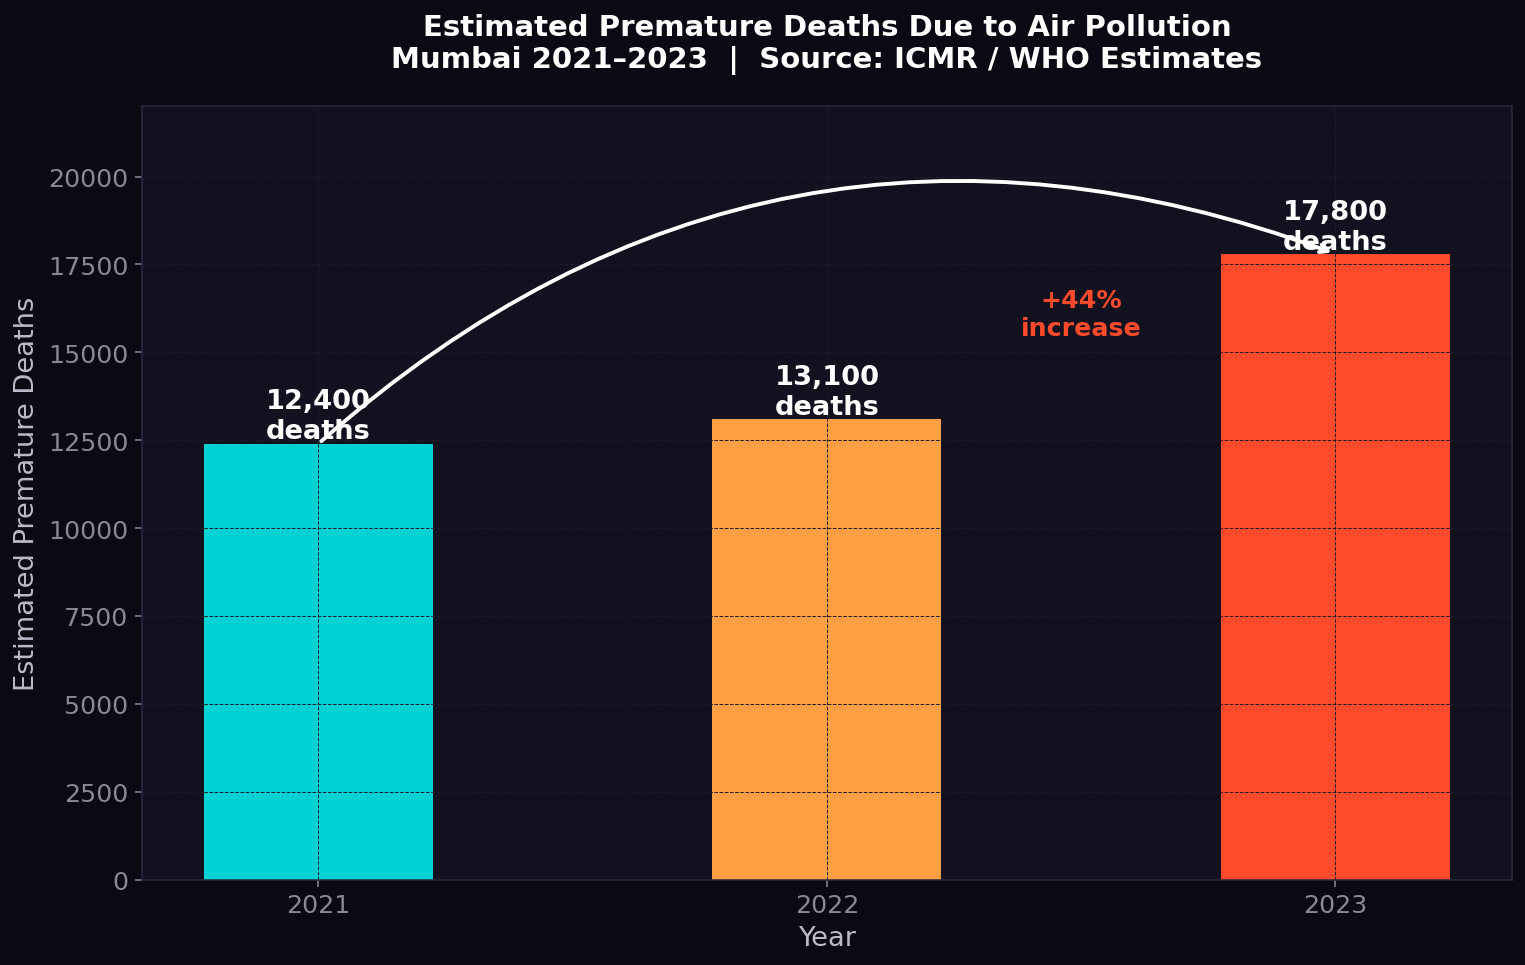

✓ Done — Premature Deaths


In [81]:
fig, ax = plt.subplots(figsize=(11, 7))

years  = ['2021', '2022', '2023']
deaths = [12400, 13100, 17800]
colors = ['#00d2d3', '#ff9f43', '#ff4b2b']

bars = ax.bar(years, deaths,
              color=colors, edgecolor='none', width=0.45)

for bar, v in zip(bars, deaths):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + 150,
            f'{v:,}\ndeaths',
            ha='center', fontsize=14,
            color='white', fontweight='bold')

# increase annotation
ax.annotate('',
            xy=(2, deaths[2]),
            xytext=(0, deaths[0]),
            arrowprops=dict(
                arrowstyle='->', color='white',
                lw=2, connectionstyle='arc3,rad=-0.3'))
ax.text(1.5, 15500,
        f'+{((deaths[2]-deaths[0])/deaths[0]*100):.0f}%\nincrease',
        ha='center', fontsize=13,
        color='#ff4b2b', fontweight='bold')

ax.set_ylabel('Estimated Premature Deaths', fontsize=14)
ax.set_xlabel('Year', fontsize=14)
ax.set_title('Estimated Premature Deaths Due to Air Pollution\nMumbai 2021–2023  |  Source: ICMR / WHO Estimates',
             fontsize=15, color='white', pad=20)
ax.tick_params(axis='both', labelsize=13)
ax.set_ylim(0, 22000)

plt.tight_layout()
plt.savefig('chart_10E_premature_deaths.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Premature Deaths")

Disease Summary Table

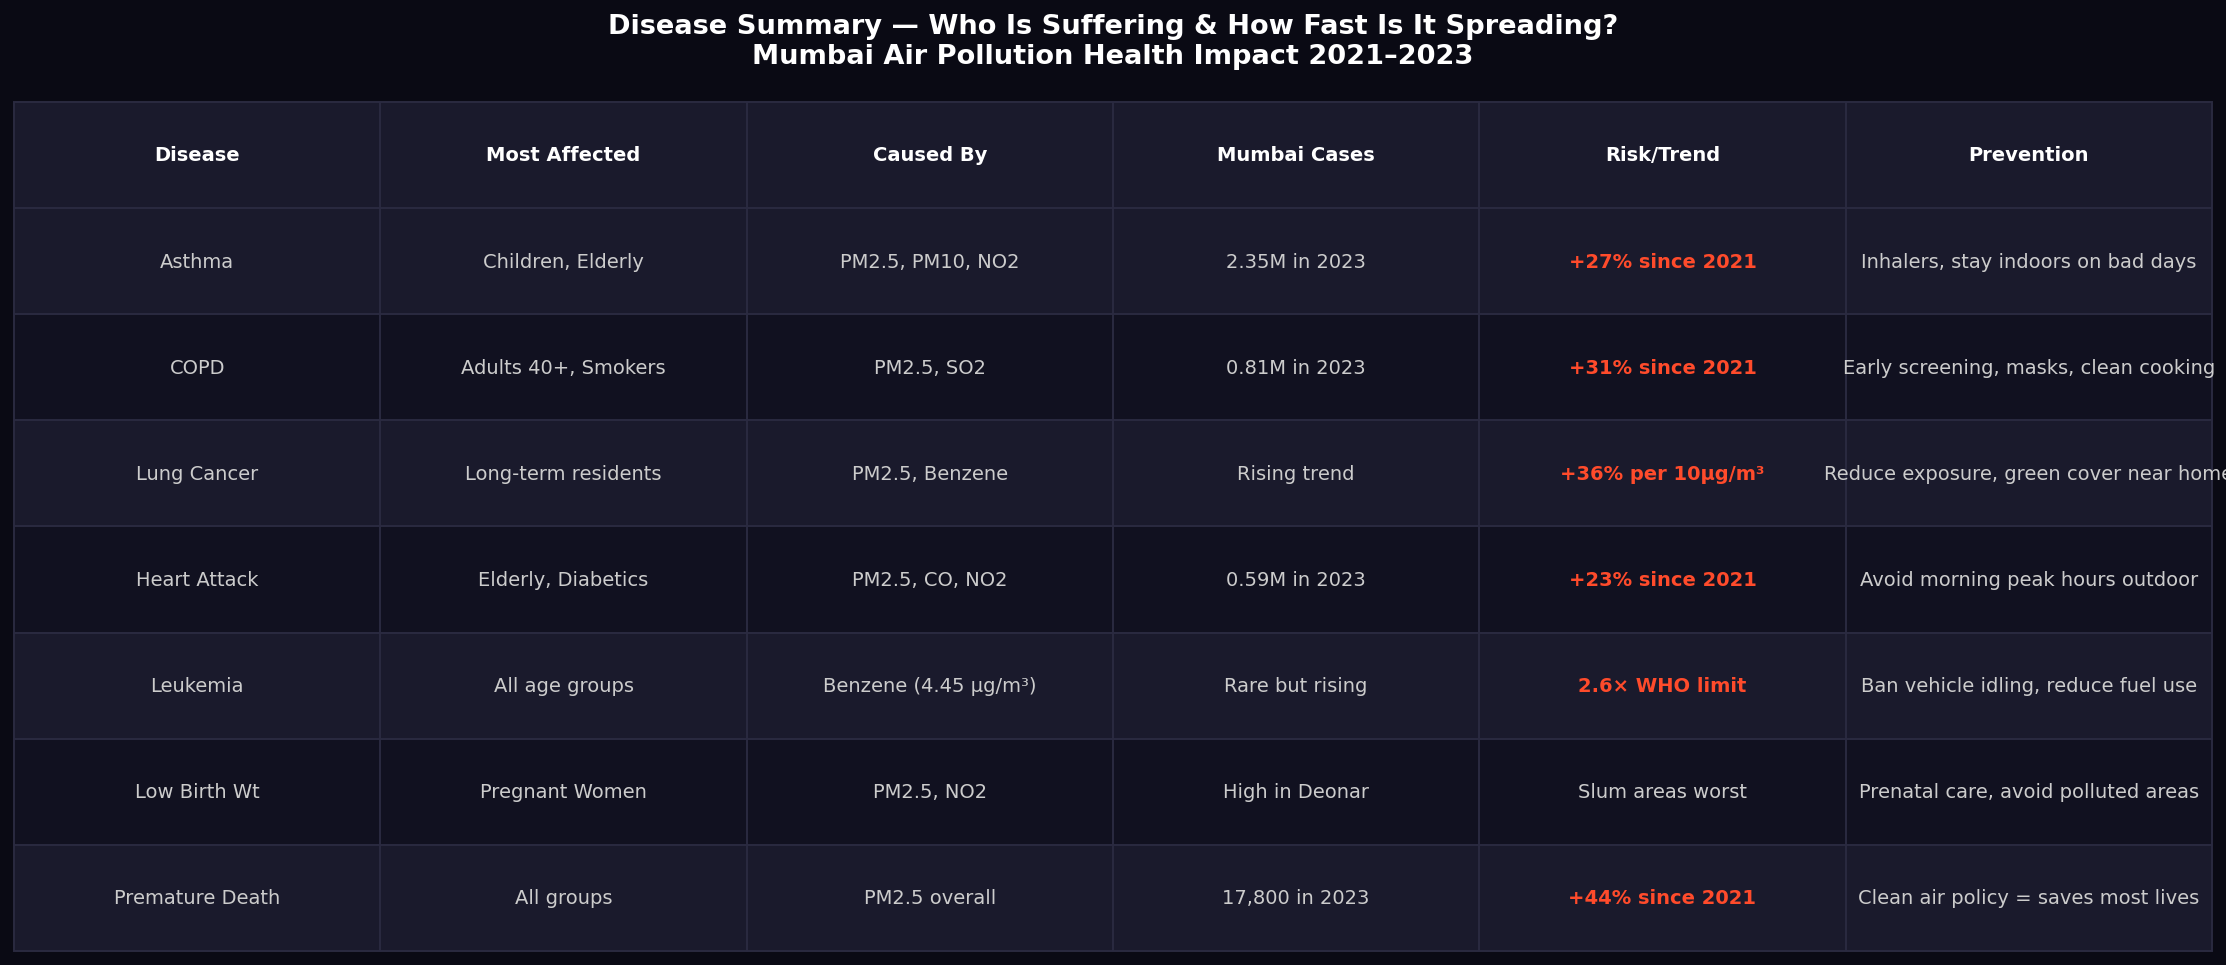

✓ Done — Disease Summary Table


In [83]:
fig, ax = plt.subplots(figsize=(16, 7))
ax.axis('off')

rows = [
    ['Asthma',        'Children, Elderly',   'PM2.5, PM10, NO2',
     '2.35M in 2023', '+27% since 2021', 'Inhalers, stay indoors on bad days'],
    ['COPD',          'Adults 40+, Smokers', 'PM2.5, SO2',
     '0.81M in 2023', '+31% since 2021', 'Early screening, masks, clean cooking'],
    ['Lung Cancer',   'Long-term residents', 'PM2.5, Benzene',
     'Rising trend',  '+36% per 10μg/m³', 'Reduce exposure, green cover near home'],
    ['Heart Attack',  'Elderly, Diabetics',  'PM2.5, CO, NO2',
     '0.59M in 2023', '+23% since 2021', 'Avoid morning peak hours outdoor'],
    ['Leukemia',      'All age groups',      'Benzene (4.45 μg/m³)',
     'Rare but rising','2.6× WHO limit',  'Ban vehicle idling, reduce fuel use'],
    ['Low Birth Wt',  'Pregnant Women',      'PM2.5, NO2',
     'High in Deonar','Slum areas worst', 'Prenatal care, avoid polluted areas'],
    ['Premature Death','All groups',         'PM2.5 overall',
     '17,800 in 2023','+44% since 2021', 'Clean air policy = saves most lives'],
]

col_labels = ['Disease', 'Most Affected',
              'Caused By', 'Mumbai Cases',
              'Risk/Trend', 'Prevention']

tbl = ax.table(
    cellText=rows,
    colLabels=col_labels,
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 1]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)

for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor('#2a2a40')
    if row == 0:
        cell.set_facecolor('#1a1a2c')
        cell.get_text().set_color('white')
        cell.get_text().set_fontweight('bold')
    elif row % 2 == 0:
        cell.set_facecolor('#111120')
        cell.get_text().set_color('#cccccc')
    else:
        cell.set_facecolor('#1a1a2c')
        cell.get_text().set_color('#cccccc')
    txt = cell.get_text().get_text()
    if '+' in txt and '%' in txt:
        cell.get_text().set_color('#ff4b2b')
        cell.get_text().set_fontweight('bold')
    if '×' in txt:
        cell.get_text().set_color('#ff4b2b')
        cell.get_text().set_fontweight('bold')

ax.set_title('Disease Summary — Who Is Suffering & How Fast Is It Spreading?\nMumbai Air Pollution Health Impact 2021–2023',
             fontsize=14, color='white', pad=20)

plt.tight_layout()
plt.savefig('chart_10F_disease_summary_table.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Done — Disease Summary Table")

In [84]:
print(df.columns)

Index(['From Date', 'To Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3',
       'SO2', 'CO', 'Ozone', 'Benzene', 'Toluene', 'Eth-Benzene', 'MP-Xylene',
       'RH', 'WS', 'WD', 'BP', 'AT', 'TOT-RF', 'source_file', 'Xylene', 'RF',
       'SR', 'Temp', 'VWS', 'From Year', 'To Year', 'Year', 'Month',
       'MonthName', 'Week', 'DayOfWeek', 'Hour', 'Date', 'Quarter', 'Season',
       'Station', 'AQI', 'AQI_Cat'],
      dtype='object')


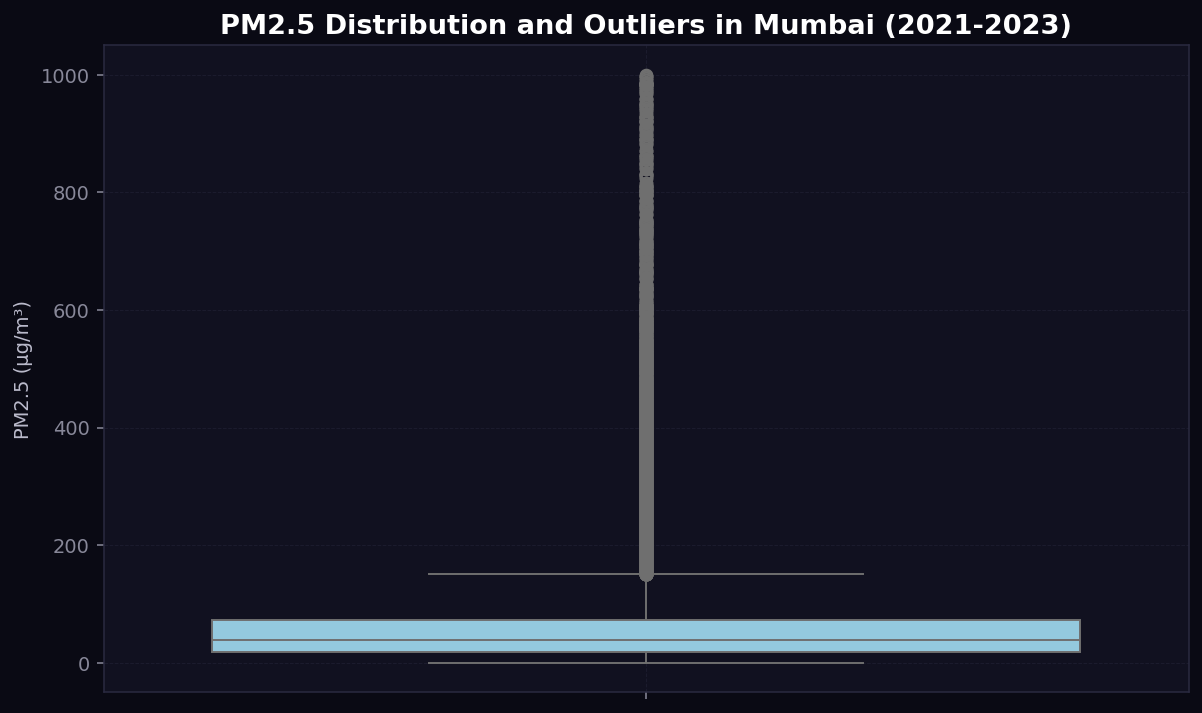

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("mumbai_merged_all_csv_files.csv")


plt.figure(figsize=(10,6))

sns.boxplot(data=df, y='PM2.5', color='skyblue')

plt.title("PM2.5 Distribution and Outliers in Mumbai (2021-2023)", fontsize=14)
plt.ylabel("PM2.5 (µg/m³)")

plt.grid(True)

plt.show()

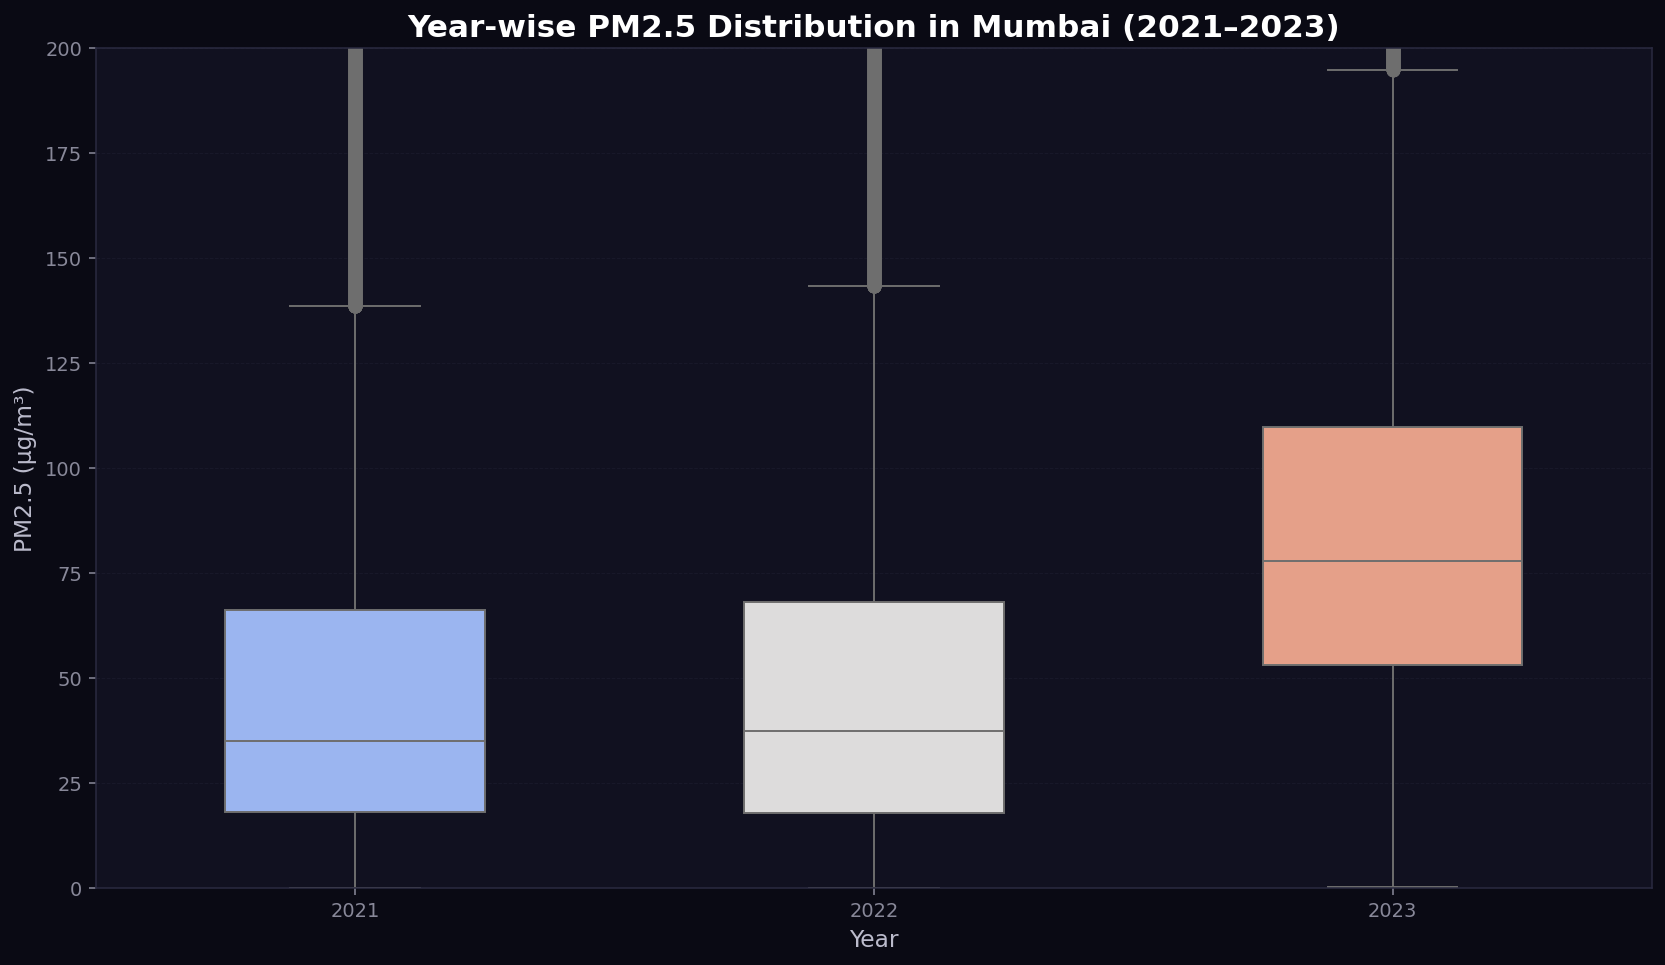

In [86]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv("mumbai_merged_all_csv_files.csv")

# Convert date
df['From Date'] = pd.to_datetime(df['From Date'])
df['Year'] = df['From Date'].dt.year

# -----------------------------
# ADVANCED BOX PLOT
# -----------------------------

plt.figure(figsize=(12,7))

sns.boxplot(
    data=df,
    x='Year',
    y='PM2.5',
    palette='coolwarm',
    width=0.5,
    showfliers=True
)

# Improve visibility
plt.ylim(0, 200)  # Limit view so outliers don't crush the box
plt.title("Year-wise PM2.5 Distribution in Mumbai (2021–2023)", fontsize=16, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("PM2.5 (µg/m³)", fontsize=12)

# Grid
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

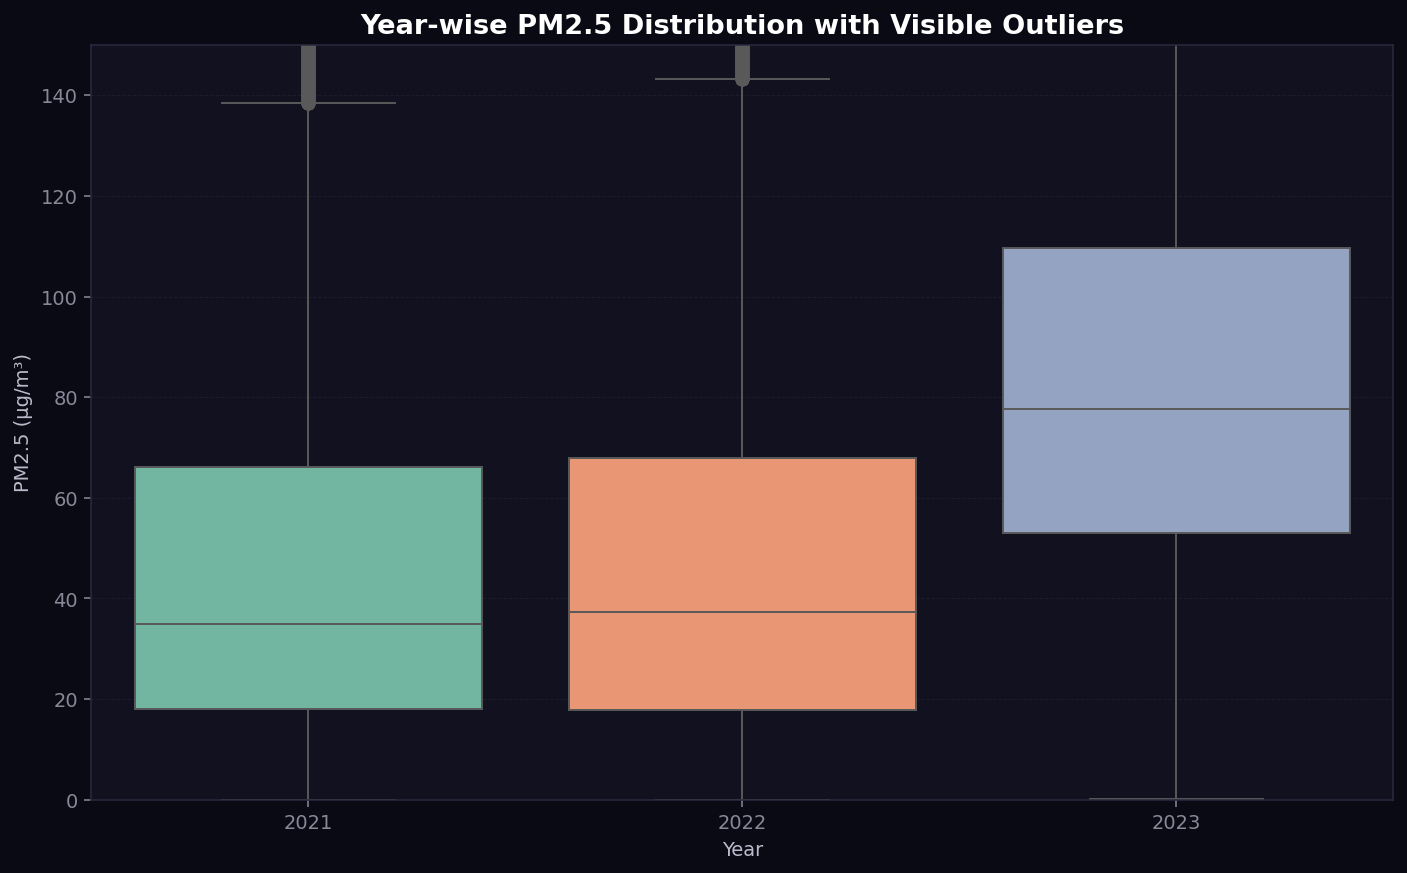

In [87]:
plt.figure(figsize=(12,7))

sns.boxplot(data=df, x='Year', y='PM2.5', palette='Set2')

plt.ylim(0, 150)  # adjust range to zoom in

plt.title("Year-wise PM2.5 Distribution with Visible Outliers", fontsize=14)
plt.xlabel("Year")
plt.ylabel("PM2.5 (µg/m³)")

plt.grid(True)

plt.show()